# Лекция 9. Alignment VLM по предпочтениям

Курс «Современное компьютерное зрение». Блокнот рассчитан на запуск в Google Colab (бесплатный GPU T4) и проверен на CPU в режиме `FAST_DEV_RUN`. Все ячейки уже выполнены, результаты сохранены: блокнот можно читать как учебник, не запуская.

В лекции 8 мы научились адаптировать VLM через supervised fine-tuning (SFT) и LoRA: модель получает пары «изображение + вопрос → эталонный ответ» и учится воспроизводить эталон. SFT хорошо задаёт формат и навык, но у него есть предел. Он показывает модели, что говорить, но не показывает, чего говорить не надо. Модель, обученная на корректных описаниях, всё равно иногда «видит» объекты, которых на изображении нет, удлиняет ответы и нарушает формат. Каждый токен эталона для SFT одинаково важен, и у неё нет способа сказать «вот этот ответ хуже вон того, и именно потому, что в нём выдуман синий круг».

Эта лекция про следующий этап: обучение по предпочтениям (preference optimization). Вместо одного правильного ответа мы показываем модели пару: какой ответ лучше (chosen) и какой хуже (rejected). Разберём классический RLHF с моделью вознаграждения и PPO, затем DPO, который решает ту же задачу без reinforcement learning, и его варианты IPO, KTO, ORPO и SimPO. Потом поговорим о данных: где для VLM брать «плохие» ответы и как не научить модель вместо правдивости длине или стилю. Отдельно обсудим борьбу с галлюцинациями, метрики (win rate, hallucination rate, соблюдение формата) и побочные эффекты: reward hacking, многословие и деградацию исходной задачи.

## Цели лекции

После лекции вы сможете:

1. Объяснить, чего не хватает SFT и почему сравнение двух ответов несёт другую информацию, чем один эталон.
2. Записать модель Брэдли–Терри, функцию потерь reward model и цель RLHF с KL-штрафом; вывести оптимальную политику этой цели в замкнутом виде.
3. Вывести функцию потерь DPO из этой формулы, объяснить смысл неявного вознаграждения, параметра $\beta$ и reference-модели, проанализировать градиент DPO.
4. Сравнить IPO, KTO, ORPO и SimPO с DPO: какую проблему решает каждый вариант, какие данные ему нужны, нужен ли reference.
5. Спроектировать preference-датасет для VLM: источники chosen и rejected, on-policy и синтетические негативы, контроль длины и стиля, проверка, что пары зависят от изображения.
6. Измерить результат alignment: win rate с доверительным интервалом и учётом ничьих, CHAIR и POPE для галлюцинаций, соблюдение формата, KL до reference.
7. Распознать reward hacking, рост многословия, падение правдоподобия chosen, деградацию исходной задачи, и знать, как каждое из них диагностировать и ограничить.

## Как устроен блокнот

Часть I — теория (разделы 1–10): от SFT к RLHF, вывод DPO, варианты, данные для VLM, галлюцинации, метрики, побочные эффекты, инструменты, рецепт и типичные ошибки.

Часть II — практикум (разделы 11–20). На синтетических сценах с цветными фигурами (у них известна полная разметка, поэтому галлюцинации считаются точно) мы:

- дообучим небольшую VLM SmolVLM через SFT и посмотрим, где она галлюцинирует;
- соберём три варианта preference-данных из её собственных ответов: «наивный», с контролем длины и стиля и намеренно смещённый по длине;
- реализуем с нуля функции потерь DPO, IPO, KTO, ORPO, SimPO и сравним их на игрушечной задаче, где оптимум известен;
- обучим reward model и устроим на ней best-of-n, чтобы увидеть reward hacking своими глазами;
- обучим несколько LoRA-адаптеров по предпочтениям и сравним их по win rate, hallucination rate, формату, длине, KL и POPE на реальных фотографиях COCO.

Все численные выводы в тексте практикума взяты из сохранённого прогона. На GPU выборки в несколько раз больше, поэтому числа будут другими; важны направления эффектов и способы их измерить.

## Связь с другими лекциями

Лекция 6 дала устройство VLM и способы её оценки, включая POPE и CHAIR. Лекция 8 дала SFT, LoRA и проверку забывания. Эта лекция строится поверх них: политика-старт для preference optimization — это SFT-модель, LoRA снова используется как механизм обучения, а оценка забывания превращается в оценку «налога на alignment».

# Часть I. Теория

## 1. От SFT к обучению по предпочтениям

### 1.1. Что делает SFT и чего ему не хватает

Пусть $x$ — вход (изображение и текстовый запрос), $y = (y_1, \dots, y_T)$ — ответ. SFT минимизирует отрицательное логарифмическое правдоподобие эталона:

$$ \mathcal{L}_{\mathrm{SFT}}(\theta) = -\,\mathbb{E}_{(x, y) \sim \mathcal{D}} \sum_{t=1}^{T} \log \pi_\theta(y_t \mid x, y_{<t}). $$

Эта цель обладает тремя свойствами, которые важно понимать до перехода к предпочтениям.

1. Она только «тянет вверх». Градиент SFT увеличивает вероятность каждого токена эталона и ничего не говорит о том, какие ответы плохие. Вероятность «плохих» ответов уменьшается лишь косвенно, потому что сумма вероятностей равна единице. Если неверный ответ отличается от верного одним словом («синий квадрат» вместо «синего круга»), SFT почти не отличает их: все остальные токены у них общие.
2. Все токены равноправны. Ошибка в названии объекта весит в loss столько же, сколько вариация в служебном слове. Для галлюцинаций это плохо: важна именно одна ошибочная позиция.
3. Модель учится на чужих ответах. Эталон написан человеком или более сильной моделью, а не самой обучаемой моделью. При генерации модель попадает в состояния, которых не было в данных (так называемый exposure bias), и SFT не учит её выходить из них.

Отсюда идея: показать модели не только «как надо», но и «как не надо», причём на её собственных ошибках.

### 1.2. Почему сравнение проще оценки

Людям и моделям-судьям трудно поставить ответу абсолютную оценку по шкале, но легко сказать, какой из двух ответов лучше. Сравнения стабильнее между разметчиками и не требуют договариваться о шкале. Эту идею использовали ещё в работе [Christiano et al., 2017](https://arxiv.org/abs/1706.03741): агент в Atari и задачах управления роботом обучался по человеческим сравнениям пар фрагментов траекторий, причём отзывы требовались менее чем на 1% взаимодействий агента со средой. Затем подход перенесли на суммаризацию текста ([Stiennon et al., 2020](https://arxiv.org/abs/2009.01325)) и на инструкции в InstructGPT ([Ouyang et al., 2022](https://arxiv.org/abs/2203.02155)).

Одна запись preference-датасета — это тройка $(x, y_w, y_l)$: вход, предпочтённый ответ (winner, chosen) и отвергнутый ответ (loser, rejected). Информация пары — разница между ответами. Если ответы отличаются только наличием галлюцинации, пара учит именно правдивости. Если они отличаются также длиной, стилем, форматом, пара учит всему сразу, и модель не знает, что из этого важно. Этот тезис — центральный для всей лекции, мы вернёмся к нему в разделах 5 и 8.

### 1.3. Место preference optimization в конвейере

Типичная последовательность для VLM:

1. Предобучение: визуальный энкодер и языковая модель обучаются отдельно, затем коннектор сшивает их на парах «изображение — подпись».
2. SFT (instruction tuning): модель учится вести диалог, отвечать в нужном формате.
3. Preference optimization: модель учится выбирать лучшие из ответов, которые она уже умеет генерировать.

Важная практическая деталь: preference optimization почти всегда начинается с SFT-модели. Она же обычно служит reference-моделью (см. раздел 2.3). Если пропустить SFT, preference-сигнал вынужден учить сразу и формат, и качество, и обучение идёт хуже. Исключение — ORPO, которая объединяет SFT и preference в одну цель (раздел 4.3).

Что preference optimization не делает. Оно не добавляет модели новых знаний и не учит видеть лучше. Если визуальный энкодер не различает два оттенка, никакая пара предпочтений этого не исправит. Оно перераспределяет вероятность между ответами, которые модель уже может породить. Это ограничение согласуется с наблюдением [Gekhman et al., 2024](https://arxiv.org/abs/2405.05904) для языковых моделей: примеры с новыми фактами при дообучении усваиваются значительно медленнее, а по мере усвоения линейно увеличивают склонность модели к галлюцинациям.

## 2. RLHF: reward model и обучение с KL-штрафом

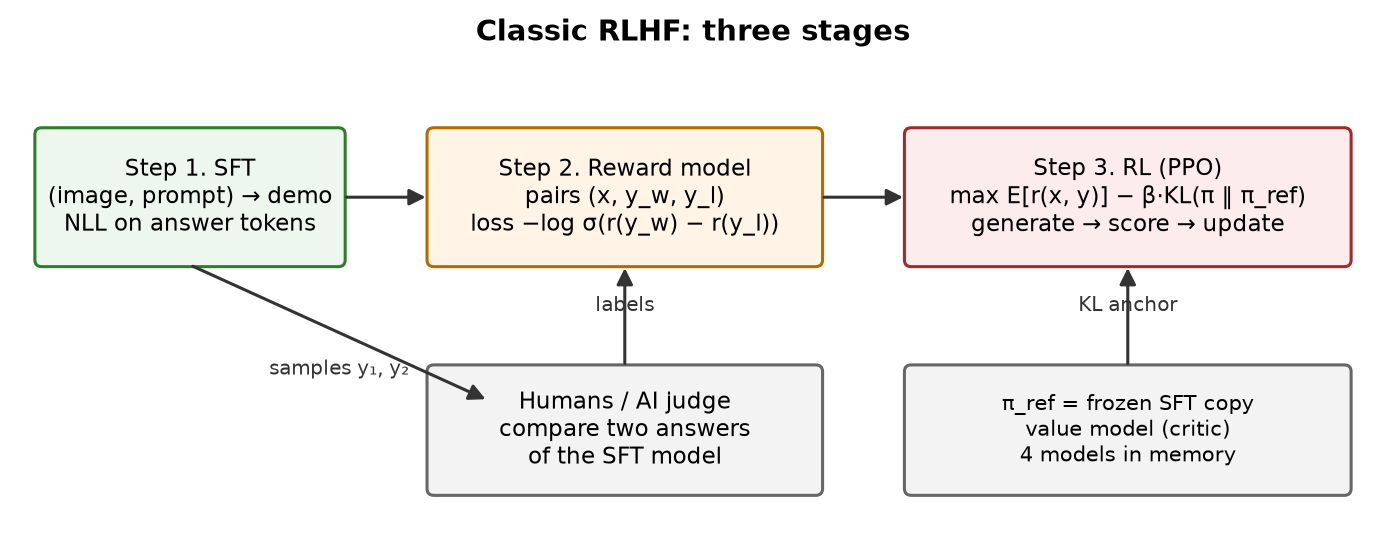

Классический RLHF ([Ouyang et al., 2022](https://arxiv.org/abs/2203.02155)) состоит из трёх шагов: SFT, обучение reward model по сравнениям, оптимизация политики по reward model алгоритмом PPO. В InstructGPT 1,3-миллиардная модель после этой процедуры оказалась предпочтительнее для людей, чем 175-миллиардная GPT-3, то есть при параметрах в 100 раз меньше ([Ouyang et al., 2022](https://arxiv.org/abs/2203.02155)).

### 2.1. Модель Брэдли–Терри

Предположим, у каждого ответа есть скрытая «полезность» $r^*(x, y)$, а человек выбирает ответ с шумом. Модель Брэдли–Терри задаёт вероятность того, что $y_1$ лучше $y_2$:

$$ p^*(y_1 \succ y_2 \mid x) = \frac{\exp r^*(x, y_1)}{\exp r^*(x, y_1) + \exp r^*(x, y_2)} = \sigma\big(r^*(x, y_1) - r^*(x, y_2)\big), $$

где $\sigma(z) = 1/(1 + e^{-z})$ — сигмоида. Два свойства:

- значение имеет только разность вознаграждений, поэтому $r^*$ определено с точностью до сдвига, который может зависеть от $x$: $r^*(x, y) + c(x)$ даёт те же вероятности;
- при разности 0 вероятность равна 0,5; при разности 2 — около 0,88; при разности 5 — около 0,993.

### 2.2. Обучение reward model

Reward model $r_\phi(x, y)$ — обычно та же языковая модель (или VLM), у которой вместо головы над словарём стоит скалярная голова поверх скрытого состояния последнего токена. Обучение — логистическая регрессия на разность:

$$ \mathcal{L}_{\mathrm{RM}}(\phi) = -\,\mathbb{E}_{(x, y_w, y_l)} \log \sigma\big(r_\phi(x, y_w) - r_\phi(x, y_l)\big). $$

Качество reward model измеряют точностью на отложенных парах: доля пар, где $r_\phi(x, y_w) > r_\phi(x, y_l)$. Эта точность обычно заметно ниже 100% даже на данных из того же распределения: сами разметчики согласуются между собой не идеально, и часть пар действительно спорная. Главная опасность в том, что RM учится по конечной выборке и оценивается затем на ответах, которые порождает оптимизируемая политика. Эти ответы постепенно уходят от распределения обучающих пар, и RM на них ошибается всё чаще. Это корень reward hacking (раздел 8).

### 2.3. Цель RLHF с KL-штрафом

Политику $\pi_\theta$ учат максимизировать вознаграждение, не уходя далеко от reference-политики $\pi_{\mathrm{ref}}$ (обычно SFT-модели):

$$ \max_{\pi_\theta} \; \mathbb{E}_{x \sim \mathcal{D},\, y \sim \pi_\theta(\cdot \mid x)} \big[ r_\phi(x, y) \big] \; - \; \beta \, \mathbb{D}_{\mathrm{KL}}\big( \pi_\theta(\cdot \mid x) \,\|\, \pi_{\mathrm{ref}}(\cdot \mid x) \big). $$

Зачем нужен KL-штраф:

- reward model надёжна только около распределения своих обучающих данных, а KL держит политику в этой окрестности;
- без штрафа политика схлопывается в один ответ с максимальной наградой, теряя разнообразие и беглость языка;
- штраф сохраняет то, что модель умела после SFT.

На практике штраф добавляют к награде за последовательность, а KL оценивают по сэмплам: $\tilde r(x, y) = r_\phi(x, y) - \beta \log \frac{\pi_\theta(y \mid x)}{\pi_{\mathrm{ref}}(y \mid x)}$.

### 2.4. Оптимальная политика в замкнутом виде

У этой задачи есть точное решение. Перепишем цель для фиксированного $x$ как минимизацию:

$$ \mathbb{E}_{y \sim \pi} \Big[ \log \frac{\pi(y \mid x)}{\pi_{\mathrm{ref}}(y \mid x)} - \frac{1}{\beta} r(x, y) \Big] = \mathbb{E}_{y \sim \pi} \Big[ \log \frac{\pi(y \mid x)}{\pi_{\mathrm{ref}}(y \mid x) \exp\!\big(r(x, y)/\beta\big)} \Big]. $$

Введём нормировочную константу $Z(x) = \sum_y \pi_{\mathrm{ref}}(y \mid x) \exp\!\big(r(x, y)/\beta\big)$ и распределение

$$ \pi^*(y \mid x) = \frac{1}{Z(x)} \, \pi_{\mathrm{ref}}(y \mid x) \exp\!\Big( \frac{1}{\beta} r(x, y) \Big). $$

Тогда цель равна $\mathbb{D}_{\mathrm{KL}}(\pi \,\|\, \pi^*) - \log Z(x)$. Второе слагаемое не зависит от $\pi$, а KL-дивергенция минимальна и равна нулю при $\pi = \pi^*$. Значит, $\pi^*$ — точный оптимум.

Смысл формулы: оптимальная политика — это reference, перевзвешенная экспонентой от награды. Параметр $\beta$ работает как температура. При большом $\beta$ политика почти совпадает с reference; при $\beta \to 0$ вся масса уходит на ответ с максимальной наградой. Важно: $\pi^*$ не может дать вероятность ответу, у которого $\pi_{\mathrm{ref}} = 0$. Alignment не создаёт новые ответы, а перераспределяет вероятность между существующими.

Почему не применить эту формулу напрямую? Потому что $Z(x)$ — сумма по всем возможным ответам, их экспоненциально много. Поэтому RLHF использует RL, а DPO (раздел 3) находит способ избавиться от $Z(x)$.

### 2.5. PPO в одном абзаце

Proximal Policy Optimization ([Schulman et al., 2017](https://arxiv.org/abs/1707.06347)) — алгоритм policy gradient, который ограничивает шаг обновления обрезанием отношения вероятностей новой и старой политики. В RLHF для языковой модели «эпизод» — это генерация ответа, а «действие» — токен. PPO требует держать в памяти четыре модели: обучаемую политику, reference, reward model и value-модель (critic), которая оценивает ожидаемую награду из текущего префикса. Кроме того, на каждом шаге нужно генерировать ответы. Это дорого и капризно: обучение чувствительно к нормировке наград, размеру батча и коэффициенту KL. В исследовании [Xu et al., 2024](https://arxiv.org/abs/2404.10719) показано, что хорошо настроенный PPO превосходит другие методы alignment во всех рассмотренных задачах, от диалога до соревновательного программирования; авторы выделяют ключевые факторы для его качества. То есть PPO не устарел, но требует опыта и ресурсов.

### 2.6. Best-of-n: alignment без обучения

Самый простой способ использовать reward model — сгенерировать $n$ ответов и выбрать лучший по $r_\phi$. Это best-of-n (BoN), или rejection sampling. Он не меняет веса модели и служит хорошим ориентиром: какое качество можно получить из имеющейся модели при данной RM. Для BoN известна аналитическая KL-дивергенция между распределением выбранного ответа и исходной политикой ([Gao et al., 2022](https://arxiv.org/abs/2210.10760)):

$$ \mathrm{KL}_{\mathrm{BoN}} = \log n - \frac{n-1}{n}. $$

При $n = 4$ это около 0,64 нат, при $n = 16$ — около 1,83, при $n = 64$ — около 3,17. KL растёт логарифмически по $n$, поэтому BoN — «мягкая» оптимизация. В практикуме (раздел 18) мы увидим, что даже она способна взломать плохую reward model.

## 3. DPO: прямая оптимизация предпочтений

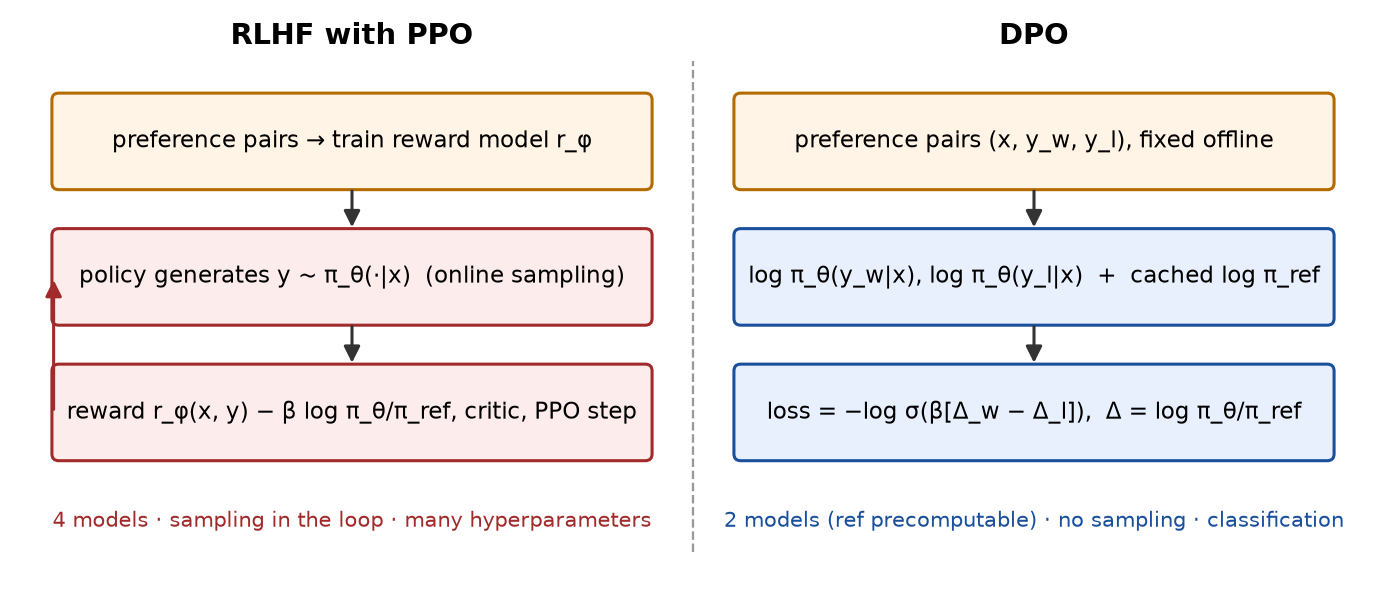

### 3.1. Вывод

Direct Preference Optimization ([Rafailov et al., 2023](https://arxiv.org/abs/2305.18290)) решает ту же задачу, что и RLHF с KL-штрафом, но без reward model и без RL. Идея в том, чтобы выразить награду через оптимальную политику. Возьмём логарифм формулы из раздела 2.4 и выразим $r$:

$$ r(x, y) = \beta \log \frac{\pi^*(y \mid x)}{\pi_{\mathrm{ref}}(y \mid x)} + \beta \log Z(x). $$

Подставим в модель Брэдли–Терри. Слагаемое $\beta \log Z(x)$ одинаково для обоих ответов одного запроса и сокращается при вычитании:

$$ p^*(y_w \succ y_l \mid x) = \sigma\Big( \beta \log \frac{\pi^*(y_w \mid x)}{\pi_{\mathrm{ref}}(y_w \mid x)} - \beta \log \frac{\pi^*(y_l \mid x)}{\pi_{\mathrm{ref}}(y_l \mid x)} \Big). $$

Теперь вероятность предпочтения выражена только через политику. Заменим $\pi^*$ на обучаемую $\pi_\theta$ и максимизируем правдоподобие данных. Получаем функцию потерь DPO:

$$ \mathcal{L}_{\mathrm{DPO}}(\theta) = -\,\mathbb{E}_{(x, y_w, y_l)} \log \sigma\Big( \beta \log \frac{\pi_\theta(y_w \mid x)}{\pi_{\mathrm{ref}}(y_w \mid x)} - \beta \log \frac{\pi_\theta(y_l \mid x)}{\pi_{\mathrm{ref}}(y_l \mid x)} \Big). $$

Это бинарная классификация: модель учится, чтобы логарифм отношения вероятностей к reference у chosen был больше, чем у rejected. Не нужна генерация во время обучения, не нужна value-модель, не нужна отдельная reward model. Нужны два прямых прохода (для chosen и rejected) через обучаемую модель и два — через reference; последние можно посчитать заранее, один раз.

### 3.2. Неявная награда

Величина

$$ \hat r_\theta(x, y) = \beta \log \frac{\pi_\theta(y \mid x)}{\pi_{\mathrm{ref}}(y \mid x)} $$

называется неявной наградой (implicit reward). Отсюда подзаголовок статьи: «ваша языковая модель тайно является reward model». В процессе обучения полезно смотреть на четыре величины, которые логирует и TRL ([документация DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer)): `rewards/chosen`, `rewards/rejected`, `rewards/margins` (их разность) и `rewards/accuracies` (доля пар, где неявная награда chosen больше).

Логарифм вероятности последовательности — это сумма логарифмов вероятностей её токенов:

$$ \log \pi_\theta(y \mid x) = \sum_{t=1}^{T} \log \pi_\theta(y_t \mid x, y_{<t}). $$

Это сумма, а не среднее. Следствие: длинный ответ имеет больше слагаемых, и разность лог-отношений может расти просто за счёт длины. Это один из механизмов, через которые DPO склонна к многословию (раздел 8.2).

### 3.3. Градиент

Обозначим $h_\theta = \hat r_\theta(x, y_w) - \hat r_\theta(x, y_l)$. Тогда

$$ \nabla_\theta \mathcal{L}_{\mathrm{DPO}} = -\,\beta \, \mathbb{E} \Big[ \sigma(-h_\theta) \big( \nabla_\theta \log \pi_\theta(y_w \mid x) - \nabla_\theta \log \pi_\theta(y_l \mid x) \big) \Big]. $$

Три наблюдения.

1. Вес примера $\sigma(-h_\theta)$ велик, когда модель «ошибается» (неявная награда rejected выше), и мал для уже выученных пар. DPO фокусируется на трудных парах, как логистическая регрессия.
2. Градиент направлен на разность: «вверх» chosen и «вниз» rejected. Он не требует, чтобы вероятность chosen росла абсолютно. Обе вероятности могут падать, лишь бы rejected падала быстрее. Этот режим описан теоретически и эмпирически в работе [Pal et al., 2024](https://arxiv.org/abs/2402.13228) (DPO-Positive, Smaug): вероятность предпочтённых ответов может уменьшаться, пока растёт относительная вероятность; эффект особенно заметен, когда chosen и rejected различаются мало (малое edit distance). Для VLM-пар вида «правильное описание / то же описание с подменой одного объекта» это типичная ситуация.
3. Если у chosen и rejected общий префикс, градиенты по токенам этого префикса взаимно уничтожаются. Вся «работа» DPO сосредоточена на расходящихся токенах. Для галлюцинаций это хорошо (сигнал точно в месте ошибки), но означает, что DPO мало что делает с остальными токенами, и их вероятности могут дрейфовать.

### 3.4. Роль $\beta$

$\beta$ — сила KL-регуляризации в исходной задаче. На практике:

- малое $\beta$ (0,01–0,05) разрешает политике далеко уходить от reference, сильнее эффект и сильнее риск деградации;
- большое $\beta$ (0,5–1) держит политику рядом с reference;
- значение по умолчанию в TRL — 0,1 ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer)); в примере LLaMA-Factory для Qwen3-VL — тоже `pref_beta: 0.1` ([qwen3vl_lora_dpo.yaml](https://github.com/hiyouga/LLaMA-Factory/blob/main/examples/train_lora/qwen3vl_lora_dpo.yaml)).

Тонкость: $\beta$ в DPO регулирует KL лишь косвенно. Если пары разделимы (на конечной выборке это почти всегда так), функцию потерь можно сделать сколь угодно малой, раздвигая лог-отношения до бесконечности. Реально политику останавливают только число шагов, learning rate и ранняя остановка. Это мотивирует IPO (раздел 4.1).

### 3.5. Reference-модель

Reference $\pi_{\mathrm{ref}}$ — обычно SFT-модель, с которой начинается обучение. В TRL, если `ref_model` не передан, копией reference становится исходная политика; с LoRA reference получается «бесплатно» — это та же модель с выключенным адаптером ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer)). Параметр `precompute_ref_log_probs` позволяет посчитать лог-вероятности reference один раз до обучения и не держать вторую модель в памяти.

Почему reference должна совпадать с исходной политикой. Если взять в качестве reference другую модель (например, базовую, а не SFT), то в момент старта лог-отношения не равны нулю, и DPO начинает «исправлять» расхождение между двумя моделями, а не учиться на предпочтениях. Кроме того, если пары собраны из ответов модели A, а обучается модель B, лог-вероятности у B на этих ответах могут быть очень малы, и градиенты становятся шумными. Поэтому желательно, чтобы и reference, и данные были «родными» для обучаемой политики.

### 3.6. Ограничения DPO

DPO — offline-метод: пары собраны заранее и не обновляются. Отсюда несколько проблем.

- Распределительный сдвиг. Если пары собраны не из ответов обучаемой модели, DPO оптимизирует вероятности ответов, которые модель сама никогда бы не сгенерировала. Масса может уйти на ответы, которых нет в данных вовсе (out-of-distribution). Анализ этого эффекта есть у [Xu et al., 2024](https://arxiv.org/abs/2404.10719).
- Переоптимизация. Хотя явной reward model нет, DPO и родственные методы деградируют похоже на классический RLHF при увеличении KL-бюджета, и качество часто начинает падать ещё до окончания одной эпохи ([Rafailov et al., 2024](https://arxiv.org/abs/2406.02900)).
- Длина. Неявная награда — сумма по токенам, и DPO эксплуатирует корреляцию длины с предпочтением ([Park et al., 2024](https://arxiv.org/abs/2403.19159)).
- Падение правдоподобия chosen, описанное выше ([Pal et al., 2024](https://arxiv.org/abs/2402.13228)).

Несмотря на это, DPO — самый распространённый метод alignment для открытых моделей, в том числе VLM, благодаря простоте. Его варианты (раздел 4) исправляют отдельные недостатки.

## 4. Варианты DPO

Обозначим разность лог-отношений, как в разделе 3.3, без множителя $\beta$:

$$ h_\theta(x, y_w, y_l) = \log \frac{\pi_\theta(y_w \mid x)}{\pi_{\mathrm{ref}}(y_w \mid x)} - \log \frac{\pi_\theta(y_l \mid x)}{\pi_{\mathrm{ref}}(y_l \mid x)}. $$

Тогда DPO — это $-\log \sigma(\beta h_\theta)$. Варианты отличаются тем, что они делают с этой величиной, какие данные им нужны и нужна ли reference-модель.

### 4.1. IPO: ограниченная цель вместо бесконечной

[Azar et al., 2023](https://arxiv.org/abs/2310.12036) показали, что RLHF и DPO — частные случаи общей цели $\Psi$PO, и указали на слабое место DPO. Модель Брэдли–Терри переводит вероятности предпочтения в разности наград через логит: $r_w - r_l = \log \frac{p}{1 - p}$. Если в данных chosen всегда лучше rejected ($p \to 1$), логит уходит в бесконечность, и DPO стремится раздвинуть лог-отношения бесконечно, игнорируя KL-регуляризацию. На конечной выборке так и бывает: каждая пара встречается один раз и «всегда» выигрывает.

IPO (Identity Preference Optimization) берёт в $\Psi$PO тождественное отображение вместо логита. Получается квадратичная регрессия разности лог-отношений к конечной цели:

$$ \mathcal{L}_{\mathrm{IPO}}(\theta) = \mathbb{E} \Big( h_\theta(x, y_w, y_l) - \frac{1}{2\tau} \Big)^2. $$

Здесь $\tau$ играет роль $\beta$. При $h = 1/(2\tau)$ градиент равен нулю, а при дальнейшем раздвигании loss растёт. Значит, IPO сама останавливается, не уходя далеко от reference. Плата — нужно правильно выбрать $\tau$: слишком большое $\tau$ даёт почти нулевой эффект. В TRL IPO включается `loss_type="ipo"`, при этом лог-отношения усредняются по токенам, а не суммируются, а параметр `beta` выполняет роль $\tau$ ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer)). Это значит, что значение $\tau$ из нашей реализации (сумма по токенам) нельзя переносить в TRL без пересчёта.

### 4.2. Conservative DPO и шум в метках

Если часть меток перепутана (разметчик ошибся, судья выбрал неверно), DPO уверенно учится и на ошибочных парах. Conservative DPO (cDPO) предполагает, что метка перевёрнута с вероятностью $\varepsilon$, и смешивает два направления:

$$ \mathcal{L}_{\mathrm{cDPO}} = -(1 - \varepsilon) \log \sigma(\beta h_\theta) - \varepsilon \log \sigma(-\beta h_\theta). $$

У такой функции есть конечный минимум, как у IPO. В TRL эта идея доступна как Robust DPO (`loss_type="robust"`): параметр `label_smoothing` задаёт вероятность переворота метки в диапазоне [0,0; 0,5), типичное значение 0,1 ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer)). В нашей реализации `dpo_loss` параметр `label_smoothing` работает по этой формуле.

### 4.3. ORPO: SFT и preference в одной цели

[Hong et al., 2024](https://arxiv.org/abs/2403.07691) отмечают, что SFT остаётся необходимым для сходимости preference-методов и что для preference-aligned SFT достаточно небольшого штрафа за нежелательный стиль генерации. ORPO (Odds Ratio Preference Optimization) не использует reference-модель и обучает одновременно NLL на chosen и сравнение шансов (odds):

$$ \mathrm{odds}_\theta(y \mid x) = \frac{P_\theta(y \mid x)}{1 - P_\theta(y \mid x)}, \qquad \mathcal{L}_{\mathrm{ORPO}} = \mathcal{L}_{\mathrm{NLL}}(y_w) - \lambda \log \sigma\Big( \log \frac{\mathrm{odds}_\theta(y_w \mid x)}{\mathrm{odds}_\theta(y_l \mid x)} \Big), $$

где $P_\theta(y \mid x) = \exp\big(\frac{1}{T} \sum_t \log \pi_\theta(y_t \mid x, y_{<t})\big)$ — средняя по токенам (геометрическая) вероятность. Свойства:

- нет reference: экономия памяти и одного прохода;
- обучение идёт с базовой, а не SFT-модели — ORPO заменяет оба этапа;
- $\lambda$ мал (0,1 в TRL, где ORPO находится в `trl.experimental.orpo` — [TRL ORPOTrainer](https://huggingface.co/docs/trl/main/en/orpo_trainer)), основная сила — NLL, сравнение только «подталкивает».

По данным авторов, ORPO на UltraFeedback для Mistral-7B дала до 12,20% на AlpacaEval 2.0 и 66,19% на IFEval (instruction-level loose) ([Hong et al., 2024](https://arxiv.org/abs/2403.07691)). Для нашей задачи ORPO интересна тем, что NLL на chosen не даёт правдоподобию хороших ответов падать, в отличие от DPO.

### 4.4. KTO: без пар

Собрать пары дорого: нужно два ответа на один вход и суждение о них. Часто есть более простой сигнал: «этот ответ хороший» или «этот ответ плохой» (лайк, дизлайк, прошёл или не прошёл автоматическую проверку). KTO ([Ethayarajh et al., 2024](https://arxiv.org/abs/2402.01306)) использует такие непарные метки. Метод опирается на теорию перспектив Канемана–Тверски: люди оценивают исход относительно опорной точки и сильнее реагируют на потери, чем на выигрыши. Неявная награда та же, $\hat r = \log \frac{\pi_\theta(y \mid x)}{\pi_{\mathrm{ref}}(y \mid x)}$, а опорная точка $z_0$ — оценка $\mathrm{KL}(\pi_\theta \,\|\, \pi_{\mathrm{ref}})$:

$$ v(x, y) = \begin{cases} \lambda_D \, \sigma\big(\beta(\hat r(x, y) - z_0)\big), & y \text{ желательный}, \\ \lambda_U \, \sigma\big(\beta(z_0 - \hat r(x, y))\big), & y \text{ нежелательный}, \end{cases} \qquad \mathcal{L}_{\mathrm{KTO}} = \mathbb{E}\big[\lambda_y - v(x, y)\big]. $$

Как оценивают $z_0$: берут ответы из того же батча, но «чужие» для данного входа (ответ на $x_{i+1}$ подставляют к $x_i$), считают для них среднее лог-отношение и обрезают снизу нулём; градиент через $z_0$ не пропускают ([TRL KTOTrainer](https://huggingface.co/docs/trl/main/en/kto_trainer)). Желательный ответ поощряется, только если его лог-отношение выше, чем у случайного ответа; это и есть «опорная точка».

Практические моменты:

- данные — тройки «prompt, completion, label», разные ответы могут относиться к разным запросам;
- веса $\lambda_D, \lambda_U$ выравнивают дисбаланс: TRL рекомендует держать отношение $\lambda_D n_D / (\lambda_U n_U)$ в диапазоне от 1:1 до 4:3 ([TRL KTOTrainer](https://huggingface.co/docs/trl/main/en/kto_trainer));
- KTO не требует, чтобы на каждый запрос был и хороший, и плохой ответ, поэтому подходит для логов эксплуатации.

Авторы сообщают, что KTO не уступает или превосходит методы на парах на масштабах от 1B до 30B, хотя учится по бинарному сигналу, и подчёркивают, что универсально лучшей функции потерь нет ([Ethayarajh et al., 2024](https://arxiv.org/abs/2402.01306)).

### 4.5. SimPO: средняя вероятность и запас

SimPO ([Meng et al., 2024](https://arxiv.org/abs/2405.14734)) делает два изменения: вместо суммы лог-вероятностей берёт среднее по токенам (это ближе к тому, как модель генерирует, и не поощряет длину), и вводит целевой запас $\gamma$:

$$ \mathcal{L}_{\mathrm{SimPO}} = -\log \sigma\Big( \frac{\beta}{|y_w|} \log \pi_\theta(y_w \mid x) - \frac{\beta}{|y_l|} \log \pi_\theta(y_l \mid x) - \gamma \Big). $$

Reference-модель не нужна. По данным авторов, SimPO превосходит DPO до 6,4 пункта на AlpacaEval 2 и до 7,5 пункта на Arena-Hard без существенного роста длины ответов ([Meng et al., 2024](https://arxiv.org/abs/2405.14734)). Минус отсутствия reference: ничто явно не удерживает модель около исходной, и при больших $\beta$ и learning rate она может уйти далеко. В LLaMA-Factory SimPO выбирается `pref_loss: simpo` ([LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory)).

### 4.6. Как удержать правдоподобие chosen

Против эффекта из раздела 3.3 (обе вероятности падают) используют добавки:

- NLL на chosen с весом $\alpha$: $\mathcal{L} = \mathcal{L}_{\mathrm{DPO}} + \alpha \cdot \mathcal{L}_{\mathrm{NLL}}(y_w)$; в TRL это комбинация `loss_type=["sigmoid", "sft"]` с весами `loss_weights` ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer));
- штраф DPO-Positive: $-\log \sigma\big(\beta (h_\theta - \lambda \max(0, \log \frac{\pi_{\mathrm{ref}}(y_w \mid x)}{\pi_\theta(y_w \mid x)}))\big)$, который срабатывает, только если вероятность chosen упала ниже reference ([Pal et al., 2024](https://arxiv.org/abs/2402.13228));
- «якорь» награды в mDPO, который требует, чтобы неявная награда chosen была положительной ([Wang et al., 2024](https://arxiv.org/abs/2406.11839)).

### 4.7. Online и итеративный DPO

DPO по фиксированному набору пар — offline. Её можно сделать итеративной: обучить, сгенерировать новые ответы текущей моделью, разметить их (людьми, судьёй, reward model, автоматической проверкой), собрать новые пары и повторить. Такие схемы ближе к RLHF: данные остаются on-policy, и модель учится на своих текущих ошибках, а не на ошибках прошлой версии. Так устроены, например, RLAIF-V, где открытые модели сами порождают обратную связь ([Yu et al., 2024](https://arxiv.org/abs/2405.17220)).

### 4.8. Сводка

| Метод | Данные | Reference | Что оптимизирует | Главный плюс | Главный риск |
|---|---|---|---|---|---|
| RLHF (PPO) | пары → RM, затем онлайн-генерация | да + RM + critic | награда RM минус KL | on-policy, гибкая награда | дорого, неустойчиво, взлом RM |
| DPO | пары | да | $-\log\sigma(\beta h)$ | просто, стабильно | длина, падение chosen, переобучение |
| cDPO | пары с шумом | да | смесь $\pm h$ | устойчива к ошибкам меток | слабее эффект |
| IPO | пары | да | $(h - 1/2\tau)^2$ | ограниченная цель | чувствительна к $\tau$ |
| KTO | непарные хорошо/плохо | да | ценность относительно $z_0$ | дешёвые данные | шум в $z_0$ на малых батчах |
| ORPO | пары | нет | NLL + отношение шансов | один этап вместо двух | слабый preference-сигнал |
| SimPO | пары | нет | средняя логвероятность с запасом | не поощряет длину | нет якоря к исходной модели |

Полный список вариантов DPO в TRL включает, помимо `sigmoid` (DPO) и `ipo`, также `hinge`, `robust`, `exo_pair`, `nca_pair`, `bco_pair`, `sppo_hard`, `aot`, `apo_zero`, `apo_down`, `discopop` и другие ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer)). Это подтверждает вывод авторов KTO: универсально лучшего метода нет, выбор определяется данными и бюджетом.

## 5. Preference-данные для VLM

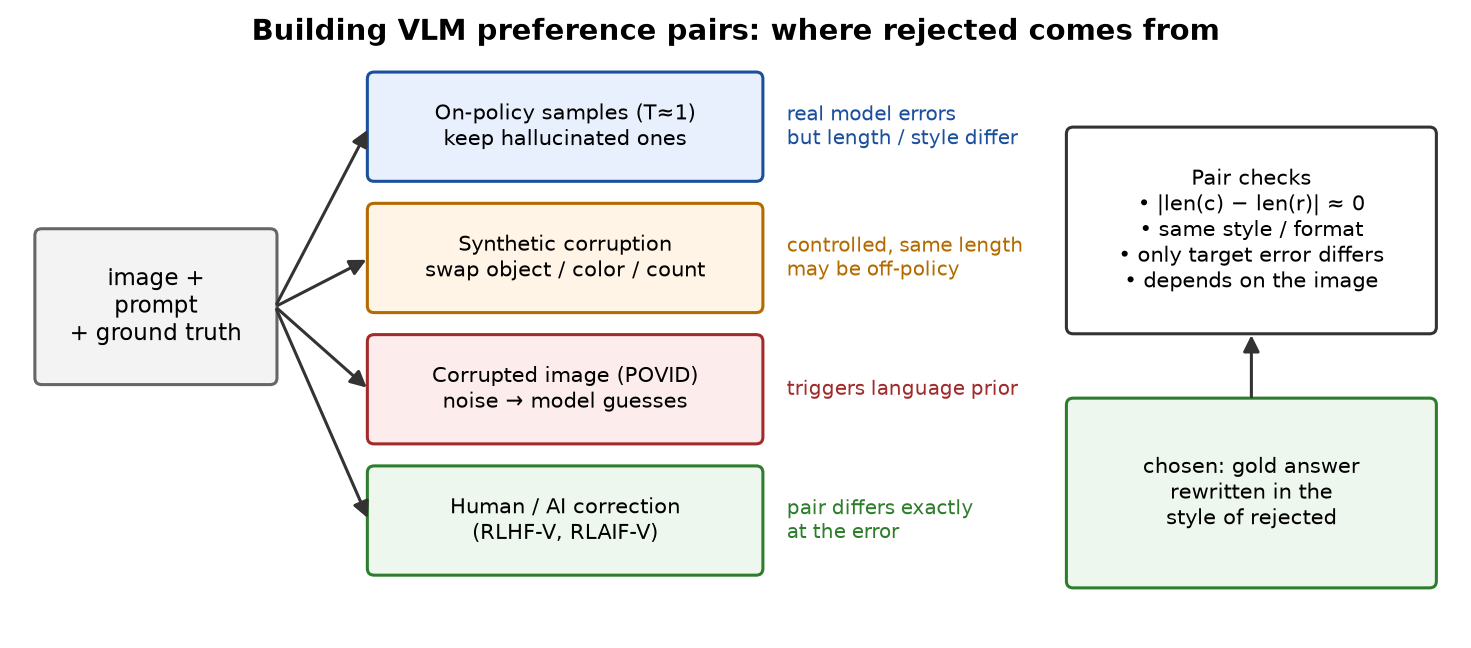

### 5.1. Формат записи

Одна запись: изображение (или несколько), запрос, chosen, rejected. В TRL для VLM колонки `prompt`, `chosen`, `rejected` записываются в диалоговом формате, а изображения кладутся в колонку `images` (или `image`); пример — датасет `HuggingFaceH4/rlaif-v_formatted`, а в документации рекомендуется `max_length=None`, чтобы не обрезать визуальные токены ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer)). В LLaMA-Factory формат sharegpt с `"ranking": true`, полями `chosen` и `rejected` и колонкой `images`; для KTO — поле `kto_tag` с булевой меткой ([LLaMA-Factory data README](https://github.com/hiyouga/LLaMA-Factory/blob/main/data/README.md)). В разделе 20 мы экспортируем наши пары в оба формата.

Обязательные метаданные каждой пары, без которых потом невозможно разобраться в результатах:

- источник chosen и rejected (человек, модель X, синтетическая подмена, правка);
- кто и как вынес суждение (человек, судья-модель, автоматическая проверка), с уверенностью или признаком ничьей;
- длина обоих ответов в токенах;
- тип ошибки rejected (галлюцинация объекта, атрибута, отношения, счёта; нарушение формата; отказ).

### 5.2. Откуда берутся chosen

1. Эталоны из разметки: подписи, ответы VQA, плотные описания. Надёжны, но написаны «не голосом» модели.
2. Ответы самой модели, признанные правильными (on-policy chosen). Наиболее «родные» для политики, но их нужно проверить.
3. Исправленные ответы. В RLHF-V люди не выбирают из двух ответов, а исправляют галлюцинирующие сегменты в ответе модели; по таким сегментным правкам обучается плотная DPO ([Yu et al., 2023](https://arxiv.org/abs/2312.00849)). Пара «ответ модели — тот же ответ с исправленными фрагментами» различается ровно в месте ошибки.
4. Ответы более сильной модели (дистилляция предпочтений). В Silkie ответы 12 разных VLM оценивала GPT-4V по полезности, визуальной точности и этике, и предпочтения дистиллировались в Qwen-VL-Chat через DPO ([Li et al., 2023](https://arxiv.org/abs/2312.10665)).

### 5.3. Откуда берутся rejected: сбор «плохих» ответов

Это главный вопрос для VLM, потому что именно rejected определяют, от чего модель отучится.

1. On-policy сэмплы с ошибками. Генерируем несколько ответов модели при температуре около 1, автоматически или вручную находим ошибочные. Плюс: это реальные ошибки модели, и DPO будет работать там, где модель действительно ошибается. Минус: ошибочный ответ может отличаться от правильного не только ошибкой, но и длиной, стилем, форматом.
2. Синтетическая порча правильного ответа. Подменяем в эталоне объект, атрибут или число на правдоподобный неверный вариант. POVID просит GPT-4V внедрить в правильный ответ правдоподобные галлюцинации ([Zhou et al., 2024](https://arxiv.org/abs/2402.11411)). HA-DPO строит пары так, чтобы позитив и негатив были согласованы по стилю ([Zhao et al., 2023](https://arxiv.org/abs/2311.16839)). Плюс: контроль над типом ошибки и над длиной. Минус: синтетические ошибки могут не совпадать с теми, которые модель делает сама, и тогда DPO «тратит силы» на ответы с низкой вероятностью.
3. Ответы на испорченное изображение. Вторая стадия POVID: изображение искажают (например, шумом), и модель, плохо видя, начинает опираться на языковые априорные знания и галлюцинировать; эти ответы и становятся rejected ([Zhou et al., 2024](https://arxiv.org/abs/2402.11411)).
4. Ответы более слабых моделей или пул моделей с оценкой судьёй, как в VLFeedback ([Li et al., 2023](https://arxiv.org/abs/2312.10665)).
5. Самооценка открытой моделью: RLAIF-V строит обратную связь целиком на открытых MLLM, без ручной разметки и проприетарных моделей ([Yu et al., 2024](https://arxiv.org/abs/2405.17220)).

Хороший rejected — правдоподобный, то есть такой, который модель могла бы сгенерировать, и отличающийся от chosen только тем свойством, от которого мы хотим отучить. Плохой rejected — очевидно абсурдный (модель и так не стала бы его генерировать, сигнал почти нулевой) или отличающийся сразу многим.

### 5.4. Контроль длины и стиля

[Singhal et al., 2023](https://arxiv.org/abs/2310.03716) показали на трёх постановках, что рост награды в RLHF в значительной степени объясняется ростом длины ответов, и что даже награда, основанная только на длине, воспроизводит большую часть улучшений RLHF над SFT; основным источником этого смещения авторы называют reward models, легко подхватывающие корреляцию длины с предпочтением в данных. Для DPO длину эксплуатирует сама политика ([Park et al., 2024](https://arxiv.org/abs/2403.19159)).

Механика простая. Если в датасете chosen систематически длиннее rejected, самый дешёвый способ различать пары — длина. Модель научится удлинять ответы, и это будет выглядеть как «улучшение»: неявная награда на обучающих парах растёт. Если chosen систематически короче, модель научится укорачивать ответы и, возможно, «молчать» (для галлюцинаций это коварно: короткий ответ галлюцинирует реже просто потому, что упоминает меньше объектов).

Что делать.

1. Измерять: для набора пар посчитать среднюю разность длин chosen и rejected, долю пар, где chosen длиннее, и корреляцию длины с меткой. Идеал — разность около нуля и доля около 50%.
2. Строить пары в одном стиле: chosen переписывается в стиле rejected (те же вводные фразы, тот же порядок, та же длина), меняется только содержательная ошибка. Так делает HA-DPO ([Zhao et al., 2023](https://arxiv.org/abs/2311.16839)), так сделаем и мы.
3. Отбирать: из нескольких ошибочных сэмплов брать тот, чья длина ближе к chosen; пары с большой разницей длин отбрасывать или балансировать.
4. Регуляризовать: штраф за разность длин в DPO ([Park et al., 2024](https://arxiv.org/abs/2403.19159)), нормировка на длину (SimPO, `loss_type="ipo"` в TRL с усреднением).
5. Оценивать с поправкой на длину (раздел 7.1).

Помимо длины, такие же «короткие пути» дают стиль (Markdown-списки, вежливые вступления, извинения), формат и даже первые слова ответа. Правило: любое систематическое различие chosen и rejected, кроме целевого, модель может выучить вместо целевого.

### 5.5. Условность по изображению

[Wang et al., 2024](https://arxiv.org/abs/2406.11839) обнаружили в мультимодальной DPO проблему безусловного предпочтения: модель может выучить предпочтение chosen над rejected, вообще не глядя на изображение, если пары различимы по тексту. Тогда «улучшение» на обучающих парах не связано с визуальной обоснованностью. Предложенный mDPO добавляет к обычной цели сравнение «тот же chosen с исходным изображением ≻ тот же chosen с испорченным изображением».

Простая проверка, которую стоит делать всегда: посчитать accuracy неявной награды на парах дважды — с правильным изображением и с изображением от другого примера. Если accuracy почти не падает, модель различает пары по тексту. Мы сделаем эту проверку в разделе 19.

## 6. Борьба с галлюцинациями через предпочтения

### 6.1. Типы галлюцинаций в VLM

- Объектные: упомянут объект, которого нет на изображении («на столе лежит нож»).
- Атрибутные: объект есть, но неверен цвет, размер, материал, состояние.
- Реляционные: неверное пространственное или смысловое отношение («слева от», «держит»).
- Счётные: неверное число объектов.
- Пропуски: объект есть, но не упомянут. Формально это не галлюцинация, но это обратная сторона: модель, которая ничего не называет, не галлюцинирует.

[Rohrbach et al., 2018](https://arxiv.org/abs/1809.02156) на COCO показали, что модели с лучшими стандартными метриками подписей не всегда галлюцинируют меньше и что модели, которые галлюцинируют больше, чаще совершают ошибки, вызванные языковыми априорными знаниями. Языковой априор — ключевой механизм: модель дописывает «вилку» рядом с «тарелкой», потому что так часто бывает в текстах, а не потому что видит её.

### 6.2. Почему preference помогает

SFT на правильных описаниях учит, что «правильно», но не штрафует модель за правдоподобную выдумку. Пара «правильное описание ≻ то же описание с выдуманным объектом» делает ровно это: градиент DPO сосредоточен на токенах, где ответы расходятся (раздел 3.3). Это точечный штраф за галлюцинацию, причём в контексте, где модель её совершает.

Результаты на практике значительные. RLHF-V с 1,4 тыс. размеченных примеров снижает частоту галлюцинаций базовой модели на 34,8% ([Yu et al., 2023](https://arxiv.org/abs/2312.00849)). RLAIF-V 7B снижает объектные галлюцинации на 80,7% и общие на 33,7% ([Yu et al., 2024](https://arxiv.org/abs/2405.17220)). HA-DPO подняла accuracy MiniGPT-4 на POPE с 51,13% до 86,13% ([Zhao et al., 2023](https://arxiv.org/abs/2311.16839)). LLaVA-RLHF использовала классический RLHF с Factually Augmented reward model, которой дополнительно передаются подписи и правильные варианты ответов; это ослабляет reward hacking ([Sun et al., 2023](https://arxiv.org/abs/2309.14525)). Эти числа получены на разных моделях и бенчмарках, их нельзя сравнивать между собой напрямую.

### 6.3. Рецепт hallucination-DPO

1. Взять SFT-модель (она же reference).
2. Сгенерировать для каждого изображения несколько ответов при T ≈ 1.
3. Разметить упоминания: по разметке объектов (как CHAIR), детектором, судьёй-VLM или вручную.
4. Для изображений, где есть и верный, и ошибочный ответ, построить пару в одном стиле; где ошибочного нет — синтетическая порча; где нет верного — исправление.
5. Проверить статистику пар: длина, стиль, формат, доля on-policy.
6. Обучить DPO с умеренным $\beta$ и малым learning rate, следить за правдоподобием chosen.
7. Оценить: галлюцинации, полноту (recall), формат, длину, win rate, POPE на реальных изображениях, KL до reference.

Пункт 7 критичен. Снижение частоты галлюцинаций ничего не значит, если одновременно упала полнота: модель могла просто начать упоминать меньше объектов.

## 7. Метрики

Alignment меняет поведение модели в нескольких направлениях сразу, поэтому одной метрики недостаточно. Минимальный набор для VLM: win rate против исходной модели, частота галлюцинаций вместе с полнотой, соблюдение формата, длина, KL до reference и качество на исходной (или соседней) задаче.

### 7.1. Win rate

Берём набор запросов, для каждого получаем ответ модели A и модели B, и судья (человек, сильная модель, автоматическое правило) решает, какой лучше, или объявляет ничью. Тогда

$$ \mathrm{WR}(A, B) = \frac{\#\{A \succ B\} + \tfrac12 \#\{\text{ничьих}\}}{N}. $$

На что обратить внимание.

1. Ничьи. Их нужно либо считать как половину победы (как в формуле), либо исключать и сообщать их долю отдельно. Если после alignment модель меняет только 10% ответов, win rate без ничьих может быть 90%, а с ничьими 54%; это разные утверждения.
2. Доверительный интервал. Win rate — доля, и на 100 запросах стандартная ошибка около 5 п. п. Интервал считают бутстрепом по запросам. Разница в 3 п. п. на 100 примерах — шум.
3. Позиционное смещение судьи. Модели-судьи склонны предпочитать ответ на определённой позиции и более длинные ответы; [Zheng et al., 2023](https://arxiv.org/abs/2306.05685) перечисляют позиционное смещение, смещение к многословию и предпочтение собственных ответов. Минимальная защита — спрашивать судью дважды с переставленными ответами и засчитывать победу, только если оба порядка согласны.
4. Длина. Если судья любит длинные ответы, модель, которая научилась удлинять ответы, выиграет без улучшения качества. Length-controlled AlpacaEval оценивает предпочтения судьи с помощью обобщённой линейной модели, где разность длин — один из признаков, и затем предсказывает предпочтение при нулевой разности длин; это повысило корреляцию Спирмена с Chatbot Arena с 0,94 до 0,98 ([Dubois et al., 2024](https://arxiv.org/abs/2404.04475)).
5. Согласие судьи с людьми. Сильные судьи достигают более 80% согласия с людьми, то есть уровня согласия людей между собой ([Zheng et al., 2023](https://arxiv.org/abs/2306.05685)). Это верхняя граница, а не гарантия для конкретной задачи: согласие нужно проверять на своей выборке.

### 7.2. Hallucination rate: CHAIR

CHAIR ([Rohrbach et al., 2018](https://arxiv.org/abs/1809.02156)) считается по описаниям изображений, для которых известен список объектов (на COCO — по разметке сегментации и подписям). Из ответа извлекаются упоминания объектов (со словарём синонимов), и считаются две величины:

$$ \mathrm{CHAIR}_i = \frac{\#\{\text{упомянутых объектов, которых нет на изображении}\}}{\#\{\text{всех упомянутых объектов}\}}, \qquad \mathrm{CHAIR}_s = \frac{\#\{\text{ответов хотя бы с одной галлюцинацией}\}}{\#\{\text{всех ответов}\}}. $$

$\mathrm{CHAIR}_i$ — доля ложных упоминаний, $\mathrm{CHAIR}_s$ — доля «испорченных» ответов. Обе метрики можно обмануть молчанием, поэтому их всегда публикуют вместе с полнотой (recall: доля объектов изображения, которые упомянуты) и длиной ответа. В практикуме у нас синтетические сцены с полной разметкой, и CHAIR считается точно, с учётом цвета и формы.

### 7.3. POPE и AMBER

POPE ([Li et al., 2023](https://arxiv.org/abs/2305.10355)) превращает проверку галлюцинаций в серию вопросов «Is there a X in the image?» с ответами yes/no. Половина вопросов о присутствующих объектах, половина об отсутствующих. Отсутствующие выбираются тремя способами: случайно, среди самых частых объектов датасета (popular) и среди объектов, которые часто встречаются вместе с присутствующими (adversarial). Adversarial-набор проверяет именно языковой априор. Кроме accuracy и F1 смотрят долю ответов yes: модель, которая всегда соглашается, получит 50% accuracy и 100% yes. Мы используем adversarial-подмножество POPE из `lmms-lab/POPE` как проверку на реальных фотографиях COCO, которых не было в обучении.

AMBER ([Wang et al., 2023](https://arxiv.org/abs/2311.07397)) — бенчмарк без LLM-судьи, который оценивает и генеративные, и дискриминативные задачи и различает галлюцинации существования, атрибутов и отношений. MMHal-Bench ([Sun et al., 2023](https://arxiv.org/abs/2309.14525)) — набор открытых вопросов с оценкой судьёй, специально наказывающий галлюцинации.

### 7.4. Соблюдение формата

Многие применения VLM требуют строго определённого формата: JSON, одно предложение, фиксированный шаблон, список из N пунктов. Соблюдение формата — доля ответов, которые проходят автоматическую проверку (регулярное выражение, JSON-схему, парсер). Идею верифицируемых инструкций развивает IFEval: 25 типов проверяемых инструкций (например, «больше 400 слов», «упомяни ключевое слово не менее 3 раз») и около 500 запросов ([Zhou et al., 2023](https://arxiv.org/abs/2311.07911)). Формат — первое, что ломается при чрезмерной preference-оптимизации (мы это увидим), потому что DPO не тянет вверх общие для chosen и rejected токены, в том числе токены шаблона.

### 7.5. KL до reference и неявная награда

$$ \mathrm{KL}(\pi_\theta \,\|\, \pi_{\mathrm{ref}}) \approx \frac{1}{N} \sum_{i=1}^{N} \Big[ \log \pi_\theta(y_i \mid x_i) - \log \pi_{\mathrm{ref}}(y_i \mid x_i) \Big], \quad y_i \sim \pi_\theta(\cdot \mid x_i). $$

Это «пробег» оптимизации. Сравнивать методы честно при равном KL: метод, который ушёл дальше, обычно получает больше эффекта и больше побочных эффектов. В [Gao et al., 2022](https://arxiv.org/abs/2210.10760) и [Rafailov et al., 2024](https://arxiv.org/abs/2406.02900) именно KL служит осью, по которой видна переоптимизация.

Accuracy неявной награды на отложенных парах показывает, выучила ли модель различение. С ней полезно сделать проверку с перемешанными изображениями (раздел 5.5).

### 7.6. Исходная задача и общие способности

Модель после alignment должна сохранить то, что умела: качество на основной задаче (в нашем случае — полноту и точность счёта), на соседних задачах и на общих бенчмарках VLM. В InstructGPT отмечены минимальные регрессии на публичных NLP-датасетах ([Ouyang et al., 2022](https://arxiv.org/abs/2203.02155)), но их пришлось специально ограничивать. Такая деградация называется «налогом на alignment» (alignment tax).

## 8. Побочные эффекты

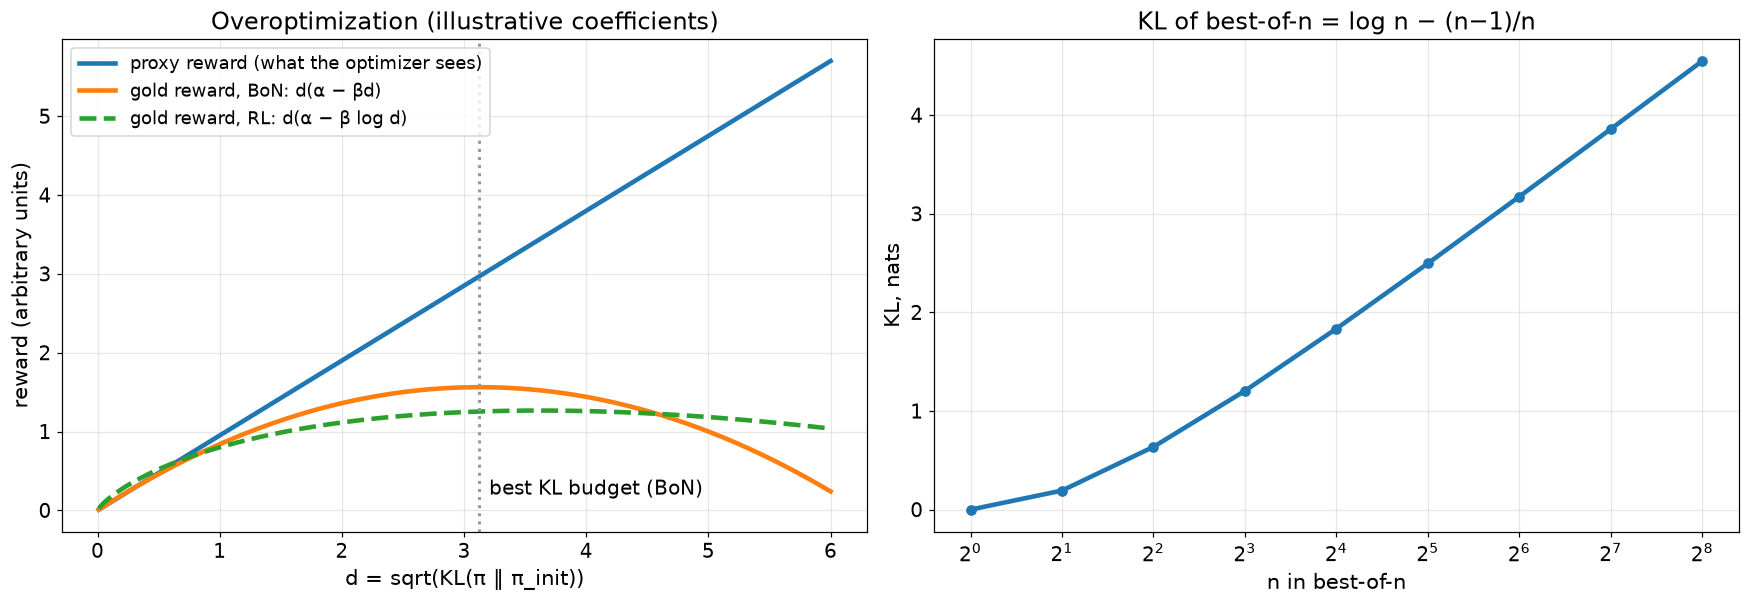

### 8.1. Reward hacking

Reward hacking — ситуация, когда оптимизация неидеальной прокси-награды приводит к ухудшению по истинной награде ([Skalse et al., 2022](https://arxiv.org/abs/2209.13085)). Авторы этой работы показывают, что «невзламываемая» прокси — очень сильное условие: для множества всех стохастических политик две функции награды могут быть невзламываемыми друг относительно друга, только если одна из них константа ([Skalse et al., 2022](https://arxiv.org/abs/2209.13085)). Практический вывод: любая reward model, которую мы обучили, будет взломана при достаточно сильной оптимизации.

[Gao et al., 2022](https://arxiv.org/abs/2210.10760) измерили это в контролируемой постановке: «золотая» reward model играет роль людей, а прокси-RM обучается на её метках. Обозначим $d = \sqrt{\mathrm{KL}(\pi \,\|\, \pi_{\mathrm{init}})}$. Эмпирически золотая награда как функция расстояния ведёт себя так:

$$ R_{\mathrm{BoN}}(d) = d\,(\alpha_{\mathrm{BoN}} - \beta_{\mathrm{BoN}}\, d), \qquad R_{\mathrm{RL}}(d) = d\,(\alpha_{\mathrm{RL}} - \beta_{\mathrm{RL}} \log d). $$

Сначала золотая награда растёт, затем достигает максимума и падает, хотя прокси-награда продолжает расти. Коэффициенты плавно зависят от размера RM: большая RM взламывается позже. Здесь $\beta$ — коэффициент закона, а не $\beta$ DPO.

Для DPO отдельной RM нет, но эффект тот же: при росте KL-бюджета direct alignment методы деградируют похоже на RLHF, иногда ещё до конца первой эпохи ([Rafailov et al., 2024](https://arxiv.org/abs/2406.02900)). В роли прокси выступает сам датасет пар: модель хорошо различает обучающие пары, но обобщённое качество может падать.

Типичные «взломы» в VLM:

- многословие (раздел 8.2);
- избегание: модель перестаёт упоминать объекты, отвечает уклончиво («на изображении несколько фигур») — галлюцинаций меньше, но и пользы меньше;
- перестраховка в POPE-подобных задачах: модель начинает отвечать «no» почти на всё;
- стилевые маркеры, которые RM или судья связывает с качеством (дисклеймеры, «уверенный» тон);
- уход от формата, если формат не входит в награду.

Защита: KL-штраф и ранняя остановка, ансамбль или более крупная RM, факты в RM (как в LLaVA-RLHF — [Sun et al., 2023](https://arxiv.org/abs/2309.14525)), комбинирование RM с проверяемыми правилами (формат, длина), регулярная проверка выборок глазами и метрики, которые RM не видела.

### 8.2. Многословие

Длина — самый частый взлом. Причины: люди и судьи предпочитают более подробные ответы ([Zheng et al., 2023](https://arxiv.org/abs/2306.05685)); reward model подхватывает корреляцию длины с меткой ([Singhal et al., 2023](https://arxiv.org/abs/2310.03716)); DPO с суммой лог-вероятностей и OOD-«бутстрепом» сама увеличивает длину ([Park et al., 2024](https://arxiv.org/abs/2403.19159)). Для VLM многословие особенно вредно: каждое лишнее предложение — новый шанс галлюцинировать. Контроль: сбалансированные пары, нормировка на длину, штраф за длину, length-controlled win rate.

### 8.3. Деградация исходной задачи

Механизмы:

- падение правдоподобия chosen и дрейф общих токенов (раздел 3.3): модель «забывает» шаблон ответа, хотя прямо её этому не учили;
- уход из распределения: при большом learning rate или многих эпохах политика уходит далеко от reference;
- узость данных: если все пары про объекты, другие навыки (счёт, OCR, рассуждения) не поддерживаются никаким сигналом.

Диагностика: метрики исходной задачи и формата до и после, KL, POPE и другие внешние бенчмарки. Лечение: NLL-добавка на chosen, ORPO, меньший learning rate, меньше эпох, смешивание с SFT-данными.

### 8.4. Снижение разнообразия

[Kirk et al., 2023](https://arxiv.org/abs/2310.06452) показали, что RLHF лучше SFT обобщается на новые входы, особенно при большом сдвиге распределения, но значительно снижает разнообразие ответов по ряду мер. Для VLM это означает меньшую вариативность описаний; для генерации синтетических данных (лекция 7) это может быть существенно.

### 8.5. Игнорирование изображения

Проблема безусловного предпочтения ([Wang et al., 2024](https://arxiv.org/abs/2406.11839)): модель выучивает текстовые признаки пар, а не связь текста с изображением. Признак — accuracy неявной награды почти не меняется при подмене изображения.

## 9. Инструменты

TRL (Hugging Face) содержит `DPOTrainer` и `KTOTrainer`; ORPO вынесен в `trl.experimental.orpo` ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer), [TRL KTOTrainer](https://huggingface.co/docs/trl/main/en/kto_trainer), [TRL ORPOTrainer](https://huggingface.co/docs/trl/main/en/orpo_trainer)). Основные параметры DPOConfig: `beta` (по умолчанию 0,1), `loss_type`, `learning_rate` (по умолчанию 1e-6), `precompute_ref_log_probs`, `max_length` (для VLM рекомендуется `None`). VLM поддерживаются: в документации есть пример на Qwen2.5-VL-3B и датасете `HuggingFaceH4/rlaif-v_formatted` ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer)).

LLaMA-Factory поддерживает стадии `pt`, `sft`, `rm`, `ppo`, `dpo`, `kto`, а для `dpo` — `pref_loss` из `sigmoid`, `orpo`, `simpo` ([LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory)). В репозитории есть готовый пример LoRA-DPO для Qwen3-VL-4B-Instruct: `lora_rank: 8`, `pref_beta: 0.1`, датасет `rlhf_v`, шаблон `qwen3_vl_nothink`, `learning_rate: 5.0e-6`, 3 эпохи, `max_samples: 1000`, `cutoff_len: 2048` ([qwen3vl_lora_dpo.yaml](https://github.com/hiyouga/LLaMA-Factory/blob/main/examples/train_lora/qwen3vl_lora_dpo.yaml)). Датасет `rlhf_v` в `dataset_info.json` указывает на `llamafactory/RLHF-V` на Hugging Face ([LLaMA-Factory data README](https://github.com/hiyouga/LLaMA-Factory/blob/main/data/README.md)).

Обратите внимание на learning rate: в TRL по умолчанию 1e-6, в примере LLaMA-Factory 5e-6. Это на 1–2 порядка меньше, чем в SFT. В нашем практикуме learning rate выше, потому что модель маленькая, данных мало, а обучаются только LoRA-адаптеры; переносить наши значения на большие модели нельзя.

Готовые VLM-датасеты предпочтений: RLHF-V (сегментные исправления людей, [Yu et al., 2023](https://arxiv.org/abs/2312.00849)), RLAIF-V ([Yu et al., 2024](https://arxiv.org/abs/2405.17220)), VLFeedback ([Li et al., 2023](https://arxiv.org/abs/2312.10665)), данные LLaVA-RLHF ([Sun et al., 2023](https://arxiv.org/abs/2309.14525)).

## 10. Рецепт и типичные ошибки

### 10.1. Рецепт

1. Начните с хорошей SFT-модели. Preference optimization исправляет предпочтения, а не учит задаче.
2. Определите, что именно вы хотите изменить (галлюцинации, формат, отказы), и как вы это измерите автоматически. Без измерения дальше не идите.
3. Соберите пары, в которых chosen и rejected различаются только целевым свойством. Предпочитайте on-policy rejected; синтетику используйте для покрытия.
4. Посчитайте статистику пар: длина, стиль, формат, доля on-policy, проверка с перемешанными изображениями после обучения.
5. Начните с DPO, $\beta = 0{,}1$, малым learning rate, одной эпохой; reference = SFT-модель, лог-вероятности reference посчитайте заранее.
6. Следите за `rewards/chosen`: если она уходит сильно ниже нуля, добавьте NLL на chosen или уменьшите learning rate.
7. Оценивайте сразу всё: целевую метрику, полноту, формат, длину, KL, win rate с CI и с контролем длины, внешний бенчмарк.
8. Если есть ресурсы, итерируйте: генерация новой моделью, новые пары, ещё одна итерация.

### 10.2. Типичные ошибки

| Ошибка | Симптом | Исправление |
|---|---|---|
| chosen систематически длиннее rejected | растёт длина, растёт win rate у судьи, растут галлюцинации | балансировать длину, LC win rate, SimPO/штраф |
| chosen систематически короче | ответы укорачиваются, падает полнота | то же, с другой стороны |
| rejected абсурдны | reward acc = 1 с первого шага, эффекта нет | правдоподобные негативы, on-policy |
| reference ≠ стартовая политика | loss на старте ≠ log 2 | reference = SFT-модель |
| слишком большой learning rate или много эпох | chosen logp падает на единицы и десятки нат, ломается формат | меньше шагов, NLL-добавка, ранняя остановка |
| обрезка последовательности | теряются визуальные токены или ответ | `max_length=None`, проверка длины |
| оценка только на обучающих парах | высокая reward acc, нет улучшения в генерации | генерация и внешние метрики |
| метрика галлюцинаций без полноты | «улучшение» за счёт молчания | всегда recall и длина рядом |
| нет проверки на зависимость от изображения | модель различает пары по тексту | accuracy с перемешанными изображениями, mDPO |

# Часть II. Практикум

## 11. Подготовка: среда, модель, данные

План практикума:

| Раздел | Что делаем | Что увидим |
|---|---|---|
| 11 | среда, синтетические сцены, эталонные описания | данные с полной разметкой |
| 12 | метрики: CHAIR, полнота, счёт, формат, win rate | как считать галлюцинации точно |
| 13 | модель SmolVLM, кэш визуальных признаков, генерация, POPE | исходное поведение базовой модели |
| 14 | SFT с LoRA | откуда берётся стартовая политика и где она ошибается |
| 15 | сэмплы SFT-модели, три набора пар | как выглядит смещение по длине в данных |
| 16 | DPO, IPO, KTO, ORPO, SimPO с нуля, игрушечная задача | куда каждая функция потерь сдвигает вероятности |
| 17–18 | reward model и best-of-n | reward hacking на смещённой RM |
| 19 | обучение по предпочтениям и оценка | win rate, галлюцинации, формат, длина, KL, POPE |
| 20 | экспорт данных, TRL, LLaMA-Factory, конфигурация прогона | перенос на Qwen3-VL |

Режимы запуска. Ячейка ниже определяет устройство. На GPU (Colab T4) используется SmolVLM-500M-Instruct в fp32 и полные размеры выборок. Без GPU включается `FAST_DEV_RUN`: SmolVLM-256M-Instruct ([карточка модели](https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct)) и уменьшенные выборки; весь блокнот на двух ядрах CPU выполняется примерно за час. Сохранённые результаты получены именно в этом режиме. Модели семейства Qwen3-VL (в том числе 2B, которую курс использует для DPO по умолчанию) в практикуме не обучаются: даже 2B не помещается в бюджет CPU-прогона и требует заметно больше времени на T4. Для них в разделе 20 подготовлены экспорт данных и конфигурации TRL и LLaMA-Factory.

Почему маленькая модель и синтетика. Цель практикума — увидеть механизмы (что делает DPO с вероятностями, как длина пролезает в данные, как взламывается RM) и измерить их точно. Для этого нужны сотни прогонов генерации и полное знание о содержимом изображения. Синтетические сцены дают точный CHAIR без детектора и судьи, а POPE на реальных фото COCO проверяет, что изменения не ограничиваются синтетикой.

In [1]:
import importlib, subprocess, sys

def ensure(pkg, spec=None):
    """Импортирует пакет, а если его нет — ставит через pip."""
    try:
        return importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec or pkg], check=False)
        return importlib.import_module(pkg)

import torch
HAS_GPU = torch.cuda.is_available()
import transformers
from packaging.version import Version
if Version(transformers.__version__) < Version("4.46.0"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.46", "accelerate"], check=False)
    print("transformers обновлён: перезапустите среду (Runtime → Restart session) и запустите блокнот заново.")
for pkg, spec in [("accelerate", None), ("peft", "peft>=0.13"), ("pandas", None), ("pyarrow", None), ("yaml", "pyyaml")]:
    ensure(pkg, spec)

import importlib.metadata as md
PKGS = ["torch", "transformers", "peft", "accelerate", "numpy"]
VERSIONS = {p: md.version(p) for p in PKGS}
print(VERSIONS, "| GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "нет")

{'torch': '2.14.1+cpu', 'transformers': '5.19.0', 'peft': '0.21.2', 'accelerate': '1.15.0', 'numpy': '2.5.2'} | GPU: нет


In [2]:
import os, gc, io, re, json, time, math, random, hashlib, platform, copy, contextlib
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoProcessor, AutoModelForImageTextToText

SEED = 0
def seed_everything(seed):
    """Фиксирует все генераторы случайных чисел, от которых зависит обучение."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if HAS_GPU:
        torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

FAST_DEV_RUN = not HAS_GPU
def n_(gpu, cpu):
    """Размер выборки: полный на GPU, уменьшенный в режиме FAST_DEV_RUN."""
    return cpu if FAST_DEV_RUN else gpu

# Обе модели — одна архитектура Idefics3 (SigLIP + SmolLM2), поэтому весь код одинаков
MODEL_ID = "HuggingFaceTB/SmolVLM-500M-Instruct" if HAS_GPU else "HuggingFaceTB/SmolVLM-256M-Instruct"
DEVICE = "cuda" if HAS_GPU else "cpu"
DTYPE = torch.float32          # модели маленькие: fp32 помещается и на T4, и на CPU; так обучение стабильнее

N_SFT    = n_(1000, 160)   # SFT-диалогов
N_PREF   = n_(800, 128)    # изображений для preference-данных
N_EVAL   = n_(200, 40)     # изображений в оценочном наборе
N_POPE   = n_(300, 60)     # вопросов POPE (реальные фото COCO)
K_SAMPLES = 4              # сэмплов SFT-модели на изображение при сборе on-policy негативов
BON_N    = 8               # максимальное n в best-of-n
N_BON    = n_(100, 24)     # изображений для best-of-n
IMG_SIDE = 256
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
print("модель:", MODEL_ID, "| устройство:", DEVICE, "| FAST_DEV_RUN:", FAST_DEV_RUN)

модель: HuggingFaceTB/SmolVLM-256M-Instruct | устройство: cpu | FAST_DEV_RUN: True


### 11.2. Данные: сцены из цветных фигур

Каждое изображение — 224×224, на нём от 1 до 4 фигур (квадрат, круг, треугольник) четырёх цветов (red, green, blue, yellow). Разметка — список объектов «цвет форма». Запрос один для всех: описать изображение. Эталонный ответ строится по шаблону: «There are N shapes: a ..., a ... and a ...» (для одного объекта — «There is 1 shape: ...»). Это жёсткий формат, который мы будем проверять регулярным выражением.

Чтобы в SFT-модели появилась склонность к многословию, как у реальных моделей после instruction tuning, к 25% эталонов SFT добавляется лишнее предложение из небольшого набора (`FILLERS`), например «The background is plain white.». Содержательно оно не ошибочно, но нарушает формат и удлиняет ответ.

Наборы не пересекаются: SFT, preference (из них строятся пары), оценочный и отдельный набор для best-of-n. Совпадения проверяются по хэшу изображения.

SFT: 160 | preference: 128 | eval: 40 | best-of-n: 24
доля SFT-ответов с лишним предложением: 0.244
  There are 4 shapes: a red triangle, a yellow square, a red square and a yellow circle.
  There are 4 shapes: a red square, a yellow circle, a blue circle and a green square. The composition is simple and the objects do not overlap.
  There are 2 shapes: a yellow square and a yellow triangle. The composition is simple and the objects do not overlap.


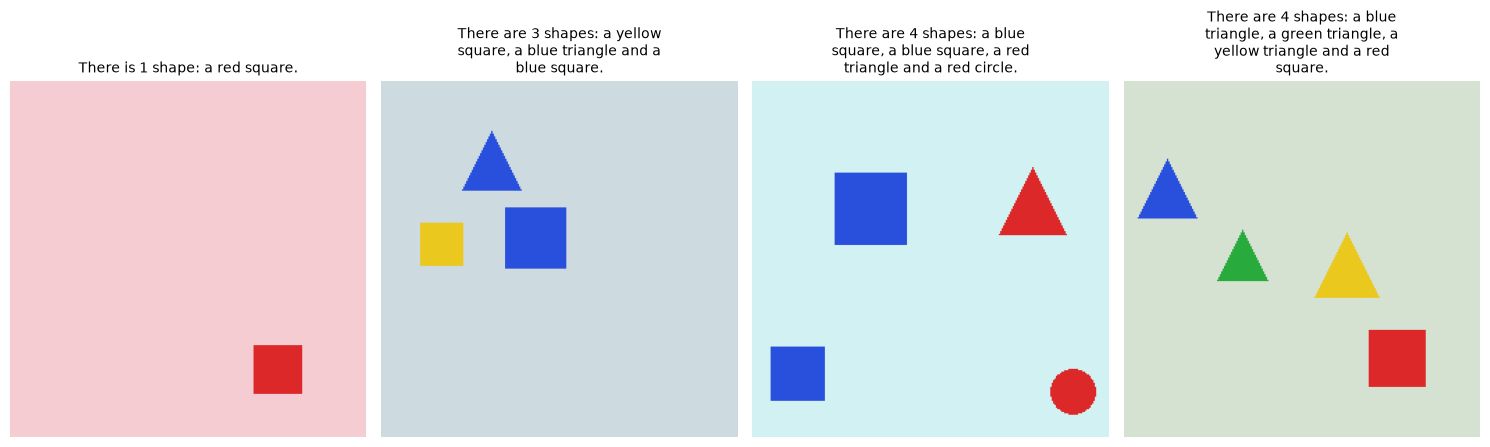

In [3]:
SHAPES = ["circle", "square", "triangle"]
COLORS = {"red": (220, 40, 40), "green": (40, 170, 60), "blue": (40, 80, 220), "yellow": (235, 200, 30)}
QUESTION = "Describe the shapes in the image in one sentence."
FILLERS = ["The shapes are drawn on a light background and are easy to see.",
           "Each shape has a clear outline and a uniform color.",
           "The composition is simple and the objects do not overlap."]

def draw_shape(d, shape, cx, cy, s, rgb):
    if shape == "circle":
        d.ellipse([cx - s / 2, cy - s / 2, cx + s / 2, cy + s / 2], fill=rgb)
    elif shape == "square":
        d.rectangle([cx - s / 2, cy - s / 2, cx + s / 2, cy + s / 2], fill=rgb)
    else:
        d.polygon([(cx, cy - s / 2), (cx - s / 2, cy + s / 2), (cx + s / 2, cy + s / 2)], fill=rgb)

def make_scene(rng, n_range=(1, 4), size=(30, 56)):
    """Изображение и список объектов слева направо."""
    W = IMG_SIDE
    img = Image.new("RGB", (W, W), tuple(int(v) for v in rng.integers(200, 256, 3)))
    d = ImageDraw.Draw(img)
    n = int(rng.integers(n_range[0], n_range[1] + 1))
    objs, boxes = [], []
    while len(objs) < n:
        s = int(rng.integers(size[0], size[1] + 1))
        cx, cy = rng.integers(s // 2 + 4, W - s // 2 - 4, 2)
        if any(abs(cx - bx) < (s + bs) / 2 + 6 and abs(cy - by) < (s + bs) / 2 + 6 for bx, by, bs in boxes):
            continue
        if any(abs(cx - bx) < 8 for bx, _, _ in boxes):
            continue
        shape = SHAPES[rng.integers(3)]; color = list(COLORS)[rng.integers(len(COLORS))]
        draw_shape(d, shape, cx, cy, s, COLORS[color])
        boxes.append((cx, cy, s)); objs.append((int(cx), f"{color} {shape}"))
    objs.sort()
    return img, [o for _, o in objs]

def describe(objects, filler=None):
    """Эталонное описание в каноническом формате; filler — лишнее «стилевое» предложение."""
    n = len(objects)
    items = [f"a {o}" for o in objects]
    lst = items[0] if n == 1 else ", ".join(items[:-1]) + " and " + items[-1]
    s = f"There {'is' if n == 1 else 'are'} {n} shape{'' if n == 1 else 's'}: {lst}."
    return s if filler is None else s + " " + filler

def make_set(n, seed, **kw):
    rng = np.random.default_rng(seed)
    out = []
    for i in range(n):
        img, objs = make_scene(rng, **kw)
        out.append({"id": f"s{seed}_{i}", "image": img, "objects": objs})
    return out

sft_set  = make_set(N_SFT, 1)
pref_set = make_set(N_PREF, 2)
eval_set = make_set(N_EVAL, 3)
bon_set  = make_set(N_BON, 4)
# SFT-ответы: 75% в каноническом формате, 25% с лишним предложением — у SFT-политики будет разброс стиля
rng_style = np.random.default_rng(10)
for ex in sft_set:
    ex["answer"] = describe(ex["objects"], FILLERS[rng_style.integers(3)] if rng_style.random() < 0.25 else None)
h = lambda ex: hashlib.sha256(ex["image"].tobytes()).hexdigest()
seen = {h(e) for e in sft_set + pref_set}
assert not any(h(e) in seen for e in eval_set + bon_set), "утечка: оценочная сцена совпала с обучающей"
print("SFT:", len(sft_set), "| preference:", len(pref_set), "| eval:", len(eval_set), "| best-of-n:", len(bon_set))
print("доля SFT-ответов с лишним предложением:", np.mean([any(f in e["answer"] for f in FILLERS) for e in sft_set]).round(3))
for e in sft_set[:3]:
    print(" ", e["answer"])
import textwrap
fig, axs = plt.subplots(1, 4, figsize=(15, 4.8))
for ax, e in zip(axs, eval_set[:4]):
    ax.imshow(e["image"]); ax.axis("off"); ax.set_title(textwrap.fill(describe(e["objects"]), 32), fontsize=10)
plt.tight_layout(); plt.show()

## 12. Метрики в коде

Функция `analyze` разбирает ответ: находит все упоминания «цвет форма», сопоставляет их с разметкой с учётом кратности (две синие фигуры в разметке позволяют два упоминания) и возвращает:

- `CHAIR_i` — доля упоминаний, которых нет в разметке;
- `CHAIR_s` — есть ли в ответе хотя бы одна галлюцинация;
- `recall` — доля объектов разметки, которые упомянуты (защита от «молчания»);
- `count acc` — совпадает ли названное число с истинным;
- `format` — ответ целиком соответствует шаблону, и число упоминаний равно названному числу;
- `words` — длина в словах.

Win rate считает «оракул» `judge_key`: из двух ответов лучше тот, у которого меньше галлюцинаций; при равенстве — выше полнота; затем соблюдение формата; затем меньше слов. Совпадение ключей — ничья, она засчитывается как 0,5. Это идеальный судья, который знает разметку. В разделе 19 мы сравним его с «судьёй»-RM, обученной на смещённых данных.

In [4]:
OBJ_RE = re.compile(r"\b(red|green|blue|yellow|purple|orange|black|white|pink|brown|gray|grey)\s+(circle|square|triangle|rectangle|star|oval|hexagon)s?\b", re.I)
COUNT_RE = re.compile(r"There (?:is|are) (\d+) shapes?\b", re.I)
ITEM = r"an? (?:red|green|blue|yellow) (?:circle|square|triangle)"
FORMAT_RE = re.compile(rf"There (?:is 1 shape: {ITEM}|are (\d+) shapes: {ITEM}(?:, {ITEM})* and {ITEM})\.")

def analyze(answer, objects):
    """Разбор описания: упомянутые объекты, галлюцинации, полнота, число, формат, длина."""
    mentions = [f"{c.lower()} {s.lower()}" for c, s in OBJ_RE.findall(answer)]
    truth = Counter(objects)
    left = truth.copy(); correct = halluc = 0
    for m in mentions:
        if left[m] > 0:
            left[m] -= 1; correct += 1
        else:
            halluc += 1
    cm = COUNT_RE.search(answer)
    fm = FORMAT_RE.fullmatch(answer.strip())
    fmt_ok = bool(fm) and len(mentions) == (1 if fm.group(1) is None else int(fm.group(1)))
    return dict(n_mentions=len(mentions), correct=correct, halluc=halluc,
                recall=correct / len(objects), chair_i=halluc / max(1, len(mentions)), chair_s=float(halluc > 0),
                count_ok=float(cm is not None and int(cm.group(1)) == len(objects)),
                format_ok=float(fmt_ok), words=len(answer.split()))

def judge_key(a):
    """Оракул-судья: меньше галлюцинаций > больше верных объектов > соблюдён формат."""
    return (-a["halluc"], a["correct"], a["format_ok"])

def win_rate(answers_a, answers_b, items):
    """Доля побед A над B у оракула; ничья = 0.5."""
    s = []
    for x, y, it in zip(answers_a, answers_b, items):
        ka, kb = judge_key(analyze(x, it["objects"])), judge_key(analyze(y, it["objects"]))
        s.append(1.0 if ka > kb else 0.5 if ka == kb else 0.0)
    return float(np.mean(s))

def summarize(answers, items):
    df = pd.DataFrame([analyze(a, it["objects"]) for a, it in zip(answers, items)])
    return {"format": df.format_ok.mean(), "CHAIR_i": df.halluc.sum() / max(1, df.n_mentions.sum()), "CHAIR_s": df.chair_s.mean(),
            "recall": df.recall.mean(), "count acc": df.count_ok.mean(), "words": df.words.mean()}

objs = ["red circle", "blue square"]
for a in [describe(objs), describe(objs, FILLERS[0]), "There are 3 shapes: a red circle, a blue square and a green triangle.",
          "There are 2 shapes: a red circle and a yellow square.", "There is 1 shape: a red circle.", "A red circle and a blue square."]:
    r = analyze(a, objs)
    print(f"{a[:75]:77s} halluc={r['halluc']} recall={r['recall']:.2f} format={r['format_ok']:.0f} words={r['words']}")

There are 2 shapes: a red circle and a blue square.                           halluc=0 recall=1.00 format=1 words=11
There are 2 shapes: a red circle and a blue square. The shapes are drawn on   halluc=0 recall=1.00 format=0 words=24
There are 3 shapes: a red circle, a blue square and a green triangle.         halluc=1 recall=1.00 format=1 words=14
There are 2 shapes: a red circle and a yellow square.                         halluc=1 recall=0.50 format=1 words=11
There is 1 shape: a red circle.                                               halluc=0 recall=0.50 format=1 words=7
A red circle and a blue square.                                               halluc=0 recall=1.00 format=0 words=7


## 13. Модель

### 13.1. SmolVLM

SmolVLM — компактная VLM от Hugging Face: визуальный энкодер SigLIP, коннектор с pixel shuffle, который сжимает визуальные токены, и языковая модель SmolLM2. Мы отключаем разбиение изображения на тайлы (`do_image_splitting=False`), поэтому каждое изображение 224×224 даёт фиксированное число визуальных токенов (64 для 256M). Ниже — загрузка, ревизия модели (для воспроизводимости) и шаблон запроса.

In [5]:
processor = AutoProcessor.from_pretrained(MODEL_ID, do_image_splitting=False)
tok = processor.tokenizer
def load_base():
    m = AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=DTYPE, attn_implementation="sdpa").to(DEVICE)
    return m.eval()
model = load_base()
try:
    from huggingface_hub import model_info
    MODEL_REVISION = model_info(MODEL_ID).sha
except Exception:
    MODEL_REVISION = "unknown"
IMAGE_TOKEN_ID = model.config.image_token_id
END_ID = tok.convert_tokens_to_ids("<end_of_utterance>")
print(f"{MODEL_ID} | ревизия {MODEL_REVISION[:12]} | параметров {sum(p.numel() for p in model.parameters())/1e6:.0f} M")

PROMPT = processor.apply_chat_template([{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": QUESTION}]}],
                                       tokenize=False, add_generation_prompt=True)
print(repr(PROMPT))

HuggingFaceTB/SmolVLM-256M-Instruct | ревизия 7e3e67edbbed | параметров 256 M
'<|im_start|>User:<image>Describe the shapes in the image in one sentence.<end_of_utterance>\nAssistant:'


### 13.2. Кэш визуальных признаков

Во всех экспериментах мы обучаем только LoRA-адаптеры языковой модели, а визуальный энкодер и коннектор заморожены. Значит, их выход для каждого изображения не меняется, и его можно посчитать один раз. Дальше на вход языковой модели подаются эмбеддинги текста, в которых позиции токена `<image>` заменены готовыми визуальными признаками (`masked_scatter`). На CPU это ускоряет шаг обучения примерно в три раза.

Функции этой ячейки — основа всего практикума:

- `encode` — токены ответа;
- `make_batch` — эмбеддинги «промпт + визуальные признаки + ответ» и маска токенов ответа;
- `forward_logits` — логиты языковой модели;
- `seq_logps` — $\log \pi(y \mid x) = \sum_t \log \pi(y_t \mid x, y_{<t})$ по токенам ответа, ключевая величина для всех preference-функций потерь.

Последние строки проверяют, что наша сборка входа даёт те же токены и те же логиты, что и стандартный путь через процессор и `pixel_values`.

In [6]:
@torch.no_grad()
def image_features(images, bs=8):
    """Визуальные признаки после коннектора: [N, 64, d]. Энкодер и коннектор заморожены, поэтому их можно посчитать один раз."""
    inner = model.model if hasattr(model, "model") else model.base_model.model.model
    out = []
    for i in range(0, len(images), bs):
        pv = processor.image_processor([[im] for im in images[i:i + bs]], return_tensors="pt")["pixel_values"][:, 0].to(DEVICE, DTYPE)
        out.append(inner.connector(inner.vision_model(pixel_values=pv).last_hidden_state).cpu())
    return torch.cat(out)

t0 = time.time()
for s in (sft_set, pref_set, eval_set, bon_set):
    feats = image_features([e["image"] for e in s])
    for e, f in zip(s, feats):
        e["feat"] = f
print(f"визуальные признаки: {tuple(feats.shape[1:])} на изображение, {time.time()-t0:.0f} с на {len(sft_set)+len(pref_set)+len(eval_set)+len(bon_set)} изображений")

PROMPT_IDS = tok(PROMPT, add_special_tokens=False)["input_ids"]
# процессор разворачивает плейсхолдер <image> в обёртку и 64 визуальных токена; возьмём эту развёртку один раз
_expanded = processor(text=[PROMPT], images=[[eval_set[0]["image"]]], return_tensors="pt")["input_ids"][0].tolist()
N_IMG_TOK = _expanded.count(IMAGE_TOKEN_ID)

def encode(response):
    """Токены ответа + маркер конца реплики. Шаблон ставит пробел после «Assistant:», поэтому ответ начинается с пробела."""
    return tok(" " + response, add_special_tokens=False)["input_ids"] + [END_ID]

def make_batch(items, responses, feats=None):
    """Батч (промпт с изображением + ответ), паддинг справа; mask = 1 на токенах ответа."""
    seqs = [_expanded + encode(r) for r in responses]
    L = max(map(len, seqs))
    ids = torch.full((len(seqs), L), tok.pad_token_id); att = torch.zeros_like(ids); resp = torch.zeros_like(ids)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s); att[i, :len(s)] = 1; resp[i, len(_expanded):len(s)] = 1
    feats = torch.stack([it["feat"] for it in items]) if feats is None else feats
    return ids.to(DEVICE), att.to(DEVICE), resp.to(DEVICE), feats.to(DEVICE, DTYPE)

def forward_logits(m, ids, att, feats):
    """Прямой проход с готовыми визуальными признаками: подставляем их на места визуальных токенов."""
    emb = m.get_input_embeddings()(ids)
    mask = (ids == IMAGE_TOKEN_ID).unsqueeze(-1)
    emb = emb.masked_scatter(mask, feats.reshape(-1, feats.shape[-1]).to(emb.dtype))
    return m(inputs_embeds=emb, attention_mask=att).logits

def seq_logps(m, items, responses, feats=None, average=False):
    """log π(y|x) — сумма (или среднее) логвероятностей токенов ответа; градиент сохраняется."""
    ids, att, resp, f = make_batch(items, responses, feats)
    logits = forward_logits(m, ids, att, f)[:, :-1].float()
    tgt, msk = ids[:, 1:], resp[:, 1:].float()
    lp = torch.gather(logits.log_softmax(-1), 2, tgt.unsqueeze(-1)).squeeze(-1) * msk
    return lp.sum(1) / msk.sum(1) if average else lp.sum(1)

# проверка: путь через кэш признаков совпадает с обычным путём через pixel_values
ex = eval_set[3]; ans = describe(ex["objects"])
full = processor.apply_chat_template([{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": QUESTION}]},
                                      {"role": "assistant", "content": [{"type": "text", "text": ans}]}], tokenize=False)
enc = processor(text=[full], images=[[ex["image"]]], return_tensors="pt").to(DEVICE)
with torch.no_grad():
    ref_logits = model(**enc).logits
    ids, att, resp, f = make_batch([ex], [ans])
    our = forward_logits(model, ids, att, f)
n = min(ref_logits.shape[1], our.shape[1])
print("токенов: процессор", enc["input_ids"].shape[1], "| наша сборка", ids.shape[1], "| визуальных", N_IMG_TOK,
      "| в ответе", int(resp.sum()))
print("совпадают id:", torch.equal(enc["input_ids"][0, :n], ids[0, :n]), "| макс. разница логитов:", f"{(ref_logits[:, :n] - our[:, :n]).abs().max().item():.1e}")

визуальные признаки: (64, 576) на изображение, 368 с на 352 изображений


токенов: процессор 109 | наша сборка 108 | визуальных 64 | в ответе 23
совпадают id: True | макс. разница логитов: 0.0e+00


### 13.3. Генерация и базовая модель

Генерация тоже идёт по кэшированным признакам через `inputs_embeds`. Проверка в начале ячейки сравнивает результат с обычной генерацией через процессор. Затем оцениваем базовую модель без дообучения: она описывает сцену своими словами, формат не соблюдает и число фигур не называет.

In [7]:
@torch.no_grad()
def generate(m, items, n=1, sample=False, temperature=1.0, max_new_tokens=48, bs=8, seed=0):
    """Ответы на QUESTION по кэшированным визуальным признакам; при n > 1 — n сэмплов на изображение.
    Все промпты одинаковой длины (64 визуальных токена + вопрос), поэтому паддинг не нужен."""
    m.eval(); out = []
    g = torch.Generator().manual_seed(seed)
    for i in range(0, len(items), bs):
        chunk = items[i:i + bs]
        ids = torch.tensor([_expanded] * len(chunk), device=DEVICE)
        feats = torch.stack([it["feat"] for it in chunk]).to(DEVICE, DTYPE)
        emb = m.get_input_embeddings()(ids)
        emb = emb.masked_scatter((ids == IMAGE_TOKEN_ID).unsqueeze(-1), feats.reshape(-1, feats.shape[-1]))
        torch.manual_seed(int(torch.randint(0, 2**31 - 1, (1,), generator=g)))
        kw = dict(do_sample=True, temperature=temperature, top_p=1.0, top_k=0, num_return_sequences=n) if sample else dict(do_sample=False)
        gen = m.generate(inputs_embeds=emb, attention_mask=torch.ones_like(ids), max_new_tokens=max_new_tokens,
                         pad_token_id=tok.pad_token_id, eos_token_id=END_ID, **kw)
        txt = [s.strip() for s in tok.batch_decode(gen, skip_special_tokens=True)]
        out += [txt[j * n:(j + 1) * n] for j in range(len(chunk))] if n > 1 else txt
    return out

# проверка: генерация по кэшу совпадает с обычной генерацией через процессор и pixel_values
enc = processor(text=[PROMPT], images=[[eval_set[3]["image"]]], return_tensors="pt").to(DEVICE)
with torch.no_grad():
    g0 = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id, eos_token_id=END_ID)
plain = tok.decode(g0[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()
print("совпадает с генерацией через pixel_values:", plain == generate(model, [eval_set[3]])[0], "|", plain[:100])

EVAL = {}       # имя модели → ответы на eval_set
t0 = time.time()
EVAL["base"] = generate(model, eval_set)
print(f"генерация базовой модели: {time.time()-t0:.0f} с")
for a, e in list(zip(EVAL["base"], eval_set))[:4]:
    print(" true:", ", ".join(e["objects"]), "\n base:", a[:160])
print(pd.Series(summarize(EVAL["base"], eval_set)).round(3).to_dict())

совпадает с генерацией через pixel_values: True | In the image, there are three colored triangles.


генерация базовой модели: 15 с
 true: red square 
 base: In the image, there are two red squares.
 true: yellow square, blue triangle, blue square 
 base: In the image, there are three blue shapes.
 true: blue square, blue square, red triangle, red circle 
 base: There are three shapes in the image.
 true: blue triangle, green triangle, yellow triangle, red square 
 base: In the image, there are three colored triangles.
{'format': 0.0, 'CHAIR_i': 0.048, 'CHAIR_s': 0.05, 'recall': 0.39, 'count acc': 0.0, 'words': 11.4}


Что видно. Базовая модель (без дообучения) описывает сцену своими словами: формат не соблюдён ни разу, число фигур не названо ни разу, полнота 0,39. Частота галлюцинаций у неё низкая (CHAIR_s 0,05), но только потому, что она почти не называет конкретных объектов («three colored triangles»). Это первый пример того, почему CHAIR без полноты вводит в заблуждение.

### 13.4. POPE на реальных фотографиях

Чтобы проверить, что preference-обучение на синтетике не ломает модель на реальных изображениях, используем adversarial-подмножество POPE ([Li et al., 2023](https://arxiv.org/abs/2305.10355)) из `lmms-lab/POPE` ([Hugging Face](https://huggingface.co/datasets/lmms-lab/POPE)): фотографии COCO и вопросы «Is there a X in the image?», где отсутствующие объекты выбраны среди часто встречающихся вместе с присутствующими. Ответ модели определяется по первому токену: сравниваем суммарную вероятность токенов « Yes»/« yes» и « No»/« no». Это быстрее генерации и не зависит от формулировки ответа. Кроме accuracy выводим долю ответов yes: смещение в сторону «да» или «нет» — признак перестраховки или угодливости.

In [8]:
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download
def hf_parquet(repo_ids, filename):
    for rid in repo_ids:
        try:
            return pq.read_table(hf_hub_download(rid, filename, repo_type="dataset")).to_pandas()
        except Exception as e:
            last = e
    raise last

pope = hf_parquet(["lmms-lab/POPE"], "Full/adversarial-00000-of-00001.parquet")
pope_imgs = pope.image_source.drop_duplicates().iloc[:max(1, N_POPE // 6)].tolist()
pope_sub = pope[pope.image_source.isin(pope_imgs)].reset_index(drop=True)
pope_pil = {s: Image.open(io.BytesIO(pope_sub[pope_sub.image_source == s].image.iloc[0]["bytes"])).convert("RGB") for s in pope_imgs}
pope_feat = dict(zip(pope_imgs, image_features([pope_pil[s] for s in pope_imgs])))
YES_IDS = [tok(" Yes", add_special_tokens=False)["input_ids"][0], tok(" yes", add_special_tokens=False)["input_ids"][0]]
NO_IDS = [tok(" No", add_special_tokens=False)["input_ids"][0], tok(" no", add_special_tokens=False)["input_ids"][0]]
def q_ids(question):
    p = processor.apply_chat_template([{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}],
                                      tokenize=False, add_generation_prompt=True)
    return processor(text=[p], images=[[eval_set[0]["image"]]], return_tensors="pt")["input_ids"][0]
POPE_IDS = [q_ids(q.strip() + " Answer yes or no.") for q in pope_sub.question]

@torch.no_grad()
def pope_eval(m):
    """Accuracy и доля ответов «yes» по первому токену ответа."""
    preds = []
    for ids, src in zip(POPE_IDS, pope_sub.image_source):
        ids = ids.unsqueeze(0).to(DEVICE)
        lg = forward_logits(m, ids, torch.ones_like(ids), pope_feat[src].unsqueeze(0).to(DEVICE, DTYPE))[0, -1]
        preds.append("yes" if lg[YES_IDS].max() > lg[NO_IDS].max() else "no")
    preds = np.array(preds)
    return {"POPE acc": float((preds == pope_sub.answer.str.lower().values).mean()), "POPE yes": float((preds == "yes").mean())}

POPE = {"base": pope_eval(model)}
print("POPE:", len(pope_sub), "вопросов по", len(pope_imgs), "изображениям COCO | ответы yes:", (pope_sub.answer == "yes").mean().round(2))
print("базовая модель:", {k: round(v, 3) for k, v in POPE["base"].items()})

POPE: 60 вопросов по 10 изображениям COCO | ответы yes: 0.5
базовая модель: {'POPE acc': 0.717, 'POPE yes': 0.25}


Что видно. Базовая модель на 60 вопросах adversarial POPE отвечает верно в 71,7% случаев, но отвечает «yes» только в 25% вопросов при истинной доле 50%: она смещена в сторону «нет». На 60 вопросах стандартная ошибка accuracy около 6 п. п., поэтому разница меньше примерно 12 п. п. между моделями ниже — в пределах шума. POPE здесь служит грубым индикатором поломки, а не точной метрикой.

## 14. SFT: стартовая политика

LoRA с рангом 16 и $\alpha = 32$ на всех линейных слоях языковой модели (визуальная часть не обучается). Функция потерь — NLL по токенам ответа. Обобщённая функция `run_epochs` принимает модель, данные и функцию потерь и будет использоваться для всех методов дальше; в ней также логируются метрики каждого шага.

После обучения смотрим на метрики жадной генерации: формат и счёт должны стать почти идеальными, а галлюцинации — остаться. Именно с ними будем работать.

In [9]:
from peft import LoraConfig, get_peft_model
LM_REGEX = r".*text_model.*\.(q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)"   # только языковая модель
def lora_config(r=16, alpha=32):
    return LoraConfig(r=r, lora_alpha=alpha, lora_dropout=0.0, target_modules=LM_REGEX, bias="none")

LOGS = {}                                   # имя запуска → список словарей по шагам
def run_epochs(pm, data, loss_fn, name, lr, epochs=1, accum=8, mb=2, clip=1.0, log_every=1):
    """Общий цикл: микробатчи по mb примеров, накопление accum примеров на шаг оптимизатора."""
    seed_everything(SEED)
    params = [p for p in pm.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    steps_total = epochs * math.ceil(len(data) / accum)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / max(1, int(0.1 * steps_total))))
    log, t0, step = [], time.time(), 0
    pm.train()
    for ep in range(epochs):
        order = np.random.default_rng(SEED + ep).permutation(len(data))
        for s0 in range(0, len(order), accum):
            idx = order[s0:s0 + accum]; stats = defaultdict(float)
            for m0 in range(0, len(idx), mb):
                batch = [data[i] for i in idx[m0:m0 + mb]]
                loss, st = loss_fn(pm, batch)
                (loss * len(batch) / len(idx)).backward()
                for k, v in st.items():
                    stats[k] += v * len(batch) / len(idx)
            gn = torch.nn.utils.clip_grad_norm_(params, clip).item()
            opt.step(); sched.step(); opt.zero_grad(set_to_none=True); step += 1
            log.append(dict(step=step, grad_norm=gn, **stats))
    pm.eval()
    LOGS[name] = log
    print(f"{name}: {step} шагов, {(time.time()-t0)/60:.1f} мин | последний шаг:",
          {k: round(v, 3) for k, v in log[-1].items() if k != "step"})
    return log

def sft_loss(m, batch):
    lp = seq_logps(m, batch, [b["answer"] for b in batch])
    ntok = sum(len(encode(b["answer"])) for b in batch)
    loss = -lp.sum() / ntok                       # среднее по токенам ответа
    return loss, {"loss": loss.item()}

seed_everything(SEED)
pm = get_peft_model(model, lora_config())
pm.print_trainable_parameters()
run_epochs(pm, sft_set, sft_loss, "SFT", lr=3e-4, epochs=1)
EVAL["SFT"] = generate(pm, eval_set)
POPE["SFT"] = pope_eval(pm)
print("POPE после SFT:", {k: round(v, 3) for k, v in POPE["SFT"].items()})
print(pd.DataFrame({k: summarize(v, eval_set) for k, v in EVAL.items()}).T.round(3).to_string())

trainable params: 4,884,480 || all params: 261,369,408 || trainable%: 1.8688


SFT: 20 шагов, 1.2 мин | последний шаг: {'grad_norm': 0.556, 'loss': 0.203}


POPE после SFT: {'POPE acc': 0.667, 'POPE yes': 0.167}
      format  CHAIR_i  CHAIR_s  recall  count acc   words
base     0.0    0.048     0.05   0.390      0.000  11.400
SFT      1.0    0.074     0.20   0.933      0.975  12.875


Что видно. За 20 шагов SFT модель выучила формат (1,0) и счёт (0,975), полнота выросла до 0,933. Но галлюцинации остались: при жадной генерации 20% ответов содержат хотя бы один несуществующий объект, причём CHAIR_s вырос по сравнению с базовой моделью (0,05), потому что теперь модель называет все объекты и иногда ошибается в цвете или форме одного из них. POPE после SFT — 0,667 при доле «yes» 0,167, то есть в пределах шума от базовой модели, но смещение в сторону «нет» усилилось. Это и есть стартовая точка: модель умеет задачу и формат, но путает атрибуты.

### 14.2. Слияние адаптера и reference-модель

SFT-адаптер вливается в веса (`merge_and_unload`). Получившаяся модель играет две роли: она стартовая политика для всех preference-методов и она же reference $\pi_{\mathrm{ref}}$. Preference-адаптеры будут добавляться поверх неё; выключенный адаптер (`disable_adapter`) возвращает ровно reference. Проверяем, что ответы после слияния совпадают с ответами модели с адаптером.

In [10]:
model = pm.merge_and_unload()           # SFT-веса вливаются в модель: это и политика-старт, и reference
model.eval()
for p in model.parameters():
    p.requires_grad_(False)
check = generate(model, eval_set[:8])
print("ответы после слияния совпадают с SFT-адаптером:", check == EVAL["SFT"][:8])
del pm; gc.collect()

ответы после слияния совпадают с SFT-адаптером: True


372

## 15. Preference-данные

### 15.1. On-policy сэмплы

Для каждого изображения preference-набора генерируем 4 ответа SFT-модели при температуре 1. Это реальные ошибки нашей политики: подмены цвета и формы, повторы объектов, лишние предложения. Каждый сэмпл размечается функцией `analyze`. Важная статистика — доля изображений, где есть хотя бы один ошибочный сэмпл: только для них возможны on-policy rejected.

In [11]:
t0 = time.time()
samples = generate(model, pref_set, n=K_SAMPLES, sample=True, temperature=1.0, seed=1)
print(f"{K_SAMPLES} сэмпла × {len(pref_set)} изображений: {time.time()-t0:.0f} с")
flat = pd.DataFrame([dict(img=i, text=s, **analyze(s, ex["objects"])) for i, (ex, ss) in enumerate(zip(pref_set, samples)) for s in ss])
flat["verbose"] = flat.text.apply(lambda s: any(f in s for f in FILLERS)).astype(float)
print("сэмплов с галлюцинацией (CHAIR_s):", round(flat.chair_s.mean(), 3), "| CHAIR_i:", round(flat.halluc.sum() / flat.n_mentions.sum(), 3),
      "| формат:", round(flat.format_ok.mean(), 3), "| с лишним предложением:", round(flat.verbose.mean(), 3))
print("изображений, где хотя бы один сэмпл галлюцинирует:", round(flat.groupby("img").chair_s.max().mean(), 3))
print(flat.sample(6, random_state=0)[["text", "halluc", "recall", "format_ok"]].to_string(max_colwidth=90))

4 сэмпла × 128 изображений: 182 с
сэмплов с галлюцинацией (CHAIR_s): 0.377 | CHAIR_i: 0.198 | формат: 0.615 | с лишним предложением: 0.029
изображений, где хотя бы один сэмпл галлюцинирует: 0.695
                                                                                          text  halluc    recall  format_ok
283                       There are 3 shapes: a blue circle, a blue circle and a green circle.       0  1.000000        1.0
100  There are 4 shapes: a blue triangle, a green triangle, a red square and a green square...       2  1.000000        0.0
37                                                          There is 1 shape: a yellow square.       0  1.000000        1.0
46                  There are 3 shapes: a yellow star, a yellow triangle and a green triangle.       2  0.333333        0.0
374                                       There are 2 shapes: a red circle and a green square.       0  1.000000        1.0
90   There is 1 shape: a blue circle and a yellow triangle. 

Что видно. При температуре 1 SFT-модель ошибается заметно чаще, чем при жадной генерации: 37,7% сэмплов содержат галлюцинацию, формат соблюдён лишь в 61,5% сэмплов. Хотя бы один ошибочный сэмпл есть у 69,5% изображений, так что on-policy rejected можно найти для большинства изображений. Типичные ошибки видны в таблице: подмена формы или цвета («a yellow star»), повтор объекта, несоответствие названного числа и списка.

### 15.2. Три набора пар

Строим три набора по одним и тем же изображениям, чтобы различие результатов объяснялось только способом построения пар.

1. `naive` — «как часто делают по умолчанию»: chosen — эталон в каноническом стиле, rejected — худший on-policy сэмпл (максимум галлюцинаций). Если ошибочного сэмпла нет, используется синтетическая подмена. Длину и стиль никто не контролирует.
2. `main` — с контролем длины и стиля. Среди ошибочных сэмплов выбираем тот, у которого длина в токенах отличается не более чем на 1 от эталона, переписанного в том же стиле (то же лишнее предложение, если оно есть). Chosen — эталон в стиле rejected. Если подходящего сэмпла нет, rejected — синтетическая подмена цвета или формы одного объекта в эталоне: длина при этом почти не меняется. Пара отличается только галлюцинацией.
3. `len` — намеренно смещённый: chosen всегда содержит лишнее предложение, rejected — тот же негатив, что и в `main`, без лишнего предложения. Здесь «хорошее» систематически длиннее «плохого», и модель может выучить длину вместо правдивости.

Таблица под ячейкой — это проверка из раздела 5.4: средняя разница длин chosen и rejected в токенах, доля пар, где chosen короче или длиннее, доля on-policy rejected.

In [12]:
def perturb(objects, rng, kind):
    """Синтетический негатив той же длины: замена цвета или формы одного объекта, либо добавление объекта."""
    objs = list(objects)
    j = int(rng.integers(len(objs)))
    c, s = objs[j].split()
    if kind == "color":
        objs[j] = f"{rng.choice([x for x in COLORS if x != c])} {s}"
    elif kind == "shape":
        objs[j] = f"{c} {rng.choice([x for x in SHAPES if x != s])}"
    else:   # "add": лишний объект — ответ длиннее эталона
        objs.insert(int(rng.integers(len(objs) + 1)), f"{rng.choice(list(COLORS))} {rng.choice(SHAPES)}")
    return objs

def style_of(text):
    return next((f for f in FILLERS if f in text), None)

rng = np.random.default_rng(5)
ntok = lambda t: len(encode(t))
PAIRS = {"main": [], "len": [], "naive": []}
for i, ex in enumerate(pref_set):
    cand = flat[(flat.img == i) & (flat.halluc > 0)]
    synth = describe(perturb(ex["objects"], rng, rng.choice(["color", "shape"])))     # подмена атрибута: длина та же
    # naive: худший on-policy сэмпл как есть (так часто делают «по умолчанию»)
    if len(cand):
        worst = cand.sort_values(["halluc", "correct"], ascending=[False, True]).iloc[0].text
        PAIRS["naive"].append(dict(ex, chosen=describe(ex["objects"]), rejected=worst, source="on-policy"))
    else:
        PAIRS["naive"].append(dict(ex, chosen=describe(ex["objects"]), rejected=synth, source="synthetic"))
    # main: on-policy негатив, если он совпадает по длине и стилю с эталоном (±1 токен), иначе синтетическая подмена
    rejected, source = synth, "synthetic"
    if len(cand):
        gaps = [abs(ntok(t) - ntok(describe(ex["objects"], style_of(t)))) for t in cand.text]
        k = int(np.argmin(gaps))
        if gaps[k] <= 1:
            rejected, source = cand.text.iloc[k], "on-policy"
    PAIRS["main"].append(dict(ex, chosen=describe(ex["objects"], style_of(rejected)), rejected=rejected, source=source))
    # len: chosen всегда многословный, rejected — тот же негатив без лишнего предложения
    rej_short = rejected.split(". ")[0].rstrip(".") + "." if style_of(rejected) else rejected
    PAIRS["len"].append(dict(ex, chosen=describe(ex["objects"], FILLERS[i % 3]), rejected=rej_short, source=source))

def pairs_summary(pairs):
    lc = np.array([len(encode(p["chosen"])) for p in pairs]); lr = np.array([len(encode(p["rejected"])) for p in pairs])
    return {"pairs": len(pairs), "on-policy share": np.mean([p["source"] == "on-policy" for p in pairs]),
            "tokens chosen": lc.mean(), "tokens rejected": lr.mean(), "mean gap (c−r)": (lc - lr).mean(),
            "share chosen longer": (lc > lr).mean(), "chosen halluc": np.mean([analyze(p["chosen"], p["objects"])["halluc"] for p in pairs]),
            "rejected halluc": np.mean([analyze(p["rejected"], p["objects"])["halluc"] for p in pairs])}
PAIR_STATS = pd.DataFrame({k: pairs_summary(v) for k, v in PAIRS.items()}).T
print(PAIR_STATS.round(2).to_string())
for k in ["main", "len"]:
    p = PAIRS[k][1]
    print(f"\n[{k}] true: {', '.join(p['objects'])}\n  chosen:   {p['chosen']}\n  rejected: {p['rejected']}")

       pairs  on-policy share  tokens chosen  tokens rejected  mean gap (c−r)  share chosen longer  chosen halluc  rejected halluc
main   128.0              0.4          17.39            17.39            0.00                 0.00            0.0             1.07
len    128.0              0.4          29.23            17.22           12.01                 1.00            0.0             1.07
naive  128.0              0.7          17.22            23.41           -6.19                 0.02            0.0             1.51

[main] true: green triangle, red square
  chosen:   There are 2 shapes: a green triangle and a red square.
  rejected: There are 2 shapes: a green square and a red square.

[len] true: green triangle, red square
  chosen:   There are 2 shapes: a green triangle and a red square. Each shape has a clear outline and a uniform color.
  rejected: There are 2 shapes: a green square and a red square.


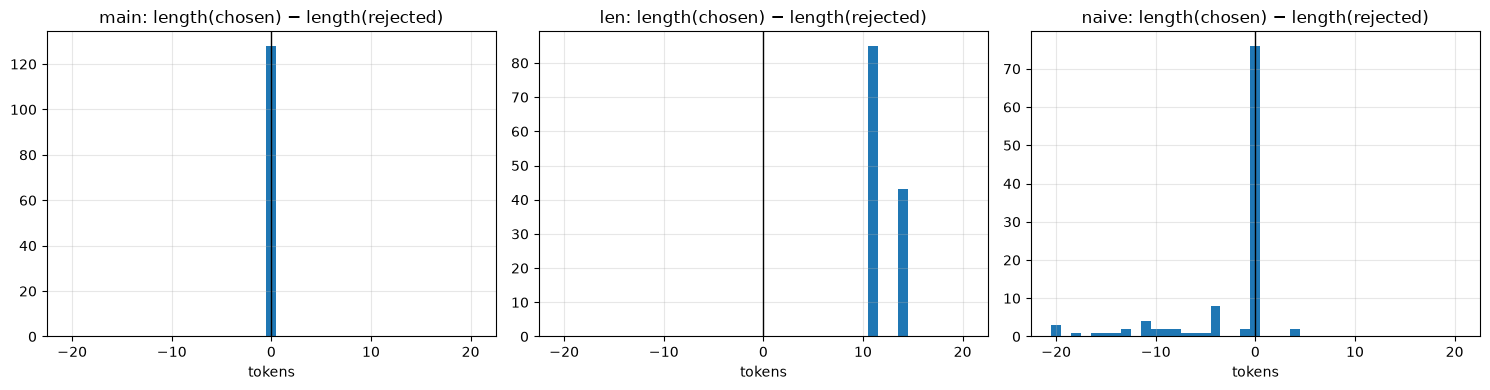

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axs, ["main", "len", "naive"]):
    gap = [len(encode(p["chosen"])) - len(encode(p["rejected"])) for p in PAIRS[k]]
    ax.hist(gap, bins=np.arange(-20.5, 21.5, 1), color="#1f77b4")
    ax.axvline(0, color="k", lw=1); ax.set_title(f"{k}: length(chosen) − length(rejected)", fontsize=12)
    ax.set_xlabel("tokens"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Что видно. Три набора различаются ровно тем, что задумано.

- В `main` средняя разница длин chosen и rejected равна 0,00 токена, chosen длиннее ни в одной паре: длина и стиль полностью сбалансированы. Цена — доля on-policy rejected только 40%: у остальных изображений не нашлось ошибочного сэмпла подходящей длины, и rejected построен синтетической подменой.
- В `naive` доля on-policy 70%, но chosen в среднем на 6,19 токена короче rejected и длиннее лишь в 2% пар. Причина в том, что худшие сэмплы модели — это часто длинные сэмплы с лишним предложением или лишними объектами. В rejected здесь в среднем 1,51 галлюцинации против 1,07 в `main`.
- В `len` chosen длиннее в 100% пар, в среднем на 12 токенов.

Гистограммы показывают то же самое. Модель, обученная на `naive`, получает два сигнала сразу: «не галлюцинируй» и «будь короче». Посмотрим в разделе 19, какой из них она выучит.

## 16. Функции потерь с нуля

Реализуем пять функций потерь по формулам из разделов 3 и 4. Все они принимают уже посчитанные логвероятности последовательностей, так что не зависят от модели.

- `dpo_loss` — $-\log\sigma(\beta h)$, с параметром `label_smoothing` для cDPO;
- `ipo_loss` — $(h - 1/(2\tau))^2$;
- `kto_loss` — ценность относительно опорной точки $z_0$ отдельно для желательных и нежелательных ответов;
- `orpo_loss` — NLL плюс $\lambda$ на логарифм отношения шансов по средним логвероятностям;
- `simpo_loss` — средние логвероятности без reference и запас $\gamma$.

Проверки в конце ячейки — значения, которые можно посчитать вручную: при $h = 0$ DPO равна $\log 2 \approx 0{,}693$; IPO равна нулю ровно при $h = 1/(2\tau)$; у ORPO при равных средних логвероятностях второй член равен $\lambda \log 2$.

In [14]:
def dpo_loss(pc, pr, rc, rr, beta=0.1, label_smoothing=0.0):
    """DPO: −log σ(β[(log π_c − log π_ref,c) − (log π_r − log π_ref,r)]). label_smoothing > 0 — conservative DPO."""
    h = beta * ((pc - rc) - (pr - rr))
    return -(1 - label_smoothing) * F.logsigmoid(h) - label_smoothing * F.logsigmoid(-h)

def ipo_loss(pc, pr, rc, rr, tau=0.1):
    """IPO: квадратичная регрессия разности лог-отношений к цели 1/(2τ)."""
    h = (pc - rc) - (pr - rr)
    return (h - 1 / (2 * tau)) ** 2

def kto_loss(p, r, desirable, z0, beta=0.1, lam_d=1.0, lam_u=1.0):
    """KTO: непарные примеры; ценность считается относительно опорной точки z0 ≈ KL(π‖π_ref)."""
    rr = p - r
    v = torch.where(desirable, lam_d * torch.sigmoid(beta * (rr - z0)), lam_u * torch.sigmoid(beta * (z0 - rr)))
    return torch.where(desirable, torch.full_like(v, lam_d), torch.full_like(v, lam_u)) - v

def orpo_loss(avg_c, avg_r, nll_c, lam=0.1):
    """ORPO: NLL на chosen + λ·(−log σ(log odds_c − log odds_r)); avg_* — средняя логвероятность токена (≤ 0)."""
    log_odds = lambda a: a - torch.log1p(-torch.exp(a).clamp(max=1 - 1e-6))
    return nll_c - lam * F.logsigmoid(log_odds(avg_c) - log_odds(avg_r))

def simpo_loss(avg_c, avg_r, beta=2.0, gamma=0.5):
    """SimPO: без reference, средние логвероятности и запас γ."""
    return -F.logsigmoid(beta * (avg_c - avg_r) - gamma)

# проверки свойств
z = torch.zeros(1)
print("DPO при π = π_ref:", f"{dpo_loss(z, z, z, z).item():.4f}", "= log 2 =", f"{math.log(2):.4f}")
pc = torch.tensor([0.0], requires_grad=True); pr = torch.tensor([0.0], requires_grad=True)
for m_ in [0.0, 10.0, 50.0]:
    pc.grad = pr.grad = None
    dpo_loss(pc + m_ / 2, pr - m_ / 2, z, z, beta=0.1).sum().backward()
    print(f"  разность лог-отношений {m_:4.0f}: вес градиента σ(−h) = {-pc.grad.item() / 0.1:.3f}")
print("IPO: минимум при h = 1/(2τ):", [round(1 / (2 * t), 2) for t in (0.1, 0.5, 1.0)], "для τ = 0.1, 0.5, 1.0")
print("ORPO при равных средних логвероятностях:", f"{orpo_loss(torch.tensor([-0.5]), torch.tensor([-0.5]), torch.tensor([0.5]), 0.1).item():.4f}",
      "= NLL + 0.1·log 2 =", f"{0.5 + 0.1 * math.log(2):.4f}")

DPO при π = π_ref: 0.6931 = log 2 = 0.6931
  разность лог-отношений    0: вес градиента σ(−h) = 0.500
  разность лог-отношений   10: вес градиента σ(−h) = 0.269
  разность лог-отношений   50: вес градиента σ(−h) = 0.007
IPO: минимум при h = 1/(2τ): [5.0, 1.0, 0.5] для τ = 0.1, 0.5, 1.0
ORPO при равных средних логвероятностях: 0.5693 = NLL + 0.1·log 2 = 0.5693


### 16.2. Игрушечная задача: куда уходит вероятность

Чтобы увидеть поведение функций потерь без шума нейросети, возьмём политику над шестью фиксированными ответами. Каждый ответ описан тремя признаками: соблюдён ли формат, есть ли галлюцинация, есть ли лишнее предложение. Политика лог-линейная: $\log \pi_w(y) = \log \pi_{\mathrm{ref}}(y) + \phi(y)^\top w - \log Z$, при $w = 0$ она совпадает с reference. Обучается всего три числа $w$, общие для всех ответов, как в настоящей модели, где параметры общие для всех последовательностей.

Ответы: «верный и краткий», «с галлюцинацией и краткий», «верный и многословный», «с галлюцинацией и многословный», «без формата» и «почти ничего не сказано». У последнего признаки подобраны так, что он максимально «не похож» на галлюцинацию. Данные — одна пара: «верный и краткий» ≻ «с галлюцинацией и краткий». Остальные ответы в данных не встречаются; вопрос в том, что метод сделает с ними (раздел 3.6).

In [15]:
# 6 ответов, 3 признака: [формат, галлюцинация, многословие]
TOY_Y = ["correct, concise", "hallucinated, concise", "correct, verbose", "hallucinated, verbose", "no format", "says almost nothing"]
PHI = torch.tensor([[1, 0, 0], [1, 1, 0], [1, 0, 1], [1, 1, 1], [0, 0, 0], [0.5, -1.5, 0]], dtype=torch.float32)
REF_P = torch.tensor([0.30, 0.30, 0.15, 0.10, 0.10, 0.05])
B0 = REF_P.log()
W_, L_ = 0, 1                                    # пара предпочтений: «верно и кратко» ≻ «с галлюцинацией»

def toy_run(method, steps=400, lr=0.05, **kw):
    w = torch.zeros(3, requires_grad=True)       # политика: logits = b0 + φ·w, при w = 0 совпадает с reference
    opt = torch.optim.Adam([w], lr=lr); hist = []
    for t in range(steps):
        logp = (B0 + PHI @ w).log_softmax(0); ref = B0.log_softmax(0)
        if method == "DPO":
            loss = dpo_loss(logp[W_], logp[L_], ref[W_], ref[L_], **kw)
        elif method == "IPO":
            loss = ipo_loss(logp[W_], logp[L_], ref[W_], ref[L_], **kw)
        elif method == "KTO":
            z0 = (logp.exp() * (logp - ref)).sum().detach().clamp(min=0)
            loss = kto_loss(logp[[W_, L_]], ref[[W_, L_]], torch.tensor([True, False]), z0, **kw).mean()
        elif method == "ORPO":
            loss = orpo_loss(logp[W_], logp[L_], -logp[W_], **kw)
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            p = logp.exp()
            hist.append(dict(step=t, margin=((logp[W_] - ref[W_]) - (logp[L_] - ref[L_])).item(),
                             kl=(p * (logp - ref)).sum().item(), **{y: p[i].item() for i, y in enumerate(TOY_Y)}))
    return pd.DataFrame(hist)

TOY = {"DPO β=0.1": toy_run("DPO", beta=0.1), "DPO β=1": toy_run("DPO", beta=1.0), "IPO τ=0.5": toy_run("IPO", tau=0.5),
       "KTO β=0.1": toy_run("KTO", beta=0.1), "ORPO λ=0.1": toy_run("ORPO", lam=0.1)}
final = pd.DataFrame({k: v.iloc[-1][TOY_Y + ["margin", "kl"]] for k, v in TOY.items()}).T
final.insert(0, "reference", None)
ref_row = pd.Series({**{y: REF_P[i].item() for i, y in enumerate(TOY_Y)}, "margin": 0.0, "kl": 0.0}, name="reference")
print(pd.concat([ref_row.to_frame().T, final.drop(columns="reference")]).astype(float).round(3).to_string())

            correct, concise  hallucinated, concise  correct, verbose  hallucinated, verbose  no format  says almost nothing  margin     kl
reference              0.300                  0.300             0.150                   0.10      0.100                0.050   0.000  0.000
DPO β=0.1              0.000                  0.000             0.000                   0.00      0.000                1.000  15.536  2.996
DPO β=1                0.004                  0.000             0.002                   0.00      0.001                0.993   4.944  2.940
IPO τ=0.5              0.326                  0.120             0.163                   0.04      0.109                0.243   1.000  0.287
KTO β=0.1              0.235                  0.000             0.000                   0.00      0.000                0.765  12.274  2.029
ORPO λ=0.1             0.903                  0.057             0.003                   0.00      0.000                0.036   2.767  0.877


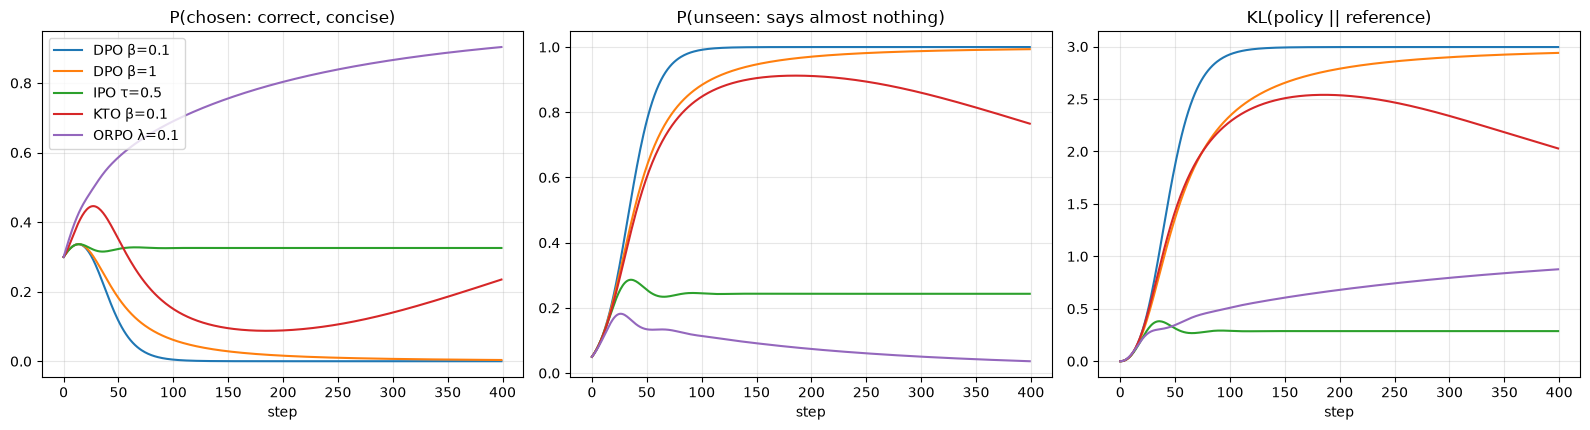

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
for k, v in TOY.items():
    axs[0].plot(v.step, v["correct, concise"], label=k)
    axs[1].plot(v.step, v["says almost nothing"], label=k)
    axs[2].plot(v.step, v.kl, label=k)
axs[0].set_title("P(chosen: correct, concise)", fontsize=12); axs[1].set_title("P(unseen: says almost nothing)", fontsize=12)
axs[2].set_title("KL(policy || reference)", fontsize=12)
for ax in axs:
    ax.set_xlabel("step"); ax.grid(alpha=0.3)
axs[0].legend(fontsize=10)
plt.tight_layout(); plt.show()

Что видно. Игрушечная задача воспроизводит главные теоретические эффекты.

- DPO при $\beta = 0{,}1$ и даже при $\beta = 1$ в итоге отдаёт почти всю вероятность ответу «says almost nothing» (1,000 и 0,993), которого нет в данных; вероятность chosen падает почти до нуля, KL около 3 нат. DPO выполняет свою цель: разность лог-отношений chosen и rejected растёт без предела (15,5 при $\beta = 0{,}1$). Но проще всего её увеличить, уходя в сторону, «противоположную» галлюцинации, а не поднимая chosen. Именно так в реальной модели возникают падение правдоподобия chosen и уход в непредусмотренные ответы (разделы 3.3 и 3.6).
- IPO останавливается ровно на целевой разности $1/(2\tau) = 1$, KL 0,287; вероятность chosen почти не меняется (0,326 против 0,300), зато rejected падает с 0,30 до 0,12.
- KTO ведёт себя похоже на DPO, но медленнее; к 400-му шагу вероятность chosen снова растёт (0,235), а у «says almost nothing» 0,765.
- ORPO благодаря NLL поднимает chosen до 0,903 при KL 0,877: это единственный метод, который явно тянет вверх хороший ответ.

Вывод: само по себе «chosen лучше rejected» не говорит, куда пойдёт вероятность. Нужны либо ограничение цели (IPO), либо якорь на chosen (NLL, ORPO), либо данные, покрывающие нежелательные ответы.

## 17. Reward model

Обучим две reward model по модели Брэдли–Терри (раздел 2.2): RM[main] — на парах `main`, RM[len] — на смещённых парах `len`. Чтобы обучение было быстрым, RM — это линейная голова поверх среднего скрытого состояния последнего слоя SFT-модели по токенам ответа; сама модель заморожена. Это слабая RM, но для нашей цели этого достаточно: показать, что RM выучивает ровно то, что было в данных.

Проверяем на двух тестовых наборах:

- «same style» — пары в одном стиле, где отличие только в галлюцинации (как `main`, но на других изображениях);
- «verbose hallucination» — chosen краткий и верный, rejected — с галлюцинацией и с лишним предложением. RM, которая выучила «длиннее — лучше», выберет rejected.

In [17]:
@torch.no_grad()
def rm_features(items, responses, bs=8):
    """Признак пары (изображение, ответ): среднее скрытых состояний последнего слоя по токенам ответа (модель заморожена)."""
    out = []
    for i in range(0, len(items), bs):
        ids, att, resp, f = make_batch(items[i:i + bs], responses[i:i + bs])
        emb = model.get_input_embeddings()(ids)
        emb = emb.masked_scatter((ids == IMAGE_TOKEN_ID).unsqueeze(-1), f.reshape(-1, f.shape[-1]))
        hs = model(inputs_embeds=emb, attention_mask=att, output_hidden_states=True).hidden_states[-1].float()
        m = resp.unsqueeze(-1).float()
        out.append(((hs * m).sum(1) / m.sum(1)).cpu())
    return torch.cat(out)

class RewardHead(nn.Module):
    def __init__(self, d):
        super().__init__(); self.lin = nn.Linear(d, 1)
    def forward(self, x):
        return self.lin(x).squeeze(-1)

def train_rm(pairs, epochs=300, lr=1e-2, wd=1e-3):
    """Bradley–Terry: −log σ(r(chosen) − r(rejected))."""
    fc = rm_features(pairs, [p["chosen"] for p in pairs]); fr = rm_features(pairs, [p["rejected"] for p in pairs])
    mu, sd = torch.cat([fc, fr]).mean(0), torch.cat([fc, fr]).std(0) + 1e-6
    rm = RewardHead(fc.shape[1]); opt = torch.optim.AdamW(rm.parameters(), lr=lr, weight_decay=wd)
    torch.manual_seed(SEED)
    for _ in range(epochs):
        loss = -F.logsigmoid(rm((fc - mu) / sd) - rm((fr - mu) / sd)).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    rm.eval(); rm.mu, rm.sd = mu, sd
    return rm, loss.item()

def rm_score(rm, items, responses):
    with torch.no_grad():
        return rm((rm_features(items, responses) - rm.mu) / rm.sd).numpy()

t0 = time.time()
RM = {}
for k in ["main", "len"]:
    RM[k], l = train_rm(PAIRS[k])
    print(f"RM на парах {k}: финальный BT-loss {l:.3f}")
# два тестовых набора пар на новых изображениях
rng = np.random.default_rng(7)
TEST_PAIRS = {
    "same style": [dict(e, chosen=describe(e["objects"]), rejected=describe(perturb(e["objects"], rng, rng.choice(["color", "shape"])))) for e in eval_set],
    "verbose hallucination": [dict(e, chosen=describe(e["objects"]), rejected=describe(perturb(e["objects"], rng, "color"), FILLERS[i % 3]))
                              for i, e in enumerate(eval_set)],
}
rows = {}
for k, rm in RM.items():
    rows[f"RM[{k}]"] = {name: float(np.mean(rm_score(rm, tp, [p["chosen"] for p in tp]) > rm_score(rm, tp, [p["rejected"] for p in tp])))
                        for name, tp in TEST_PAIRS.items()}
RM_ACC = pd.DataFrame(rows).T
print("\nточность RM (доля пар, где r(chosen) > r(rejected)):"); print(RM_ACC.round(3).to_string())
print(f"{time.time()-t0:.0f} с")

RM на парах main: финальный BT-loss 0.013


RM на парах len: финальный BT-loss 0.000



точность RM (доля пар, где r(chosen) > r(rejected)):
          same style  verbose hallucination
RM[main]       0.925                  0.875
RM[len]        0.600                  0.000
114 с


Что видно. RM[main] различает пары в одном стиле в 92,5% случаев и правильно отвергает многословную галлюцинацию в 87,5% случаев. RM[len] на парах в одном стиле почти угадывает (0,600), а многословную галлюцинацию предпочитает краткому верному ответу во всех тестовых парах (точность 0,000). На своих обучающих парах её BT-loss нулевой: она идеально выучила признак «длиннее — лучше», который в данных `len` полностью разделяет классы. Это RM, которая выглядит отлично на обучении и ошибается ровно там, где важно.

## 18. Best-of-n и reward hacking

Для каждого изображения отдельного набора генерируем 8 сэмплов SFT-модели и выбираем лучший по разным селекторам: RM[main], RM[len], оракул (знает разметку) и случайный выбор. Для $n \in \{1, 2, 4, 8\}$ смотрим, как меняются оценка самого селектора, CHAIR_s, длина и формат выбранных ответов. KL best-of-n до исходной политики известен аналитически: $\log n - (n - 1)/n$ (раздел 2.6).

Оценки разных RM на первом графике в своих шкалах, сравнивать их между собой по абсолютной величине нельзя; важен рост с $n$. Рост собственной оценки RM — это то, что «видит» оптимизатор. Остальные графики — то, что происходит на самом деле.

In [18]:
t0 = time.time()
bon_samples = generate(model, bon_set, n=BON_N, sample=True, temperature=1.0, seed=2)
flat_items = [e for e in bon_set for _ in range(BON_N)]
flat_txt = [s for ss in bon_samples for s in ss]
scores = {k: rm_score(rm, flat_items, flat_txt).reshape(len(bon_set), BON_N) for k, rm in RM.items()}
oracle = np.array([[-analyze(s, e["objects"])["halluc"] + 0.01 * analyze(s, e["objects"])["correct"] for s in ss] for e, ss in zip(bon_set, bon_samples)])
print(f"сэмплы и награды для best-of-n: {time.time()-t0:.0f} с")

BON = []
for n in [1, 2, 4, 8]:
    for sel, S in [("RM[main]", scores["main"]), ("RM[len]", scores["len"]), ("oracle", oracle)]:
        picks = [ss[int(np.argmax(S[i, :n]))] for i, ss in enumerate(bon_samples)]
        proxy = np.mean([S[i, :n].max() for i in range(len(bon_set))])
        BON.append(dict(n=n, selector=sel, KL_bound=math.log(n) - (n - 1) / n, proxy_reward=proxy, **summarize(picks, bon_set)))
BON = pd.DataFrame(BON)
print(BON.round(3).to_string(index=False))

сэмплы и награды для best-of-n: 111 с
 n selector  KL_bound  proxy_reward  format  CHAIR_i  CHAIR_s  recall  count acc  words
 1 RM[main]     0.000       -17.050   0.625    0.222    0.375   0.833      0.875 18.125
 1  RM[len]     0.000        -6.850   0.625    0.222    0.375   0.833      0.875 18.125
 1   oracle     0.000        -0.643   0.625    0.222    0.375   0.833      0.875 18.125
 2 RM[main]     0.193        -5.036   0.708    0.134    0.375   0.840      0.875 15.750
 2  RM[len]     0.193        -2.124   0.375    0.250    0.333   0.819      0.875 21.250
 2   oracle     0.193        -0.182   0.625    0.072    0.208   0.924      0.875 17.458
 4 RM[main]     0.636        -1.831   0.708    0.109    0.250   0.840      0.792 14.208
 4  RM[len]     0.636         1.688   0.208    0.284    0.417   0.806      0.833 23.792
 4   oracle     0.636        -0.014   0.583    0.015    0.042   0.969      0.833 16.500
 8 RM[main]     1.204         1.497   0.542    0.188    0.333   0.774      0.875 1

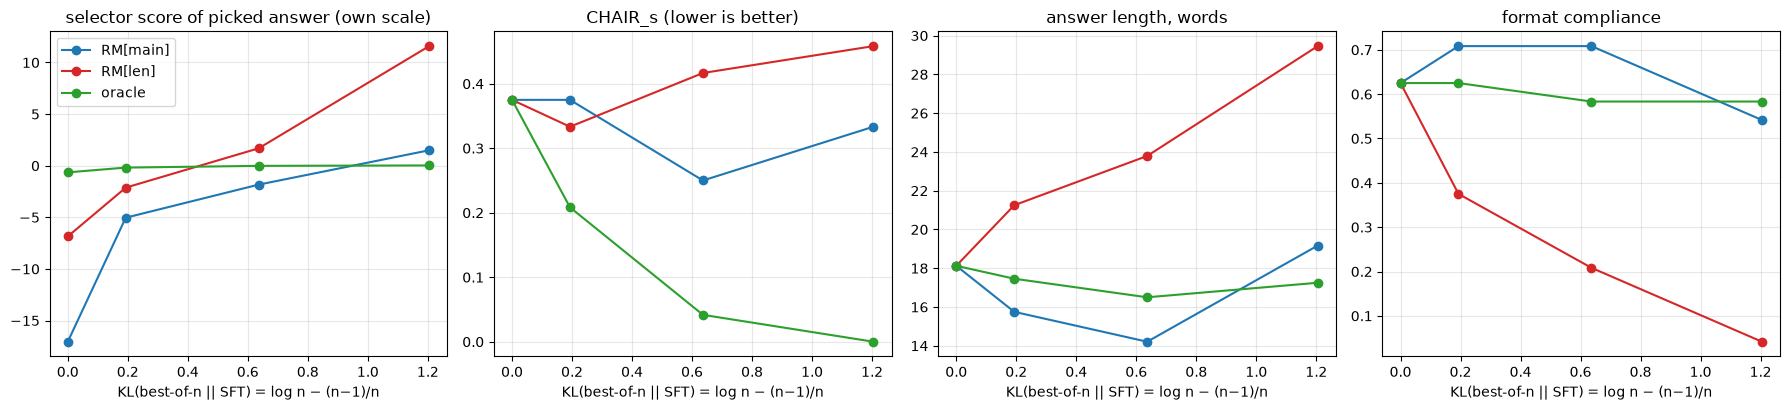

In [19]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4.2))
for sel, c in [("RM[main]", "#1f77b4"), ("RM[len]", "#d62728"), ("oracle", "#2ca02c")]:
    d = BON[BON.selector == sel]
    for ax, col in zip(axs, ["proxy_reward", "CHAIR_s", "words", "format"]):
        ax.plot(d.KL_bound, d[col], "o-", color=c, label=sel)
titles = ["selector score of picked answer (own scale)", "CHAIR_s (lower is better)", "answer length, words", "format compliance"]
for ax, t in zip(axs, titles):
    ax.set_title(t, fontsize=12); ax.set_xlabel("KL(best-of-n || SFT) = log n − (n−1)/n"); ax.grid(alpha=0.3)
axs[0].legend(fontsize=10)
plt.tight_layout(); plt.show()

Что видно. Это reward hacking в чистом виде, причём на очень малом KL (при $n = 8$ это 1,2 нат).

- Оценка RM[len] у выбранного ответа растёт с −6,9 до 11,6, то есть «по мнению» RM качество быстро улучшается. На самом деле CHAIR_s растёт с 0,375 до 0,458, длина — с 18 до 29,5 слова, формат падает с 0,625 до 0,042. Селектор нашёл то, что он вознаграждает, — длину.
- Оракул при тех же сэмплах снижает CHAIR_s до 0 уже при $n = 8$: хорошие ответы среди сэмплов есть, проблема только в селекторе.
- RM[main] сначала помогает (CHAIR_s 0,250 при $n = 4$), но при $n = 8$ CHAIR_s снова 0,333, а длина выросла до 19 слов. На 24 изображениях это может быть шумом, но направление совпадает с законами Гао: с ростом силы оптимизации даже приличная RM начинает ошибаться в пользу признаков, которые она плохо выучила.

## 19. Обучение по предпочтениям

### 19.1. Подготовка

Логвероятности reference для всех пар считаются один раз до обучения (как `precompute_ref_log_probs` в TRL). Для KTO пары разбираются на непарные примеры: chosen с меткой «желательный», rejected — «нежелательный»; опорная точка $z_0$ оценивается в каждом батче по несовпадающим парам «изображение — ответ» под reference и текущей политикой.

### 19.2. Запуски

Все методы обучают отдельный LoRA-адаптер поверх слитой SFT-модели с одинаковыми настройками (ранг 16, learning rate `LR_PREF`, 1 эпоха, если не указано иное):

| Запуск | Данные | Функция потерь | Что проверяем |
|---|---|---|---|
| DPO | main | DPO, $\beta = 0{,}1$ | базовый результат |
| DPO+NLL | main | DPO + NLL на chosen, $\alpha = 1$ | удерживает ли NLL правдоподобие chosen и формат |
| IPO | main | IPO, $\tau = 0{,}1$ | ограниченная цель |
| KTO | main без пар | KTO, $\beta = 0{,}1$ | можно ли обойтись непарными метками |
| ORPO | main | ORPO, $\lambda = 0{,}1$, без reference | NLL и отношение шансов |
| DPO-naive | naive | DPO | что даёт отсутствие контроля длины и стиля |
| DPO-len | len | DPO | смещение длины в данных |
| DPO-long | main | DPO, 4 эпохи | переоптимизация |

Learning rate подобран на пробных запусках: при 5e-5 одна эпоха почти не меняет модель, при 2e-4 логвероятность chosen падает примерно на 10 нат и формат ломается уже за одну эпоху. ORPO здесь стартует с SFT-модели, а не с базовой, чтобы сравнение было честным; в оригинальной постановке ORPO заменяет SFT.

На графике кривых обучения смотрите на изменение логвероятности chosen и rejected относительно reference. Нормальная картина: rejected падает, chosen остаётся около нуля. Тревожная: chosen падает на единицы и десятки нат.

In [20]:
@torch.no_grad()
def add_ref_logps(pairs, bs=8):
    """Логвероятности reference-модели (SFT) считаются один раз до обучения: π_ref не меняется."""
    for i in range(0, len(pairs), bs):
        ch = pairs[i:i + bs]
        lc = seq_logps(model, ch, [p["chosen"] for p in ch]); lr = seq_logps(model, ch, [p["rejected"] for p in ch])
        for p, a, b in zip(ch, lc.tolist(), lr.tolist()):
            p["ref_c"], p["ref_r"] = a, b

t0 = time.time()
for k in PAIRS:
    add_ref_logps(PAIRS[k])
print(f"reference log-probs для {sum(map(len, PAIRS.values()))} пар: {time.time()-t0:.0f} с")
print("средняя log π_ref: chosen", round(np.mean([p["ref_c"] for p in PAIRS["main"]]), 2),
      "| rejected", round(np.mean([p["ref_r"] for p in PAIRS["main"]]), 2), "| доля пар, где SFT уже предпочитает chosen:",
      round(np.mean([p["ref_c"] > p["ref_r"] for p in PAIRS["main"]]), 3))

# KTO: непарные примеры — chosen с меткой «хорошо», rejected с меткой «плохо», перемешанные
KTO_DATA = [dict(p, response=p["chosen"], desirable=True, ref=p["ref_c"]) for p in PAIRS["main"]] + \
           [dict(p, response=p["rejected"], desirable=False, ref=p["ref_r"]) for p in PAIRS["main"]]
KTO_DATA = [KTO_DATA[i] for i in np.random.default_rng(SEED).permutation(len(KTO_DATA))]

reference log-probs для 384 пар: 725 с
средняя log π_ref: chosen -2.56 | rejected -7.46 | доля пар, где SFT уже предпочитает chosen: 0.852


In [21]:
def pair_forward(m, batch, average=False):
    """Одним проходом считаем log π для chosen и rejected (батч из 2·mb последовательностей)."""
    lp = seq_logps(m, batch + batch, [p["chosen"] for p in batch] + [p["rejected"] for p in batch], average=average)
    return lp[:len(batch)], lp[len(batch):]

def pair_stats(pc, pr, rc, rr, beta):
    dc, dr = (pc - rc).detach(), (pr - rr).detach()
    return {"chosen Δlogp": dc.mean().item(), "rejected Δlogp": dr.mean().item(),
            "margin": (beta * (dc - dr)).mean().item(), "reward acc": (dc > dr).float().mean().item()}

def make_dpo(beta=0.1, label_smoothing=0.0, nll_alpha=0.0):
    """nll_alpha > 0 — DPO + NLL на chosen (в TRL: loss_type=["sigmoid", "sft"]): удерживает правдоподобие хороших ответов."""
    def fn(m, batch):
        pc, pr = pair_forward(m, batch)
        rc = torch.tensor([p["ref_c"] for p in batch], device=DEVICE); rr = torch.tensor([p["ref_r"] for p in batch], device=DEVICE)
        loss = dpo_loss(pc, pr, rc, rr, beta, label_smoothing).mean()
        if nll_alpha > 0:
            ntok = torch.tensor([len(encode(p["chosen"])) for p in batch], device=DEVICE)
            loss = loss + nll_alpha * (-pc / ntok).mean()
        return loss, {"loss": loss.item(), **pair_stats(pc, pr, rc, rr, beta)}
    return fn

def make_ipo(tau=0.1):
    def fn(m, batch):
        pc, pr = pair_forward(m, batch)
        rc = torch.tensor([p["ref_c"] for p in batch], device=DEVICE); rr = torch.tensor([p["ref_r"] for p in batch], device=DEVICE)
        loss = ipo_loss(pc, pr, rc, rr, tau).mean()
        return loss, {"loss": loss.item(), **pair_stats(pc, pr, rc, rr, 1.0)}
    return fn

def make_orpo(lam=0.1):
    def fn(m, batch):
        ac, ar = pair_forward(m, batch, average=True)
        loss = orpo_loss(ac, ar, -ac, lam).mean()
        return loss, {"loss": loss.item(), "chosen avg logp": ac.mean().item(), "rejected avg logp": ar.mean().item(),
                      "reward acc": (ac > ar).float().mean().item()}
    return fn

def make_kto(beta=0.1, lam_d=1.0, lam_u=1.0):
    def fn(m, batch):
        p = seq_logps(m, batch, [b["response"] for b in batch])
        r = torch.tensor([b["ref"] for b in batch], device=DEVICE)
        d = torch.tensor([b["desirable"] for b in batch], device=DEVICE)
        # опорная точка z0: KL на несовпадающих парах (изображение i, ответ i+1), без градиента, ≥ 0
        with torch.no_grad():
            shifted = [b["response"] for b in batch[1:] + batch[:1]]
            pk = seq_logps(m, batch, shifted)
            with m.disable_adapter():
                rk = seq_logps(m, batch, shifted)
            z0 = (pk - rk).mean().clamp(min=0)
        loss = kto_loss(p, r, d, z0, beta, lam_d, lam_u).mean()
        st = {"loss": loss.item(), "z0": z0.item()}
        if d.any():
            st["desirable Δlogp"] = (p - r)[d].mean().item()
        if (~d).any():
            st["undesirable Δlogp"] = (p - r)[~d].mean().item()
        return loss, st
    return fn

LR_PREF = 1e-4      # подобран на CPU-прогоне: 5e-5 почти не меняет модель, 2e-4 за одну эпоху ломает формат
RUNS = {   # имя: (данные, функция потерь, эпохи)
    "DPO":       (PAIRS["main"],  make_dpo(beta=0.1), 1),
    "DPO+NLL":   (PAIRS["main"],  make_dpo(beta=0.1, nll_alpha=1.0), 1),
    "IPO":       (PAIRS["main"],  make_ipo(tau=0.1), 1),
    "KTO":       (KTO_DATA,       make_kto(beta=0.1), 1),
    "ORPO":      (PAIRS["main"],  make_orpo(lam=0.1), 1),
    "DPO-naive": (PAIRS["naive"], make_dpo(beta=0.1), 1),
    "DPO-len":   (PAIRS["len"],   make_dpo(beta=0.1), 1),
    "DPO-long":  (PAIRS["main"],  make_dpo(beta=0.1), 4),
}
TRAIN_INFO = []
pm = None
for name, (data, fn, ep) in RUNS.items():
    seed_everything(SEED)
    if pm is None:
        pm = get_peft_model(model, lora_config(), adapter_name=name)
    else:
        pm.add_adapter(name, lora_config())
    pm.set_adapter(name)
    t0 = time.time()
    log = run_epochs(pm, data, fn, name, lr=LR_PREF, epochs=ep, mb=2 if name != "KTO" else 4)
    TRAIN_INFO.append(dict(run=name, examples=len(data), epochs=ep, opt_steps=len(log), minutes=(time.time() - t0) / 60))
print(pd.DataFrame(TRAIN_INFO).round(2).to_string(index=False))

DPO: 16 шагов, 1.7 мин | последний шаг: {'grad_norm': 0.866, 'loss': 0.528, 'chosen Δlogp': -0.131, 'rejected Δlogp': -3.855, 'margin': 0.372, 'reward acc': 1.0}


DPO+NLL: 16 шагов, 1.6 мин | последний шаг: {'grad_norm': 1.085, 'loss': 0.658, 'chosen Δlogp': 0.135, 'rejected Δlogp': -2.354, 'margin': 0.249, 'reward acc': 0.875}


IPO: 16 шагов, 1.7 мин | последний шаг: {'grad_norm': 101.199, 'loss': 5.522, 'chosen Δlogp': 0.055, 'rejected Δlogp': -3.165, 'margin': 3.22, 'reward acc': 1.0}


KTO: 32 шагов, 3.1 мин | последний шаг: {'grad_norm': 0.583, 'loss': 0.406, 'z0': 0.0, 'desirable Δlogp': -3.443, 'undesirable Δlogp': -7.37}


ORPO: 16 шагов, 1.7 мин | последний шаг: {'grad_norm': 0.383, 'loss': 0.083, 'chosen avg logp': -0.071, 'rejected avg logp': -0.565, 'reward acc': 1.0}


DPO-naive: 16 шагов, 1.8 мин | последний шаг: {'grad_norm': 0.825, 'loss': 0.427, 'chosen Δlogp': -1.385, 'rejected Δlogp': -13.186, 'margin': 1.18, 'reward acc': 0.875}


DPO-len: 16 шагов, 16.9 мин | последний шаг: {'grad_norm': 0.482, 'loss': 0.089, 'chosen Δlogp': 0.835, 'rejected Δlogp': -23.01, 'margin': 2.384, 'reward acc': 1.0}


DPO-long: 64 шагов, 6.6 мин | последний шаг: {'grad_norm': 0.541, 'loss': 0.066, 'chosen Δlogp': -20.878, 'rejected Δlogp': -63.461, 'margin': 4.258, 'reward acc': 1.0}
      run  examples  epochs  opt_steps  minutes
      DPO       128       1         16     1.65
  DPO+NLL       128       1         16     1.63
      IPO       128       1         16     1.68
      KTO       256       1         32     3.15
     ORPO       128       1         16     1.68
DPO-naive       128       1         16     1.78
  DPO-len       128       1         16    16.94
 DPO-long       128       4         64     6.63


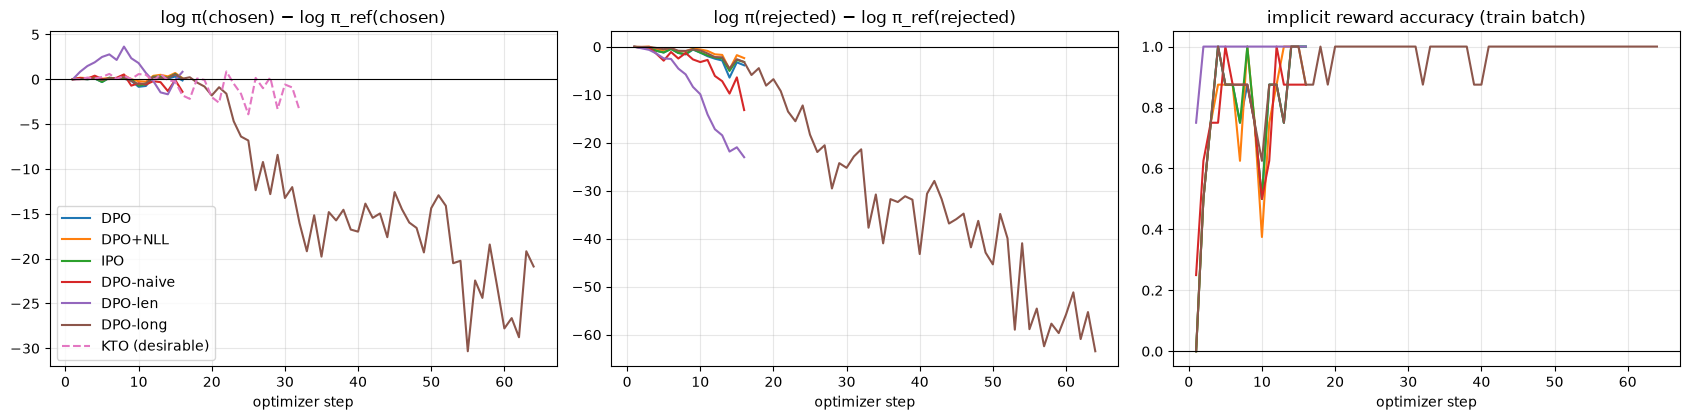

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.3))
for name in ["DPO", "DPO+NLL", "IPO", "DPO-naive", "DPO-len", "DPO-long"]:
    d = pd.DataFrame(LOGS[name])
    axs[0].plot(d.step, d["chosen Δlogp"], label=name); axs[1].plot(d.step, d["rejected Δlogp"], label=name)
    axs[2].plot(d.step, d["reward acc"], label=name)
for name, key in [("KTO", "desirable Δlogp")]:
    d = pd.DataFrame(LOGS[name]); axs[0].plot(d.step, d[key], "--", label=name + " (desirable)")
for ax, t in zip(axs, ["log π(chosen) − log π_ref(chosen)", "log π(rejected) − log π_ref(rejected)", "implicit reward accuracy (train batch)"]):
    ax.set_title(t, fontsize=12); ax.set_xlabel("optimizer step"); ax.grid(alpha=0.3); ax.axhline(0, color="k", lw=0.8)
axs[0].legend(fontsize=10)
plt.tight_layout(); plt.show()

Что видно на кривых обучения.

- DPO, DPO+NLL, IPO: логвероятность rejected падает на 2–4 нат, chosen остаётся около нуля (у DPO −0,13, у DPO+NLL +0,14). Это здоровый режим.
- DPO-naive: rejected падает на 13 нат, chosen на 1,4 нат. Разделять пары здесь проще, потому что rejected длиннее и в них больше галлюцинаций.
- DPO-len: rejected падает на 23 нат, а chosen даже растёт (+0,8). Модель нашла очень дешёвый способ разделить пары — длину, и accuracy неявной награды равна 1 уже с первых шагов.
- DPO-long (4 эпохи): после первой эпохи логвероятность chosen уходит вниз до −21 нат, rejected — до −63 нат. Accuracy неявной награды равна 1, loss 0,066, по всем метрикам обучения модель «отлично учится». Это ровно эффект Pal и соавторов: разность растёт, а сам хороший ответ становится маловероятным.
- KTO: на последнем шаге опорная точка $z_0$ равна нулю (оценка KL на несовпадающих парах отрицательна и обрезается нулём), и логвероятность желательных ответов к концу падает на 3,4 нат — KTO на наших данных тоже не удерживает chosen.

Замечание о времени. Расчёт reference-логвероятностей и запуск DPO-len в этом прогоне заняли 725 с и 16,9 мин, хотя на пробном запуске те же вычисления для 256 пар занимали 39 с, а остальные запуски шли по 1,6–1,8 мин на эпоху. Объём вычислений в DPO-len почти тот же, что в DPO; замедление, по-видимому, вызвано нагрузкой на машину во время прогона и не связано с методом.

### 19.3. Оценка

Для SFT и каждого адаптера считаем:

- метрики жадной генерации на оценочном наборе;
- те же метрики на 4 сэмплах при T = 1 на изображение: так видно поведение при сэмплировании, а выборка в 4 раза больше;
- KL до reference на токен по собственным жадным ответам модели;
- accuracy неявной награды на тестовых парах с правильным изображением и с изображением от другой пары (проверка из раздела 5.5);
- POPE на реальных фотографиях.

Win rate против SFT считается оракулом с ничьими как 0,5 и бутстреп-интервалом по изображениям; отдельно — «судьёй» RM[len], обученной на смещённых данных, чтобы показать, как плохой судья искажает выводы.

In [23]:
@torch.no_grad()
def kl_to_ref(m, items, answers, bs=8):
    """Средняя по токенам KL(π(·|префикс) ‖ π_ref(·|префикс)) на собственных ответах политики."""
    tot, n = 0.0, 0
    for i in range(0, len(items), bs):
        ids, att, resp, f = make_batch(items[i:i + bs], answers[i:i + bs])
        lp = forward_logits(m, ids, att, f)[:, :-1].float().log_softmax(-1)
        with m.disable_adapter():
            lr = forward_logits(m, ids, att, f)[:, :-1].float().log_softmax(-1)
        kl = (lp.exp() * (lp - lr)).sum(-1) * resp[:, 1:]
        tot += kl.sum().item(); n += resp[:, 1:].sum().item()
    return tot / n

@torch.no_grad()
def implicit_reward_acc(m, pairs, shuffle_images=False):
    """Доля тестовых пар, где неявная награда β·log(π/π_ref) выше у chosen; shuffle — с чужими изображениями."""
    items = pairs if not shuffle_images else [dict(p, feat=pairs[(i + 1) % len(pairs)]["feat"]) for i, p in enumerate(pairs)]
    acc = []
    for i in range(0, len(items), 8):
        b = items[i:i + 8]
        pc, pr = pair_forward(m, b)
        with m.disable_adapter():
            rc, rr = pair_forward(m, b)
        acc += ((pc - rc) > (pr - rr)).tolist()
    return float(np.mean(acc))

SAMP = {}          # имя → 4 сэмпла на каждое изображение eval_set (в одном списке)
EVAL_REP = [e for e in eval_set for _ in range(4)]
def sampled_summary(m, name, k=4, seed=11):
    """Те же метрики на k сэмплах при T = 1: так модель ведёт себя при сэмплировании, и выборка в k раз больше."""
    smp = generate(m, eval_set, n=k, sample=True, temperature=1.0, seed=seed)
    SAMP[name] = [a for ss in smp for a in ss]
    s = summarize(SAMP[name], EVAL_REP)
    return {"format T=1": s["format"], "CHAIR_s T=1": s["CHAIR_s"], "recall T=1": s["recall"], "words T=1": s["words"]}

t0 = time.time()
ROWS, EXTRA = {}, {}
names = ["base", "SFT"] + list(RUNS)
for name in names:
    if name in ("base", "SFT"):
        ans = EVAL[name]; row = dict(summarize(ans, eval_set), **POPE[name])
        row["KL/token"] = 0.0 if name == "SFT" else np.nan
        if name == "SFT":
            with pm.disable_adapter():
                row.update(sampled_summary(pm, name))
    else:
        pm.set_adapter(name)
        ans = EVAL[name] = generate(pm, eval_set)
        row = dict(summarize(ans, eval_set), **pope_eval(pm))
        row["KL/token"] = kl_to_ref(pm, eval_set, ans)
        row.update(sampled_summary(pm, name))
        EXTRA[name] = {"pair acc, true image": implicit_reward_acc(pm, TEST_PAIRS["same style"]),
                       "pair acc, shuffled image": implicit_reward_acc(pm, TEST_PAIRS["same style"], shuffle_images=True)}
    row["win vs SFT (oracle)"] = win_rate(ans, EVAL["SFT"], eval_set)
    ROWS[name] = row
print(f"оценка: {time.time()-t0:.0f} с")
TAB = pd.DataFrame(ROWS).T
cols = ["format", "CHAIR_i", "CHAIR_s", "recall", "count acc", "words", "win vs SFT (oracle)", "KL/token"]
print("жадная генерация:"); print(TAB[cols].round(3).to_string())
cols2 = ["format T=1", "CHAIR_s T=1", "recall T=1", "words T=1", "POPE acc", "POPE yes"]
print("\nсэмплирование T = 1 (4 ответа на изображение) и POPE:"); print(TAB[cols2].round(3).to_string())
print("\nнеявная награда на тестовых парах (чужие изображения — проверка, что предпочтение зависит от картинки):")
print(pd.DataFrame(EXTRA).T.round(3).to_string())

оценка: 1463 с
жадная генерация:
           format  CHAIR_i  CHAIR_s  recall  count acc   words  win vs SFT (oracle)  KL/token
base        0.000    0.048    0.050   0.390      0.000  11.400                0.200       NaN
SFT         1.000    0.074    0.200   0.933      0.975  12.875                0.500     0.000
DPO         0.900    0.083    0.225   0.917      0.875  13.100                0.450     0.084
DPO+NLL     0.975    0.092    0.225   0.921      0.950  12.950                0.488     0.046
IPO         0.975    0.083    0.225   0.925      0.900  12.975                0.475     0.037
KTO         0.925    0.056    0.150   0.931      0.925  12.875                0.512     0.089
ORPO        1.000    0.073    0.200   0.940      0.950  12.950                0.500     0.028
DPO-naive   0.800    0.056    0.125   0.796      0.675  11.225                0.362     0.228
DPO-len     0.000    0.137    0.375   0.931      0.725  35.975                0.100     0.183
DPO-long    0.000    0.295 

In [24]:
def win_scores(answers_a, answers_b, items):
    out = []
    for x, y, it in zip(answers_a, answers_b, items):
        ka, kb = judge_key(analyze(x, it["objects"])), judge_key(analyze(y, it["objects"]))
        out.append(1.0 if ka > kb else 0.5 if ka == kb else 0.0)
    return np.array(out)

boot_rng = np.random.default_rng(0)
CI = {}
def win_ci(s, groups=1):
    """Бутстреп по изображениям: при groups = 4 четыре сэмпла одного изображения переставляются вместе."""
    s = s.reshape(-1, groups).mean(1)
    bs = [s[boot_rng.integers(0, len(s), len(s))].mean() for _ in range(2000)]
    return np.percentile(bs, 2.5), np.percentile(bs, 97.5)

for name in names[2:]:
    g = win_scores(EVAL[name], EVAL["SFT"], eval_set); t = win_scores(SAMP[name], SAMP["SFT"], EVAL_REP)
    (gl, gh), (tl, th) = win_ci(g), win_ci(t, 4)
    CI[name] = {"greedy win": g.mean(), "greedy CI": f"[{gl:.2f}, {gh:.2f}]", "greedy W/T/L": f"{(g == 1).sum()}/{(g == .5).sum()}/{(g == 0).sum()}",
                "T=1 win": t.mean(), "T=1 CI": f"[{tl:.2f}, {th:.2f}]", "T=1 W/T/L": f"{(t == 1).sum()}/{(t == .5).sum()}/{(t == 0).sum()}"}
WIN = pd.DataFrame(CI).T
TAB["win vs SFT (oracle, T=1)"] = WIN["T=1 win"].astype(float)
print("win rate против SFT у оракула, 95% бутстреп-интервал по изображениям; W/T/L — победы/ничьи/поражения:")
print(WIN.to_string(float_format=lambda v: f"{v:.3f}"))

win rate против SFT у оракула, 95% бутстреп-интервал по изображениям; W/T/L — победы/ничьи/поражения:
          greedy win     greedy CI greedy W/T/L T=1 win        T=1 CI  T=1 W/T/L
DPO            0.450  [0.38, 0.53]       3/30/7   0.581  [0.52, 0.65]   53/80/27
DPO+NLL        0.487  [0.42, 0.55]       3/33/4   0.628  [0.57, 0.68]   56/89/15
IPO            0.475  [0.40, 0.55]       3/32/5   0.594  [0.54, 0.65]   50/90/20
KTO            0.512  [0.45, 0.59]       5/31/4   0.647  [0.59, 0.70]   61/85/14
ORPO           0.500  [0.44, 0.56]       3/34/3   0.603  [0.56, 0.65]  44/105/11
DPO-naive      0.362  [0.26, 0.46]      5/19/16   0.531  [0.45, 0.62]   61/48/51
DPO-len        0.100  [0.03, 0.20]       4/0/36   0.263  [0.19, 0.34]  28/28/104
DPO-long       0.175  [0.07, 0.30]       7/0/33   0.350  [0.25, 0.46]   54/4/102


In [25]:
# судья с перекосом: RM, обученная на парах с корреляцией длины (раздел 7)
with pm.disable_adapter():
    sft_r = rm_score(RM["len"], eval_set, EVAL["SFT"])
    JUDGE = {}
    for name in names:
        r = rm_score(RM["len"], eval_set, EVAL[name])
        same = np.array([a == b for a, b in zip(EVAL[name], EVAL["SFT"])]) | np.isclose(r, sft_r, atol=1e-4)
        JUDGE[name] = float(np.mean(np.where(same, 0.5, (r > sft_r).astype(float))))   # одинаковый ответ — ничья
TAB["win vs SFT (RM[len] judge)"] = pd.Series(JUDGE)
print(TAB[["words", "format", "CHAIR_s", "win vs SFT (oracle)", "win vs SFT (RM[len] judge)"]].round(3).to_string())

            words  format  CHAIR_s  win vs SFT (oracle)  win vs SFT (RM[len] judge)
base       11.400   0.000    0.050                0.200                       1.000
SFT        12.875   1.000    0.200                0.500                       0.500
DPO        13.100   0.900    0.225                0.450                       0.600
DPO+NLL    12.950   0.975    0.225                0.488                       0.500
IPO        12.975   0.975    0.225                0.475                       0.575
KTO        12.875   0.925    0.150                0.512                       0.562
ORPO       12.950   1.000    0.200                0.500                       0.438
DPO-naive  11.225   0.800    0.125                0.362                       0.375
DPO-len    35.975   0.000    0.375                0.100                       1.000
DPO-long    8.575   0.000    0.250                0.175                       0.850


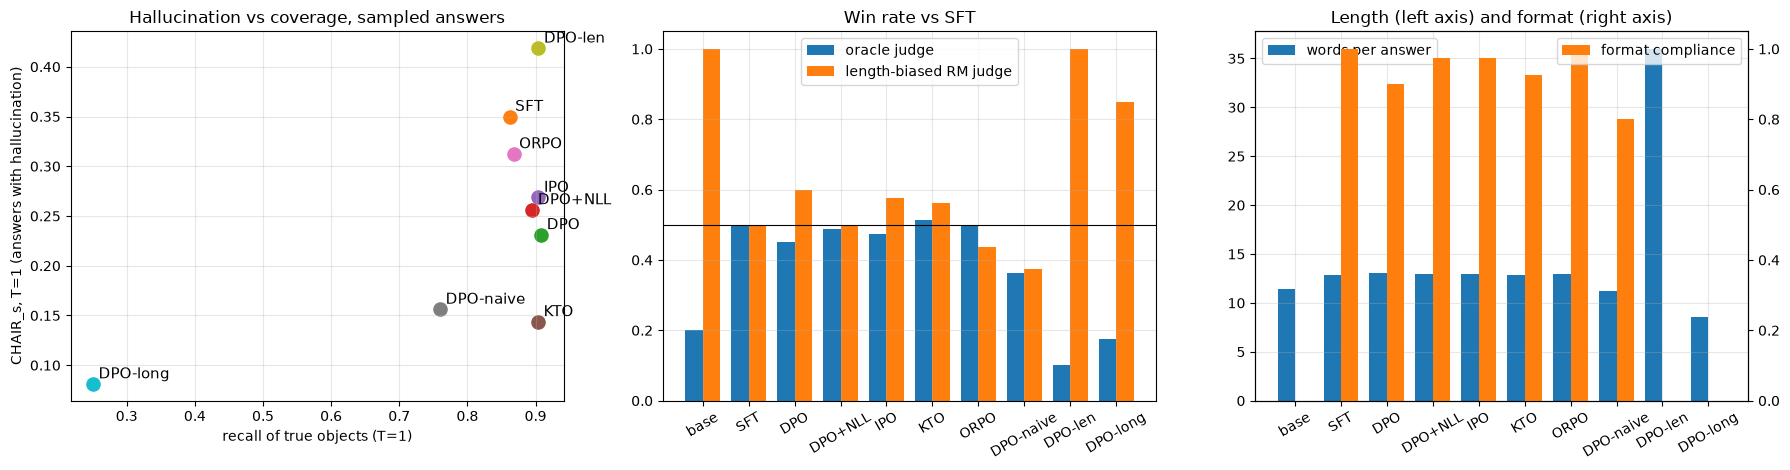

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))
colors = dict(zip(names, plt.cm.tab10.colors))
for n in names[1:]:
    xy = (TAB.loc[n, "recall T=1"], TAB.loc[n, "CHAIR_s T=1"])
    axs[0].scatter(*xy, s=90, color=colors[n]); axs[0].annotate(n, xy, fontsize=11, xytext=(4, 4), textcoords="offset points")
axs[0].set_xlabel("recall of true objects (T=1)"); axs[0].set_ylabel("CHAIR_s, T=1 (answers with hallucination)")
axs[0].set_title("Hallucination vs coverage, sampled answers", fontsize=12)
x = np.arange(len(names)); w = 0.38
axs[1].bar(x - w / 2, TAB["win vs SFT (oracle)"], w, label="oracle judge"); axs[1].bar(x + w / 2, TAB["win vs SFT (RM[len] judge)"], w, label="length-biased RM judge")
axs[1].axhline(0.5, color="k", lw=0.8); axs[1].set_xticks(x); axs[1].set_xticklabels(names, rotation=30); axs[1].set_title("Win rate vs SFT", fontsize=12); axs[1].legend(fontsize=10)
axs[2].bar(x - w / 2, TAB["words"], w, label="words per answer"); ax2 = axs[2].twinx(); ax2.bar(x + w / 2, TAB["format"], w, color="#ff7f0e", label="format compliance")
axs[2].set_xticks(x); axs[2].set_xticklabels(names, rotation=30); axs[2].set_title("Length (left axis) and format (right axis)", fontsize=12)
axs[2].legend(loc="upper left", fontsize=10); ax2.legend(loc="upper right", fontsize=10); ax2.set_ylim(0, 1.05)
for ax in axs:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Что видно в оценке. Выборка маленькая (40 изображений, 160 сэмплов), поэтому смотрим на интервалы и на согласованность нескольких метрик.

Жадная генерация почти не меняется у методов с контролируемыми данными. CHAIR_s у SFT 0,200, у DPO, DPO+NLL и IPO 0,225, у ORPO 0,200, у KTO 0,150; оракульный win rate против SFT у всех в интервале, накрывающем 0,5, причём 30–34 из 40 сравнений — ничьи. Причина: SFT уже предпочитает chosen в 85,2% пар, а жадный ответ — это мода распределения, которую короткое обучение не сдвигает.

При сэмплировании эффект хорошо виден. CHAIR_s при T = 1 падает с 0,350 у SFT до 0,231 у DPO, 0,256 у DPO+NLL, 0,269 у IPO и 0,144 у KTO; полнота при этом не падает (0,895–0,908 против 0,862), а формат растёт (0,688 у SFT, 0,794 у DPO, 0,881 у DPO+NLL, 0,919 у ORPO). Win rate при T = 1: DPO 0,581 [0,52; 0,65], IPO 0,594, ORPO 0,603, DPO+NLL 0,628 [0,57; 0,68], KTO 0,647 [0,59; 0,70]; нижняя граница интервала выше 0,5 у всех пяти. ORPO сильнее всех улучшает формат и слабее всех — галлюцинации (0,312), что согласуется с ролью NLL в её цели. Различия между пятью методами в пределах перекрывающихся интервалов; утверждать, что KTO «лучший», по этим данным нельзя.

Неконтролируемые и переобученные варианты показывают побочные эффекты из раздела 8.

- DPO-naive: CHAIR_s при T = 1 0,156, почти как у KTO, но полнота упала до 0,760, а длина до 11,1 слова. Модель выучила «короче» вместе с «правдивее», и win rate у оракула всего 0,531 [0,45; 0,62] с 51 поражением на 160 сэмплов. Если смотреть только на hallucination rate, этот запуск выглядел бы одним из лучших.
- DPO-len: длина выросла с 12,9 до 36 слов, формат упал до 0, CHAIR_s при T = 1 вырос до 0,419. Оракул: win rate 0,100 при жадной генерации.
- DPO-long: самый низкий CHAIR_s при T = 1 (0,081), но полнота 0,251, формат 0, KL на токен 3,24 против 0,03–0,09 у нормальных запусков, и на POPE доля «yes» скачком выросла с 0,167 до 0,517. Модель почти перестала описывать сцену («4 Blue Squares and a Red Ruler into 3»). Это деградация исходной задачи, которая формально «снижает галлюцинации».

Судья с перекосом. RM[len] в роли судьи даёт DPO-len win rate 1,000, DPO-long 0,850 и даже базовой модели 1,000 — ровно противоположно оракулу (0,100, 0,175 и 0,200). Вывод о качестве alignment не может быть надёжнее судьи.

Зависимость от изображения. Accuracy неявной награды на тестовых парах с правильным изображением у DPO-подобных методов 0,95–1,00, а с чужим изображением 0,65–0,70. Падение большое, значит предпочтение в основном опирается на изображение. Но оно не падает до 0,5: часть rejected выдают себя текстом (например, «star» вместо одной из трёх допустимых форм, повтор объекта), и это «текстовая» часть предпочтения, о которой предупреждает mDPO.

KL на токен упорядочивает запуски так же, как побочные эффекты: ORPO 0,028, IPO 0,037, DPO+NLL 0,046, DPO 0,084, KTO 0,089, DPO-len 0,183, DPO-naive 0,228, DPO-long 3,242. Запуски с наибольшим KL — те, где что-то сломалось.

### 19.4. Примеры ответов

Метрики стоит дополнять глазами. Ниже — ответы нескольких моделей на одни и те же изображения, где SFT ошибается, с разметкой: число галлюцинаций, полнота и соблюдение формата.

In [27]:
diff = [i for i in range(len(eval_set)) if len({EVAL[n][i] for n in ["SFT", "DPO", "DPO-len", "DPO-long"]}) > 1][:4]
for i in diff:
    print(f"--- истина: {', '.join(eval_set[i]['objects'])}")
    for n in ["SFT"] + list(RUNS):
        a = analyze(EVAL[n][i], eval_set[i]["objects"])
        print(f"  {n:9s} [halluc {a['halluc']}, recall {a['recall']:.2f}, format {a['format_ok']:.0f}] {EVAL[n][i][:150]}")

--- истина: red square
  SFT       [halluc 0, recall 1.00, format 1] There is 1 shape: a red square.
  DPO       [halluc 0, recall 1.00, format 0] There are 2 shapes: a red square and a red shape.
  DPO+NLL   [halluc 0, recall 1.00, format 1] There is 1 shape: a red square.
  IPO       [halluc 0, recall 1.00, format 1] There is 1 shape: a red square.
  KTO       [halluc 0, recall 1.00, format 1] There is 1 shape: a red square.
  ORPO      [halluc 0, recall 1.00, format 1] There is 1 shape: a red square.
  DPO-naive [halluc 0, recall 1.00, format 1] There is 1 shape: a red square.
  DPO-len   [halluc 1, recall 1.00, format 0] There are 2 shapes: a red square and a red circle. The shape is a square and the color is pink. The composition is simple and the objects do not overl
  DPO-long  [halluc 0, recall 1.00, format 0] A red Squat and a red Square.
--- истина: yellow square, blue triangle, blue square
  SFT       [halluc 0, recall 1.00, format 1] There are 3 shapes: a yellow square, a b

### 19.5. Выводы практикума

1. Preference optimization на маленьком наборе пар снижает галлюцинации там, где модель их совершает, — при сэмплировании (CHAIR_s при T = 1 с 0,350 до 0,14–0,27) — не снижая полноты и улучшая формат. Жадные ответы почти не меняются.
2. Данные определяют результат сильнее, чем выбор функции потерь. Пять методов на сбалансированных парах дали близкие результаты; та же DPO на `naive` выучила краткость, на `len` — многословие.
3. Метрики обучения (loss, accuracy неявной награды, margin) у переобученной DPO-long выглядят лучше всех, а модель сломана. Следить нужно за логвероятностью chosen, KL и метриками на генерации.
4. Hallucination rate без полноты, формата и длины обманывает: два «лучших» по CHAIR_s запуска (DPO-long и DPO-naive) — это деградация и укорачивание.
5. Смещённый судья (RM[len]) переворачивает выводы. Win rate нужно считать с ничьими и интервалами, а судью — проверять.
6. Числа получены на 256M-модели, синтетических сценах и 40 оценочных изображениях; на GPU с SmolVLM-500M и большими выборками они будут другими. Переносить стоит не числа, а процедуру проверки.

## 20. Экспорт данных, сохранение адаптера и перенос на большие модели

### 20.1. Адаптер

Сохраним адаптер DPO+NLL (только веса LoRA и конфигурацию) и проверим, что после загрузки под другим именем логиты совпадают. Базовую SFT-модель мы держим в памяти в слитом виде; в реальном проекте её нужно сохранить один раз (`save_pretrained`) или хранить SFT-адаптер отдельно, а preference-адаптер обучать поверх слитой SFT-модели, как здесь.

In [28]:
BEST = "DPO+NLL"
pm.save_pretrained(str(ART / "adapters"), selected_adapters=[BEST])
saved = next((ART / "adapters").rglob("adapter_model.safetensors"))
ADAPTER_SHA = hashlib.sha256(saved.read_bytes()).hexdigest()
print("адаптер:", saved.parent, f"| {saved.stat().st_size / 2**20:.1f} МБ | sha256 {ADAPTER_SHA[:16]}")
pm.load_adapter(str(saved.parent), adapter_name="reloaded")
b = PAIRS["main"][:2]
with torch.no_grad():
    pm.set_adapter(BEST); l1 = seq_logps(pm, b, [p["chosen"] for p in b])
    pm.set_adapter("reloaded"); l2 = seq_logps(pm, b, [p["chosen"] for p in b])
print("логвероятности после перезагрузки совпадают:", torch.allclose(l1, l2, atol=1e-4), l1.tolist(), l2.tolist())
pm.delete_adapter("reloaded"); pm.set_adapter(BEST)

адаптер: artifacts/adapters/DPO+NLL | 18.7 МБ | sha256 1994c4fc3a8be37f


логвероятности после перезагрузки совпадают: True [-0.14027298986911774, -0.023855501785874367] [-0.14027298986911774, -0.023855501785874367]


### 20.2. Экспорт пар в форматы TRL и LLaMA-Factory

Те же пары, что использовались для обучения, запишем в два формата.

- TRL: диалоговые поля `prompt`, `chosen`, `rejected` и колонка `images`, как в `HuggingFaceH4/rlaif-v_formatted` ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer)); для KTO — `prompt`, `completion`, `label` ([TRL KTOTrainer](https://huggingface.co/docs/trl/main/en/kto_trainer)).
- LLaMA-Factory: sharegpt с `"ranking": true`, сообщения `{"from": ..., "value": ...}`, объекты `chosen` и `rejected`, плейсхолдер `<image>` в тексте запроса и путь к файлу в `images`; для KTO — булево поле `kto_tag` ([LLaMA-Factory data README](https://github.com/hiyouga/LLaMA-Factory/blob/main/data/README.md)).

Вместе с данными сохраняется описание датасета для `dataset_info.json`.

In [29]:
EXP = ART / "pref_export"; (EXP / "images").mkdir(parents=True, exist_ok=True)
trl_rows, kto_rows, lf_rows, lf_kto = [], [], [], []
for i, p in enumerate(PAIRS["main"]):
    path = EXP / "images" / f"pref_{i:04d}.png"
    p["image"].save(path)
    prompt = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": QUESTION}]}]
    say = lambda t: [{"role": "assistant", "content": [{"type": "text", "text": t}]}]
    trl_rows.append({"images": [str(path)], "prompt": prompt, "chosen": say(p["chosen"]), "rejected": say(p["rejected"]),
                     "source": p["source"]})
    kto_rows += [{"images": [str(path)], "prompt": prompt, "completion": say(p["chosen"]), "label": True},
                 {"images": [str(path)], "prompt": prompt, "completion": say(p["rejected"]), "label": False}]
    conv = [{"from": "human", "value": "<image>" + QUESTION}]
    lf_rows.append({"conversations": conv, "chosen": {"from": "gpt", "value": p["chosen"]},
                    "rejected": {"from": "gpt", "value": p["rejected"]}, "images": [f"images/{path.name}"]})
    lf_kto += [{"conversations": conv + [{"from": "gpt", "value": p["chosen"]}], "kto_tag": True, "images": [f"images/{path.name}"]},
               {"conversations": conv + [{"from": "gpt", "value": p["rejected"]}], "kto_tag": False, "images": [f"images/{path.name}"]}]
for name, rows in [("trl_dpo.jsonl", trl_rows), ("trl_kto.jsonl", kto_rows)]:
    with open(EXP / name, "w") as f:
        f.writelines(json.dumps(r, ensure_ascii=False) + "\n" for r in rows)
json.dump(lf_rows, open(EXP / "shapes_dpo.json", "w"), ensure_ascii=False, indent=1)
json.dump(lf_kto, open(EXP / "shapes_kto.json", "w"), ensure_ascii=False, indent=1)
DATASET_INFO = {
    "shapes_dpo": {"file_name": "shapes_dpo.json", "formatting": "sharegpt", "ranking": True,
                   "columns": {"messages": "conversations", "chosen": "chosen", "rejected": "rejected", "images": "images"}},
    "shapes_kto": {"file_name": "shapes_kto.json", "formatting": "sharegpt",
                   "columns": {"messages": "conversations", "kto_tag": "kto_tag", "images": "images"}},
}
json.dump(DATASET_INFO, open(EXP / "dataset_info.json", "w"), indent=1)
print({p.name: f"{p.stat().st_size / 1024:.1f} КБ" for p in sorted(EXP.iterdir()) if p.is_file()}, "| изображений:", len(list((EXP / "images").glob("*.png"))))
print(json.dumps(lf_rows[0], ensure_ascii=False, indent=1))

# проверка: TRL-запись загружается библиотекой datasets
ensure("datasets")
from datasets import load_dataset
ds = load_dataset("json", data_files=str(EXP / "trl_dpo.jsonl"), split="train")
print(ds)

{'dataset_info.json': '0.4 КБ', 'shapes_dpo.json': '51.5 КБ', 'shapes_kto.json': '77.1 КБ', 'trl_dpo.jsonl': '63.3 КБ', 'trl_kto.jsonl': '90.1 КБ'} | изображений: 128
{
 "conversations": [
  {
   "from": "human",
   "value": "<image>Describe the shapes in the image in one sentence."
  }
 ],
 "chosen": {
  "from": "gpt",
  "value": "There are 2 shapes: a blue circle and a green circle."
 },
 "rejected": {
  "from": "gpt",
  "value": "There are 2 shapes: a blue circle and a green square."
 },
 "images": [
  "images/pref_0000.png"
 ]
}


Dataset({
    features: ['images', 'prompt', 'chosen', 'rejected', 'source'],
    num_rows: 128
})


### 20.3. Тот же эксперимент в TRL

Ниже — минимальная конфигурация `DPOTrainer` для Qwen3-VL-2B-Instruct с LoRA на наших экспортированных данных. Ячейка по умолчанию не выполняется (`RUN_TRL = False`): на CPU она слишком медленная, а на бесплатном T4 модель 2B в bf16 с LoRA и двумя проходами (chosen и rejected) требует аккуратного подбора длины и batch size. В сохранённом прогоне эта ячейка не запускалась, её параметры не проверены исполнением. Значения взяты из документации: $\beta = 0{,}1$, `max_length=None` для VLM, `precompute_ref_log_probs` ([TRL DPOTrainer](https://huggingface.co/docs/trl/main/en/dpo_trainer)), learning rate как в примере LLaMA-Factory для Qwen3-VL ([qwen3vl_lora_dpo.yaml](https://github.com/hiyouga/LLaMA-Factory/blob/main/examples/train_lora/qwen3vl_lora_dpo.yaml)).

Варианты меняются одной строкой: `loss_type="ipo"` для IPO; `loss_type=["sigmoid", "sft"]` с `loss_weights=[1.0, 1.0]` для DPO+NLL; `KTOTrainer` с `trl_kto.jsonl` для KTO; `trl.experimental.orpo.ORPOTrainer` для ORPO.

In [30]:
RUN_TRL = False
TRL_MODEL = "Qwen/Qwen3-VL-2B-Instruct"
if RUN_TRL and HAS_GPU:
    ensure("trl")
    from trl import DPOConfig, DPOTrainer
    from peft import LoraConfig
    proc = AutoProcessor.from_pretrained(TRL_MODEL)
    big = AutoModelForImageTextToText.from_pretrained(TRL_MODEL, dtype=torch.bfloat16, device_map="auto")
    train = load_dataset("json", data_files=str(EXP / "trl_dpo.jsonl"), split="train")
    train = train.map(lambda r: {"images": [Image.open(p).convert("RGB") for p in r["images"]]})
    cfg = DPOConfig(output_dir=str(ART / "trl_dpo"), beta=0.1, loss_type="sigmoid", learning_rate=5e-6,
                    num_train_epochs=1, per_device_train_batch_size=1, gradient_accumulation_steps=8,
                    max_length=None, precompute_ref_log_probs=True, bf16=True, gradient_checkpointing=True,
                    logging_steps=5, report_to="none")
    trainer = DPOTrainer(model=big, args=cfg, train_dataset=train, processing_class=proc,
                         peft_config=LoraConfig(r=8, lora_alpha=16, target_modules="all-linear", task_type="CAUSAL_LM"))
    trainer.train()
    # в логах смотрите rewards/chosen, rewards/rejected, rewards/margins, rewards/accuracies
else:
    print("RUN_TRL = False: ячейка показывает конфигурацию, обучение 2B-модели в этом прогоне не выполнялось")

RUN_TRL = False: ячейка показывает конфигурацию, обучение 2B-модели в этом прогоне не выполнялось


### 20.4. Конфигурация LLaMA-Factory

Файл ниже повторяет структуру примера `qwen3vl_lora_dpo.yaml` из репозитория LLaMA-Factory (Qwen3-VL-4B, `lora_rank: 8`, `pref_beta: 0.1`, `learning_rate: 5.0e-6`, `cutoff_len: 2048` — [qwen3vl_lora_dpo.yaml](https://github.com/hiyouga/LLaMA-Factory/blob/main/examples/train_lora/qwen3vl_lora_dpo.yaml)), но с моделью 2B и нашим датасетом. Чтобы запустить, положите каталог `pref_export` в `LLaMA-Factory/data` (или укажите `dataset_dir`) и выполните `llamafactory-cli train dpo_shapes.yaml`. Для IPO-подобных вариантов меняется `pref_loss` (`sigmoid`, `orpo`, `simpo`), для KTO — `stage: kto` и датасет `shapes_kto`.

In [31]:
import yaml
LF_CFG = {
    "model_name_or_path": "Qwen/Qwen3-VL-2B-Instruct", "image_max_pixels": 262144, "trust_remote_code": True,
    "stage": "dpo", "do_train": True, "finetuning_type": "lora", "lora_rank": 8, "lora_target": "all",
    "pref_beta": 0.1, "pref_loss": "sigmoid",
    "dataset": "shapes_dpo", "dataset_dir": str(EXP), "template": "qwen3_vl_nothink", "cutoff_len": 2048,
    "output_dir": "saves/qwen3vl-2b/lora/dpo_shapes", "logging_steps": 10, "save_steps": 500, "plot_loss": True,
    "per_device_train_batch_size": 1, "gradient_accumulation_steps": 8, "learning_rate": 5.0e-6, "num_train_epochs": 1.0,
    "lr_scheduler_type": "cosine", "warmup_ratio": 0.1, "bf16": True,
}
(EXP / "dpo_shapes.yaml").write_text(yaml.safe_dump(LF_CFG, sort_keys=False, allow_unicode=True))
print((EXP / "dpo_shapes.yaml").read_text())

model_name_or_path: Qwen/Qwen3-VL-2B-Instruct
image_max_pixels: 262144
trust_remote_code: true
stage: dpo
do_train: true
finetuning_type: lora
lora_rank: 8
lora_target: all
pref_beta: 0.1
pref_loss: sigmoid
dataset: shapes_dpo
dataset_dir: artifacts/pref_export
template: qwen3_vl_nothink
cutoff_len: 2048
output_dir: saves/qwen3vl-2b/lora/dpo_shapes
logging_steps: 10
save_steps: 500
plot_loss: true
per_device_train_batch_size: 1
gradient_accumulation_steps: 8
learning_rate: 5.0e-06
num_train_epochs: 1.0
lr_scheduler_type: cosine
warmup_ratio: 0.1
bf16: true



### 20.5. Конфигурация прогона

Всё, что нужно, чтобы воспроизвести числа этого блокнота: версии библиотек, ревизия модели, размеры выборок, гиперпараметры и итоговая таблица.

In [32]:
RUN_CONFIG = {
    "model": MODEL_ID, "revision": MODEL_REVISION, "device": DEVICE, "dtype": str(DTYPE), "fast_dev_run": FAST_DEV_RUN,
    "versions": VERSIONS, "python": platform.python_version(), "seed": SEED,
    "sizes": {"sft": len(sft_set), "pref": len(pref_set), "eval": len(eval_set), "bon": len(bon_set), "pope": len(pope_sub)},
    "sft": {"lora_r": 16, "lora_alpha": 32, "lr": 3e-4, "epochs": 1},
    "pref": {"lr": LR_PREF, "runs": {k: {"examples": len(v[0]), "epochs": v[2]} for k, v in RUNS.items()}},
    "pairs": PAIR_STATS.round(3).to_dict(orient="index"),
    "adapter_sha256": ADAPTER_SHA,
    "results": TAB.round(4).astype(object).where(TAB.notna(), None).to_dict(orient="index"),
}
(ART / "run_config.json").write_text(json.dumps(RUN_CONFIG, ensure_ascii=False, indent=1, default=str))
print(f"run_config.json: {(ART / 'run_config.json').stat().st_size / 1024:.1f} КБ")
print(json.dumps({k: RUN_CONFIG[k] for k in ["model", "revision", "device", "fast_dev_run", "versions", "sizes", "pref"]}, indent=1, default=str))

run_config.json: 5.9 КБ
{
 "model": "HuggingFaceTB/SmolVLM-256M-Instruct",
 "revision": "7e3e67edbbed1bf9888184d9df282b700a323964",
 "device": "cpu",
 "fast_dev_run": true,
 "versions": {
  "torch": "2.14.1+cpu",
  "transformers": "5.19.0",
  "peft": "0.21.2",
  "accelerate": "1.15.0",
  "numpy": "2.5.2"
 },
 "sizes": {
  "sft": 160,
  "pref": 128,
  "eval": 40,
  "bon": 24,
  "pope": 60
 },
 "pref": {
  "lr": 0.0001,
  "runs": {
   "DPO": {
    "examples": 128,
    "epochs": 1
   },
   "DPO+NLL": {
    "examples": 128,
    "epochs": 1
   },
   "IPO": {
    "examples": 128,
    "epochs": 1
   },
   "KTO": {
    "examples": 256,
    "epochs": 1
   },
   "ORPO": {
    "examples": 128,
    "epochs": 1
   },
   "DPO-naive": {
    "examples": 128,
    "epochs": 1
   },
   "DPO-len": {
    "examples": 128,
    "epochs": 1
   },
   "DPO-long": {
    "examples": 128,
    "epochs": 4
   }
  }
 }
}


# Контрольные вопросы

1. Почему SFT плохо различает правильное описание и то же описание с подменой одного объекта? Что в градиенте DPO меняет эту ситуацию?
2. Запишите модель Брэдли–Терри. Почему награда определена с точностью до сдвига, зависящего от $x$, и почему это не мешает ни RM, ни DPO?
3. Выведите оптимальную политику цели RLHF с KL-штрафом. Что происходит при $\beta \to 0$ и при $\beta \to \infty$? Может ли оптимальная политика дать ненулевую вероятность ответу с $\pi_{\mathrm{ref}} = 0$?
4. Выведите функцию потерь DPO. Куда делась нормировочная константа $Z(x)$?
5. Чему равен loss DPO в момент старта, если reference совпадает с политикой? Что означает, если в вашем логе на первом шаге другое значение?
6. Объясните, как DPO может снижать вероятность chosen и всё равно уменьшать loss. При каких парах это особенно вероятно? Назовите три способа с этим бороться.
7. Почему на конечной выборке DPO стремится раздвинуть лог-отношения бесконечно, а IPO — нет? Какой параметр IPO задаёт цель и как его значение зависит от того, суммируются или усредняются лог-вероятности?
8. Какие данные нужны KTO? Что такое опорная точка $z_0$ и как её оценивают в батче?
9. Чем ORPO отличается от DPO по данным, по reference и по месту в конвейере обучения?
10. Перечислите четыре источника rejected-ответов для VLM. Какие плюсы и минусы у on-policy и у синтетических негативов?
11. В датасете chosen в 98% пар короче rejected. Чему, скорее всего, научится модель? Как это проверить до обучения и после?
12. Что такое проблема безусловного предпочтения в мультимодальной DPO? Какой простой тест её выявляет?
13. Почему CHAIR нельзя публиковать без полноты и длины ответа? Приведите пример «улучшения», которое на самом деле ухудшение.
14. Как правильно учитывать ничьи в win rate? Почему на 40 примерах разница 0,55 против 0,50 ничего не доказывает?
15. Запишите KL-дивергенцию best-of-n. Почему даже best-of-n может взломать reward model? Что показал эксперимент в разделе 18?
16. Опишите законы переоптимизации Гао и соавторов. Что откладывается по оси абсцисс и почему это корень из KL?
17. Какие признаки в логах DPO говорят о том, что обучение пора остановить?

# Задания

### Задание 1. Масштаб эффекта (базовое)

Повторите обучение DPO с $\beta \in \{0{,}05;\ 0{,}1;\ 0{,}3;\ 1{,}0\}$ и двумя значениями learning rate. Постройте зависимости CHAIR_s (T = 1), полноты, формата и KL от $\beta$. Найдите режим, где галлюцинации снижаются, а формат и полнота не падают. Сравните методы при равном KL, а не при равном числе шагов.

### Задание 2. Длина как короткий путь (базовое)

Постройте четыре набора пар с контролируемой разницей длин: chosen короче на 6 токенов, равной длины, длиннее на 6 и на 12 токенов. Обучите на каждом DPO и SimPO (функция `simpo_loss` уже есть). Постройте длину ответов после обучения в зависимости от средней разницы длин в данных. Насколько SimPO устойчивее DPO?

### Задание 3. On-policy против синтетики (среднее)

Разделите пары на две группы: только on-policy rejected и только синтетические подмены. Обучите DPO на каждой (одинаковое число пар). Сравните CHAIR_s при сэмплировании, accuracy неявной награды на тестовых парах и KL. Объясните результат через вероятность rejected под reference-политикой.

### Задание 4. Итеративный DPO (среднее)

Реализуйте две итерации: после первой DPO сгенерируйте новые сэмплы обученной моделью, постройте пары тем же способом и обучите вторую итерацию, используя модель после первой как новую reference. Как меняется доля изображений с галлюцинирующими сэмплами между итерациями?

### Задание 5. mDPO (продвинутое)

Добавьте к DPO член условного предпочтения: тот же chosen с правильным изображением предпочтительнее, чем с чужим изображением (или с зашумлённым признаком). Проверьте, растёт ли разрыв между accuracy неявной награды с правильными и перемешанными изображениями.

### Задание 6. Перенос на Qwen3-VL-2B (продвинутое, GPU)

Используя экспорт из раздела 20, обучите Qwen3-VL-2B-Instruct через TRL или LLaMA-Factory на наших парах или на подмножестве RLHF-V. Сравните CHAIR и POPE до и после. Опишите, какие гиперпараметры пришлось изменить по сравнению с практикумом и почему.

# Источники

Обучение по предпочтениям и RLHF

- Christiano P. et al. Deep reinforcement learning from human preferences. 2017. https://arxiv.org/abs/1706.03741
- Stiennon N. et al. Learning to summarize from human feedback. 2020. https://arxiv.org/abs/2009.01325
- Ouyang L. et al. Training language models to follow instructions with human feedback (InstructGPT). 2022. https://arxiv.org/abs/2203.02155
- Schulman J. et al. Proximal Policy Optimization Algorithms. 2017. https://arxiv.org/abs/1707.06347
- Xu S. et al. Is DPO Superior to PPO for LLM Alignment? A Comprehensive Study. 2024. https://arxiv.org/abs/2404.10719

DPO и варианты

- Rafailov R. et al. Direct Preference Optimization: Your Language Model is Secretly a Reward Model. 2023. https://arxiv.org/abs/2305.18290
- Azar M. G. et al. A General Theoretical Paradigm to Understand Learning from Human Preferences (IPO). 2023. https://arxiv.org/abs/2310.12036
- Ethayarajh K. et al. KTO: Model Alignment as Prospect Theoretic Optimization. 2024. https://arxiv.org/abs/2402.01306
- Hong J., Lee N., Thorne J. ORPO: Monolithic Preference Optimization without Reference Model. 2024. https://arxiv.org/abs/2403.07691
- Meng Y., Xia M., Chen D. SimPO: Simple Preference Optimization with a Reference-Free Reward. 2024. https://arxiv.org/abs/2405.14734
- Pal A. et al. Smaug: Fixing Failure Modes of Preference Optimisation with DPO-Positive. 2024. https://arxiv.org/abs/2402.13228

Длина, reward hacking и побочные эффекты

- Gao L., Schulman J., Hilton J. Scaling Laws for Reward Model Overoptimization. 2022. https://arxiv.org/abs/2210.10760
- Rafailov R. et al. Scaling Laws for Reward Model Overoptimization in Direct Alignment Algorithms. 2024. https://arxiv.org/abs/2406.02900
- Skalse J. et al. Defining and Characterizing Reward Hacking. 2022. https://arxiv.org/abs/2209.13085
- Singhal P. et al. A Long Way to Go: Investigating Length Correlations in RLHF. 2023. https://arxiv.org/abs/2310.03716
- Park R. et al. Disentangling Length from Quality in Direct Preference Optimization. 2024. https://arxiv.org/abs/2403.19159
- Kirk R. et al. Understanding the Effects of RLHF on LLM Generalisation and Diversity. 2023. https://arxiv.org/abs/2310.06452
- Gekhman Z. et al. Does Fine-Tuning LLMs on New Knowledge Encourage Hallucinations? 2024. https://arxiv.org/abs/2405.05904

Preference-данные и галлюцинации VLM

- Sun Z. et al. Aligning Large Multimodal Models with Factually Augmented RLHF (LLaVA-RLHF, MMHal-Bench). 2023. https://arxiv.org/abs/2309.14525
- Yu T. et al. RLHF-V: Towards Trustworthy MLLMs via Behavior Alignment from Fine-grained Correctional Human Feedback. 2023. https://arxiv.org/abs/2312.00849
- Yu T. et al. RLAIF-V: Open-Source AI Feedback Leads to Super GPT-4V Trustworthiness. 2024. https://arxiv.org/abs/2405.17220
- Li L. et al. Silkie: Preference Distillation for Large Visual Language Models (VLFeedback). 2023. https://arxiv.org/abs/2312.10665
- Zhou Y. et al. Aligning Modalities in Vision Large Language Models via Preference Fine-tuning (POVID). 2024. https://arxiv.org/abs/2402.11411
- Zhao Z. et al. Beyond Hallucinations: Enhancing LVLMs through Hallucination-Aware Direct Preference Optimization (HA-DPO). 2023. https://arxiv.org/abs/2311.16839
- Wang F. et al. mDPO: Conditional Preference Optimization for Multimodal Large Language Models. 2024. https://arxiv.org/abs/2406.11839

Метрики

- Rohrbach A. et al. Object Hallucination in Image Captioning (CHAIR). 2018. https://arxiv.org/abs/1809.02156
- Li Y. et al. Evaluating Object Hallucination in Large Vision-Language Models (POPE). 2023. https://arxiv.org/abs/2305.10355
- Wang J. et al. AMBER: An LLM-free Multi-dimensional Benchmark for MLLMs Hallucination Evaluation. 2023. https://arxiv.org/abs/2311.07397
- Zheng L. et al. Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena. 2023. https://arxiv.org/abs/2306.05685
- Dubois Y. et al. Length-Controlled AlpacaEval: A Simple Way to Debias Automatic Evaluators. 2024. https://arxiv.org/abs/2404.04475
- Zhou J. et al. Instruction-Following Evaluation for Large Language Models (IFEval). 2023. https://arxiv.org/abs/2311.07911

Инструменты, модели и данные

- TRL DPOTrainer. https://huggingface.co/docs/trl/main/en/dpo_trainer
- TRL KTOTrainer. https://huggingface.co/docs/trl/main/en/kto_trainer
- TRL ORPOTrainer. https://huggingface.co/docs/trl/main/en/orpo_trainer
- LLaMA-Factory. https://github.com/hiyouga/LLaMA-Factory
- LLaMA-Factory, пример LoRA-DPO для Qwen3-VL. https://github.com/hiyouga/LLaMA-Factory/blob/main/examples/train_lora/qwen3vl_lora_dpo.yaml
- LLaMA-Factory, формат данных. https://github.com/hiyouga/LLaMA-Factory/blob/main/data/README.md
- SmolVLM-256M-Instruct. https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct
- SmolVLM-500M-Instruct. https://huggingface.co/HuggingFaceTB/SmolVLM-500M-Instruct
- POPE на Hugging Face (lmms-lab). https://huggingface.co/datasets/lmms-lab/POPE